# Phân tích khách hàng có khả năng rời bỏ dịch vụ và chính sách giữ chân

**Cell2Cell Customer Churn · Báo cáo phân tích khách hàng nội bộ · 27 tháng 10 năm 2026**

Tài liệu giúp ban quản lý xác định nhóm cần ưu tiên, các dấu hiệu liên quan đến churn và cách đo hiệu quả can thiệp. Kết quả mô tả dựa trên cohort quan sát; dữ liệu không cung cấp ngày snapshot và cửa sổ nhãn đủ tin cậy để gọi đây là tỷ lệ churn tháng hiện tại.

Notebook đọc dữ liệu bằng `empulse.datasets.fetch_cell2cell(backend=pd)`, giữ bản nguồn và mã khách hàng để đối soát, kiểm tra chất lượng, phân tích hành vi, xây dựng mô hình cảnh báo sớm, chấm điểm lịch sử và thiết kế chính sách giữ chân. Mọi kết quả và biểu đồ được tính lại khi chạy toàn bộ notebook. Báo cáo Word dùng chính các bảng kết quả này.

**Cách chạy:** giải nén gói dự án, đặt notebook tại thư mục gốc chứa `data` và `src`, cài `requirements.txt`, chọn kernel Python của môi trường dự án rồi Run All. Lần đầu cần mạng nếu chưa có cache. Các ô định nghĩa bên dưới ghi lại toàn bộ mã nguồn cần dùng, vì vậy notebook có thể khôi phục các module phân tích. Dữ liệu, mã nguồn, biểu đồ tương tác và tài liệu hướng dẫn đi kèm trong gói dự án.

In [1]:
from pathlib import Path
import os, sys, json, hashlib
BASE = Path.cwd().resolve()
if not (BASE / 'data').exists():
    raise FileNotFoundError('Mở notebook trong thư mục gốc của gói dự án có thư mục data.')
(BASE / 'src').mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(BASE / 'output' / '.matplotlib')
os.environ['PYTHONIOENCODING'] = 'utf-8'
sys.path.insert(0, str(BASE / 'src'))
RANDOM_STATE = 42
from IPython.display import display, Markdown, Image, IFrame
import pandas as pd
pd.set_option('display.max_columns', 60)
print('Thư mục dự án:', BASE)
print('Random state:', RANDOM_STATE)

Thư mục dự án: D:\trực quan
Random state: 42


## 1 Business Understanding

Quyết định cần hỗ trợ là thứ tự liên hệ khi năng lực retention chỉ đáp ứng một phần khách hàng. Quy trình phân tích đi từ chất lượng dữ liệu tới bức tranh churn, hồ sơ và hành vi, tương tác nhiều biến, xếp hạng dự báo, ưu tiên theo giá trị rồi kiểm nghiệm chính sách. Số churn và tỷ lệ churn được trình bày đồng thời với quy mô nhóm.

Thành công được đánh giá qua khả năng nhận diện churner ở top khách hàng ưu tiên và hiệu quả giữ chân tăng thêm trong thử nghiệm. Điểm dự báo không đo khả năng khách hàng sẽ phản hồi can thiệp. Do chưa có chi phí, biên lợi nhuận hoặc tác động can thiệp, dự án dùng doanh thu làm đại diện giá trị và không công bố CLV hay ROI ước đoán.

## 2 Mã nguồn có thể tái lập

Các ô dưới chứa toàn bộ xử lý dữ liệu, mô hình, trực quan hóa và ưu tiên khách hàng. `Pipeline` và `ColumnTransformer` bảo đảm các bước học từ dữ liệu chỉ fit trong tập huấn luyện. Bộ dữ liệu được ghim nguồn bằng commit và kiểm tra bằng SHA256.

### Mã nguồn runtime_compat.py

In [2]:
%%writefile src/runtime_compat.py
"""Narrow compatibility fix for Unicode virtualenv paths on Windows.

Some Windows module-enumeration APIs return a question mark for a non-ASCII
directory. Resolve only a missing virtualenv DLL path against the real sys.prefix;
do not suppress DLL errors or alter any library on disk.
"""
from pathlib import Path
import os
import sys


def repair_windows_threadpool_paths():
    if os.name != "nt":
        return
    from threadpoolctl import ThreadpoolController
    if getattr(ThreadpoolController, "_cell2cell_unicode_paths_repaired", False):
        return
    original = ThreadpoolController._make_controller_from_path

    def with_resolved_prefix(self, filepath):
        candidate = Path(filepath)
        marker = "\\Lib\\site-packages\\"
        if not candidate.exists() and marker.lower() in str(filepath).lower():
            remainder = str(filepath)[str(filepath).lower().index(marker.lower()) + len(marker):]
            repaired = Path(sys.prefix) / "Lib" / "site-packages" / remainder
            if repaired.is_file():
                filepath = str(repaired)
        return original(self, filepath)

    ThreadpoolController._make_controller_from_path = with_resolved_prefix
    ThreadpoolController._cell2cell_unicode_paths_repaired = True


Overwriting src/runtime_compat.py


### Mã nguồn analysis_models.py

In [3]:
%%writefile src/analysis_models.py
"""Reproducible, leakage-aware Cell2Cell modelling and historical risk scoring.

Run from the project root with .venv/Scripts/python.exe src/analysis_models.py.
All selection uses validation only; final test results are written once afterwards.
"""
from __future__ import annotations

import hashlib
import importlib.metadata
import json
import math
import time
import inspect
from pathlib import Path

try:
    from .runtime_compat import repair_windows_threadpool_paths
except ImportError:
    from runtime_compat import repair_windows_threadpool_paths
repair_windows_threadpool_paths()

import joblib
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss, confusion_matrix,
    f1_score, log_loss, precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

RANDOM_STATE = 42
BASE = Path(__file__).resolve().parents[1]
DATA = BASE / "data"
OUT = BASE / "output" / "analysis"
TARGET = "Churn"
ID = "CustomerID"
RETENTION = ["RetentionCalls", "RetentionOffersAccepted", "MadeCallToRetentionTeam"]
EXCLUDED_IDENTIFIERS = [ID, "ServiceArea"]


def native(value):
    if isinstance(value, dict):
        return {str(k): native(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [native(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return None if not np.isfinite(value) else float(value)
    if isinstance(value, Path):
        return str(value)
    return value


def write_json(path, value):
    path.write_text(json.dumps(native(value), ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")


def feature_engineering(frame):
    """Only row-local arithmetic: no statistics or fitted thresholds from held-out data."""
    x = frame.drop(columns=[c for c in [TARGET, *EXCLUDED_IDENTIFIERS, *RETENTION] if c in frame]).copy()
    definitions = []
    for col in ["AgeHH1", "AgeHH2"]:
        if col in x:
            x[col] = pd.to_numeric(x[col], errors="coerce").replace(0, np.nan)
            definitions.append({"feature": col, "formula": "0 is not an adult household age: treated as unknown and imputed within train with a missing indicator."})
    if "IncomeGroup" in x:
        codes = pd.to_numeric(x["IncomeGroup"], errors="coerce")
        x["IncomeGroup"] = codes.map(lambda value: "Unknown" if pd.isna(value) or value == 0 else f"Group {value:g}")
        definitions.append({"feature": "IncomeGroup", "formula": "0 -> Unknown; other codes treated as categories to avoid an assumed equal income gap."})
    if "HandsetPrice" in x:
        x["HandsetPrice"] = pd.to_numeric(x["HandsetPrice"], errors="coerce")
        definitions.append({"feature": "HandsetPrice", "formula": "Numeric price; Unknown -> missing; train median imputation plus missing indicator. Currency not specified."})
    recipes = [
        ("revenue_per_minute", "MonthlyRevenue", "MonthlyMinutes", 1.0),
        ("active_sub_ratio", "ActiveSubs", "UniqueSubs", 1.0),
        ("care_calls_per_1000_minutes", "CustomerCareCalls", "MonthlyMinutes", 1000.0),
        ("quality_calls_per_1000_minutes", "DroppedBlockedCalls", "MonthlyMinutes", 1000.0),
    ]
    for name, numerator, denominator, factor in recipes:
        if numerator in x and denominator in x:
            x[name] = factor * x[numerator] / x[denominator].replace(0, np.nan)
            definitions.append({"feature": name, "formula": f"{factor:g} * {numerator} / {denominator}; denominator=0 -> missing"})
    for col in x:
        if pd.api.types.is_numeric_dtype(x[col]):
            x[col] = pd.to_numeric(x[col], errors="coerce").replace([np.inf, -np.inf], np.nan).astype(float)
        else:
            x[col] = x[col].astype(object).where(x[col].notna(), np.nan)
    return x, definitions


def preprocess(x):
    numeric = x.select_dtypes(include="number").columns.tolist()
    categorical = [c for c in x if c not in numeric]
    return ColumnTransformer([
        ("numeric", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())]), numeric),
        ("categorical", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")), ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical),
    ], remainder="drop", verbose_feature_names_out=True), numeric, categorical


def model_candidates(x):
    prep, numeric, categorical = preprocess(x)
    candidates = {
        "Logistic Regression": LogisticRegression(C=0.7, max_iter=2000, solver="lbfgs", random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=240, max_depth=15, min_samples_leaf=20, max_features="sqrt", n_jobs=4, random_state=RANDOM_STATE),
        "Histogram Gradient Boosting": HistGradientBoostingClassifier(max_iter=240, learning_rate=0.06, max_leaf_nodes=15, l2_regularization=8.0, min_samples_leaf=40, early_stopping=False, random_state=RANDOM_STATE),
    }
    return {name: Pipeline([("preprocess", clone(prep)), ("model", classifier)]) for name, classifier in candidates.items()}, numeric, categorical


def metric_row(y, p, threshold=0.5):
    predicted = np.asarray(p) >= threshold
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold), "n": len(y), "churn_count": int(np.sum(y)),
        "churn_rate": float(np.mean(y)), "accuracy": accuracy_score(y, predicted),
        "precision": precision_score(y, predicted, zero_division=0),
        "recall": recall_score(y, predicted, zero_division=0), "f1": f1_score(y, predicted, zero_division=0),
        "roc_auc": roc_auc_score(y, p), "pr_auc_average_precision": average_precision_score(y, p),
        "brier_score": brier_score_loss(y, p), "log_loss": log_loss(y, p),
        "targeted_n": int(np.sum(predicted)), "targeted_fraction": float(np.mean(predicted)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


def targeting_table(y, p, fractions=(.05, .1, .2, .3)):
    y = np.asarray(y)
    order = np.argsort(-np.asarray(p), kind="stable")
    n = len(y)
    rows = []
    for fraction in fractions:
        k = math.ceil(n * fraction)
        churn = int(y[order[:k]].sum())
        precision = churn / k
        rows.append({"capacity": fraction, "customers": k, "actual_churn": churn, "precision": precision, "capture_recall": churn / y.sum(), "lift": precision / y.mean(), "minimum_score": float(np.asarray(p)[order[k - 1]])})
    return pd.DataFrame(rows)


def decile_table(y, p):
    y = np.asarray(y)
    order = np.argsort(-np.asarray(p), kind="stable")
    chunks = np.array_split(order, 10)
    rows, cumulative_churn, cumulative_n = [], 0, 0
    for i, chunk in enumerate(chunks, 1):
        churn = int(y[chunk].sum())
        cumulative_churn += churn
        cumulative_n += len(chunk)
        rows.append({"decile": i, "customers": len(chunk), "actual_churn": churn, "churn_rate": churn / len(chunk), "min_probability": float(np.min(np.asarray(p)[chunk])), "max_probability": float(np.max(np.asarray(p)[chunk])), "cumulative_customers": cumulative_n, "cumulative_fraction": cumulative_n / len(y), "cumulative_capture": cumulative_churn / y.sum(), "cumulative_lift": (cumulative_churn / cumulative_n) / y.mean()})
    return pd.DataFrame(rows)


def curve_tables(y, p, prefix):
    fpr, tpr, thresholds = roc_curve(y, p)
    pd.DataFrame({"false_positive_rate": fpr, "true_positive_rate": tpr, "threshold": thresholds}).to_csv(OUT / f"{prefix}_roc.csv", index=False)
    precision, recall, thresholds = precision_recall_curve(y, p)
    pd.DataFrame({"precision": precision, "recall": recall, "threshold": np.append(thresholds, np.nan)}).to_csv(OUT / f"{prefix}_pr.csv", index=False)
    fraction_positive, mean_predicted = calibration_curve(y, p, n_bins=10, strategy="quantile")
    pd.DataFrame({"mean_predicted_probability": mean_predicted, "observed_churn_rate": fraction_positive}).to_csv(OUT / f"{prefix}_calibration.csv", index=False)


def bootstrap_metrics(y, p, repetitions=400):
    """Uncertainty on untouched test ranking; no model selection or threshold tuning."""
    y, p = np.asarray(y), np.asarray(p)
    rng = np.random.default_rng(RANDOM_STATE)
    result = []
    for _ in range(repetitions):
        idx = rng.integers(0, len(y), len(y))
        top = targeting_table(y[idx], p[idx], fractions=(.1,)).iloc[0]
        result.append([roc_auc_score(y[idx], p[idx]), average_precision_score(y[idx], p[idx]), top.precision, top.capture_recall, top.lift])
    samples = np.asarray(result)
    return {name: {"lower_95": np.quantile(samples[:, i], .025), "upper_95": np.quantile(samples[:, i], .975)} for i, name in enumerate(["roc_auc", "pr_auc_average_precision", "precision_top10", "capture_top10", "lift_top10"])}


def acquire():
    """Use the user's official loader and preserve its unprocessed cached source."""
    from empulse.datasets import fetch_cell2cell
    from empulse.datasets._remote import _CELL2CELL_URL
    from empulse.datasets._process import process_cell2cell, _snake_case_column_name
    cache_home = DATA / "empulse_cache"
    dataset = fetch_cell2cell(backend=pd, data_home=cache_home)
    cache = cache_home / "cell2cell.csv.gz"
    raw = pd.read_csv(cache)
    raw.to_csv(DATA / "cell2cell_raw.csv", index=False)
    features, target = dataset.data.reset_index(drop=True), dataset.target.reset_index(drop=True)
    features.to_csv(DATA / "cell2cell_features.csv", index=False)
    pd.DataFrame({TARGET: target}).to_csv(DATA / "cell2cell_target.csv", index=False)
    # Preserve the official native matrix above, while restoring the upstream column
    # labels in the project analysis table through a verified one-to-one name map.
    source_name_map = {_snake_case_column_name(c): c for c in raw.columns}
    if any(c not in source_name_map for c in features.columns):
        raise ValueError("The loader returned a feature without a source-column name match.")
    features = features.rename(columns=source_name_map)
    retained = raw.loc[pd.to_numeric(raw["MonthlyRevenue"], errors="coerce").notna()].reset_index(drop=True)
    if len(retained) != len(features):
        raise ValueError("Cannot restore CustomerID: loader row count differs from MonthlyRevenue filter.")
    mapped_target = retained[TARGET].astype(str).str.lower().map({"yes": 1, "no": 0, "1": 1, "0": 0})
    np.testing.assert_array_equal(mapped_target.to_numpy(), np.asarray(target))
    for col in ["MonthlyRevenue", "MonthsInService", "MonthlyMinutes"]:
        if col in features:
            np.testing.assert_allclose(pd.to_numeric(retained[col], errors="coerce"), pd.to_numeric(features[col], errors="coerce"), equal_nan=True)
    frame = features.copy()
    frame.insert(0, ID, retained[ID].to_numpy())
    frame[TARGET] = np.asarray(target, dtype=int)
    frame.to_csv(DATA / "cell2cell_analysis.csv", index=False)
    raw_missing = raw.isna().sum().sort_values(ascending=False)
    clean_missing = frame.isna().sum().sort_values(ascending=False)
    pd.DataFrame({"feature": raw_missing.index, "missing_count": raw_missing.values, "missing_fraction": raw_missing.values / len(raw)}).to_csv(OUT / "raw_missing.csv", index=False)
    pd.DataFrame({"feature": clean_missing.index, "missing_count": clean_missing.values, "missing_fraction": clean_missing.values / len(frame)}).to_csv(OUT / "analysis_missing.csv", index=False)
    audit = {
        "source_url": _CELL2CELL_URL, "raw_file": "data/cell2cell_raw.csv", "analysis_file": "data/cell2cell_analysis.csv",
        "raw_rows": len(raw), "raw_columns": raw.shape[1], "loader_rows": len(frame), "loader_feature_count": features.shape[1],
        "analysis_columns_with_id_and_target": frame.shape[1], "raw_target_counts": raw[TARGET].value_counts().to_dict(),
        "churn_count": int(frame[TARGET].sum()), "churn_rate": float(frame[TARGET].mean()),
        "raw_duplicate_rows": int(raw.duplicated().sum()), "raw_duplicate_id": int(raw[ID].duplicated().sum()),
        "analysis_duplicate_rows": int(frame.duplicated().sum()), "analysis_duplicate_id": int(frame[ID].duplicated().sum()),
        "rows_removed_missing_monthly_revenue": len(raw) - len(frame),
        "removed_churn_count": int(raw.loc[raw["MonthlyRevenue"].isna(), TARGET].eq("Yes").sum()),
        "raw_sha256": hashlib.sha256((DATA / "cell2cell_raw.csv").read_bytes()).hexdigest(),
        "source_cache_sha256": hashlib.sha256(cache.read_bytes()).hexdigest(),
        "source_cache_file": "data/empulse_cache/cell2cell.csv.gz",
        "analysis_sha256": hashlib.sha256((DATA / "cell2cell_analysis.csv").read_bytes()).hexdigest(),
        "loader_description": dataset.DESCR,
        "loader_column_name_mapping": {c: source_name_map[c] for c in dataset.data.columns},
        "loader_transformations": "Removes rows without MonthlyRevenue; maps Churn to 0/1; removes CustomerID from predictors; converts feature names to snake_case; converts numeric fields and null tokens. Project analysis table restores source column names with verified one-to-one mapping and CustomerID by retained row order.",
        "currency_and_observation_date": "Currency and observation dates/horizon are not supplied; do not label values VND or current monthly churn.",
        "cost_defaults_used": False,
    }
    write_json(OUT / "data_manifest.json", audit)
    schema = pd.DataFrame({"feature": frame.columns, "dtype": [str(frame[c].dtype) for c in frame], "unique_count": [frame[c].nunique(dropna=True) for c in frame], "missing_count": frame.isna().sum().values})
    schema.to_csv(OUT / "schema.csv", index=False)
    (OUT / "empulse_loader_description.txt").write_text(dataset.DESCR, encoding="utf-8")
    (OUT / "empulse_loader_processing_source.py").write_text(inspect.getsource(process_cell2cell), encoding="utf-8")
    return frame, audit


def run():
    DATA.mkdir(exist_ok=True)
    OUT.mkdir(parents=True, exist_ok=True)
    started = time.time()
    print("Acquiring and auditing the official Cell2Cell loader output...", flush=True)
    frame, data_audit = acquire()
    print(json.dumps({k: data_audit[k] for k in ["raw_rows", "loader_rows", "loader_feature_count", "churn_count", "churn_rate"]}), flush=True)
    x, definitions = feature_engineering(frame)
    if any("retention" in c.lower() for c in x):
        raise AssertionError("A retention variable survived early-warning feature exclusion.")
    if ID in x or "ServiceArea" in x or TARGET in x:
        raise AssertionError("Identifier or target survived early-warning feature exclusion.")
    y = frame[TARGET]
    train_val_idx, test_idx = train_test_split(np.arange(len(frame)), test_size=.2, stratify=y, random_state=RANDOM_STATE)
    train_idx, val_idx = train_test_split(train_val_idx, test_size=.25, stratify=y.iloc[train_val_idx], random_state=RANDOM_STATE)
    split = np.full(len(frame), "train", dtype=object)
    split[val_idx], split[test_idx] = "validation", "test"
    pd.DataFrame({"row_index": np.arange(len(frame)), "customer_id": frame[ID], "split": split, "observed_churn": y}).to_csv(OUT / "data_splits.csv", index=False)
    models, numeric, categorical = model_candidates(x)
    model_rows, val_predictions, fit_seconds = [], {}, {}
    for name, model in models.items():
        print(f"Training {name} on {len(train_idx):,} train rows...", flush=True)
        start = time.time()
        model.fit(x.iloc[train_idx], y.iloc[train_idx])
        fit_seconds[name] = time.time() - start
        probability = model.predict_proba(x.iloc[val_idx])[:, 1]
        val_predictions[name] = probability
        ranking = targeting_table(y.iloc[val_idx], probability).set_index("capacity")
        model_rows.append({"model": name, "split": "validation", **metric_row(y.iloc[val_idx], probability), "precision_top10": ranking.loc[.1, "precision"], "capture_top20": ranking.loc[.2, "capture_recall"], "lift_top10": ranking.loc[.1, "lift"], "fit_seconds": fit_seconds[name]})
        curve_tables(y.iloc[val_idx], probability, "validation_" + name.lower().replace(" ", "_"))
    comparison = pd.DataFrame(model_rows).sort_values(["pr_auc_average_precision", "lift_top10"], ascending=False)
    selected_name = comparison.iloc[0]["model"]
    selected_model = models[selected_name]
    selected_probability = val_predictions[selected_name]
    calibration_decision = "No external calibration: validation Brier score did not justify added complexity."
    # Evaluate calibration using only train CV fits and validation; the test remains unseen.
    print(f"Selected ranking candidate: {selected_name}; checking train-only sigmoid calibration...", flush=True)
    calibrated = CalibratedClassifierCV(estimator=clone(selected_model), method="sigmoid", cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE), n_jobs=1, ensemble=False)
    calibrated.fit(x.iloc[train_idx], y.iloc[train_idx])
    calibrated_p = calibrated.predict_proba(x.iloc[val_idx])[:, 1]
    before_brier = brier_score_loss(y.iloc[val_idx], selected_probability)
    after_brier = brier_score_loss(y.iloc[val_idx], calibrated_p)
    # A monotone sigmoid should retain ranking; require no material ranking degradation.
    use_calibration = after_brier < before_brier - .0005 and average_precision_score(y.iloc[val_idx], calibrated_p) >= average_precision_score(y.iloc[val_idx], selected_probability) - .002
    if use_calibration:
        selected_model = calibrated
        selected_probability = calibrated_p
        calibration_decision = "Sigmoid calibration adopted: train-only 3-fold calibration improved validation Brier by more than 0.0005 without material AP loss."
    comparison.to_csv(OUT / "model_comparison_validation.csv", index=False)
    thresholds = np.unique(np.r_[np.arange(.05, .81, .025), np.quantile(selected_probability, [.7, .8, .9, .95])])
    threshold_table = pd.DataFrame([metric_row(y.iloc[val_idx], selected_probability, threshold=t) for t in thresholds])
    threshold_table.to_csv(OUT / "threshold_analysis_validation.csv", index=False)
    val_targeting = targeting_table(y.iloc[val_idx], selected_probability)
    val_targeting.to_csv(OUT / "targeting_validation.csv", index=False)
    # The business has not specified capacity; 20% is an explicit planning scenario, not an observed constraint.
    threshold = float(val_targeting.set_index("capacity").loc[.2, "minimum_score"])
    risk_boundaries = {"medium": float(np.quantile(selected_probability, .5)), "high": float(np.quantile(selected_probability, .8)), "very_high": float(np.quantile(selected_probability, .9))}
    print("Model and validation threshold frozen; evaluating the held-out test once...", flush=True)
    test_p = selected_model.predict_proba(x.iloc[test_idx])[:, 1]
    test_metrics = metric_row(y.iloc[test_idx], test_p, threshold)
    test_targeting = targeting_table(y.iloc[test_idx], test_p)
    test_targeting.to_csv(OUT / "targeting_test.csv", index=False)
    decile_table(y.iloc[test_idx], test_p).to_csv(OUT / "deciles_test.csv", index=False)
    curve_tables(y.iloc[test_idx], test_p, "test_selected")
    test_bootstrap = bootstrap_metrics(y.iloc[test_idx], test_p)
    pd.DataFrame({"customer_id": frame.iloc[test_idx][ID], "observed_churn": y.iloc[test_idx], "churn_probability": test_p, "predicted_churn_at_validation_threshold": (test_p >= threshold).astype(int)}).to_csv(OUT / "predictions_test.csv", index=False)
    pd.DataFrame({"customer_id": frame.iloc[val_idx][ID], "observed_churn": y.iloc[val_idx], "churn_probability": selected_probability}).to_csv(OUT / "predictions_validation.csv", index=False)
    joblib.dump(selected_model, OUT / "evaluation_model.joblib")
    print("Computing held-out permutation importance and logistic coefficient directions...", flush=True)
    importance = permutation_importance(selected_model, x.iloc[test_idx], y.iloc[test_idx], scoring="average_precision", n_repeats=4, random_state=RANDOM_STATE, n_jobs=1)
    pd.DataFrame({"feature": x.columns, "importance_mean_pr_auc_decrease": importance.importances_mean, "importance_std": importance.importances_std}).sort_values("importance_mean_pr_auc_decrease", ascending=False).to_csv(OUT / "permutation_importance_test.csv", index=False)
    logistic = models["Logistic Regression"]
    coeffs = pd.DataFrame({"encoded_feature": logistic.named_steps["preprocess"].get_feature_names_out(), "coefficient": logistic.named_steps["model"].coef_[0]})
    coeffs["odds_ratio"] = np.exp(coeffs["coefficient"].clip(-700, 700))
    coeffs["absolute_coefficient"] = coeffs.coefficient.abs()
    coeffs.sort_values("absolute_coefficient", ascending=False).to_csv(OUT / "logistic_coefficients.csv", index=False)
    # Cross-fit fixed selected specification across every historical customer. These scores
    # are never substituted for the previously untouched final-test benchmark.
    print("Creating five-fold out-of-fold historical scores for every customer...", flush=True)
    oof = np.full(len(frame), np.nan)
    oof_fold = np.full(len(frame), -1)
    for fold, (fit_idx, score_idx) in enumerate(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(x, y), 1):
        print(f"Historical scoring fold {fold}/5...", flush=True)
        estimator = clone(selected_model)
        estimator.fit(x.iloc[fit_idx], y.iloc[fit_idx])
        oof[score_idx] = estimator.predict_proba(x.iloc[score_idx])[:, 1]
        oof_fold[score_idx] = fold
    if np.isnan(oof).any():
        raise AssertionError("Missing OOF score")
    historical = pd.DataFrame({"customer_id": frame[ID], "observed_churn": y, "churn_probability": oof, "score_basis": "out_of_fold_historical", "score_fold": oof_fold, "benchmark_split": split})
    for col in ["MonthlyRevenue", "MonthlyMinutes", "MonthsInService", "PercChangeMinutes", "PercChangeRevenues", "DroppedCalls", "BlockedCalls", "CustomerCareCalls", "CurrentEquipmentDays"]:
        if col in frame:
            historical[col] = frame[col]
    historical.to_csv(OUT / "predictions_historical_oof.csv", index=False)
    print("Fitting production artifact on the complete historical cohort after benchmark closure...", flush=True)
    production = clone(selected_model).fit(x, y)
    joblib.dump(production, OUT / "production_model.joblib")
    summary = {
        "random_state": RANDOM_STATE, "split_method": "Stratified random 60/20/20; no reliable snapshot date exists for temporal backtest.",
        "splits": {s: {"n": int((split == s).sum()), "churn_count": int(y[split == s].sum()), "churn_rate": float(y[split == s].mean())} for s in ["train", "validation", "test"]},
        "selection_criterion": "Validation average precision, then top10% lift. Accuracy is descriptive only.", "selected_model": selected_name,
        "calibrated": use_calibration, "calibration_decision": calibration_decision, "validation_brier_before": before_brier, "validation_brier_after_sigmoid": after_brier,
        "validation_selected": metric_row(y.iloc[val_idx], selected_probability, threshold), "test": test_metrics, "test_bootstrap_95_ci": test_bootstrap,
        "test_bootstrap_note": "400 ordinary resamples of the held-out test, conditional on this fitted model; does not include retraining or future distribution-shift uncertainty.",
        "capacity_scenario": .2, "capacity_status": "Planning scenario only: actual operational capacity and contact/offer costs not supplied.",
        "selected_threshold_validation": threshold, "risk_boundaries_validation_quantiles": risk_boundaries,
        "high_value_threshold_train_median": float(frame.iloc[train_idx]["MonthlyRevenue"].median()),
        "signal_thresholds_train": {c: {"q25": float(frame.iloc[train_idx][c].quantile(.25)), "median": float(frame.iloc[train_idx][c].median()), "q75": float(frame.iloc[train_idx][c].quantile(.75))} for c in ["MonthlyRevenue", "MonthsInService", "PercChangeMinutes", "PercChangeRevenues", "DroppedBlockedCalls", "CustomerCareCalls", "CurrentEquipmentDays"] if c in frame},
        "excluded_identifiers": [c for c in EXCLUDED_IDENTIFIERS if c in frame], "excluded_potential_leakage": [c for c in RETENTION if c in frame],
        "identifier_rationale": "CustomerID is a row identifier. ServiceArea is a high-cardinality local service code with unknown timing/geographic semantics; excluded conservatively and retained for descriptive audits.",
        "leakage_rationale": "Retention interactions may occur after churn signals/escalation; no reliable timestamps establish pre-intervention availability.",
        "numeric_features": numeric, "categorical_features": categorical, "model_feature_count": len(x.columns), "feature_engineering": definitions,
        "missing_policy": "AgeHH1/AgeHH2 zero -> missing; IncomeGroup zero -> Unknown and remaining codes categorical; HandsetPrice parsed numeric with Unknown -> missing. Numeric median plus missing indicator; categorical Unknown. All imputation/scaling/encoding fitted within each training partition.",
        "outlier_policy": "Extreme observations retained; no automatic deletion or winsorization. Negative MonthlyRevenue retained as possible account credits. Small negative CurrentEquipmentDays retained and flagged for source verification because effective-date/offset semantics are undocumented.",
        "historical_score_caveat": "OOF historical scores exclude each customer's own label during fitting but model specification was selected on historical validation. Use untouched test metrics as the sole final performance estimate. These already-observed labels are not a live future campaign list.",
        "production_artifact": "production_model.joblib: refitted on full historical cohort after evaluation; fit engineered columns with feature_engineering().",
        "versions": {pkg: importlib.metadata.version(pkg) for pkg in ["pandas", "numpy", "scikit-learn", "empulse", "joblib"]},
        "runtime_seconds": time.time() - started,
    }
    write_json(OUT / "model_summary.json", summary)
    print(json.dumps(native({"selected_model": selected_name, "calibrated": use_calibration, "test": test_metrics, "runtime_seconds": time.time() - started}), ensure_ascii=False), flush=True)


if __name__ == "__main__":
    with threadpool_limits(limits=4):
        run()


Overwriting src/analysis_models.py


### Mã nguồn eda_visuals.py

In [4]:
%%writefile src/eda_visuals.py
"""Cell2Cell EDA, auditable business tables, static charts and interactive explorers.

All reported facts are computed from cell2cell_analysis.csv; raw-file quality is
audited separately so cohort selection cannot silently change the denominator.
Run: .venv/Scripts/python.exe src/eda_visuals.py
"""
from __future__ import annotations

import argparse
import json
import math
import os
import textwrap
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path(__file__).resolve().parents[1] / "output" / ".matplotlib"))
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, chi2_contingency

BASE = Path(__file__).resolve().parents[1]
DATA = BASE / "data"
OUT = BASE / "output" / "analysis"
CHARTS = BASE / "output" / "charts"
INTERACTIVE = BASE / "output" / "interactive"
ORANGE = "#D66A35"
GREY = "#A8AFB6"
DARK = "#263747"
LIGHT = "#EDF0F2"
RANDOM_STATE = 42
TARGET = "Churn"
META = []

LABELS = {
    "MonthsInService": "Thời gian gắn bó (tháng)",
    "MonthlyRevenue": "Doanh thu hàng tháng (đơn vị dữ liệu)",
    "TotalRecurringCharge": "Phí định kỳ (đơn vị dữ liệu)",
    "MonthlyMinutes": "Phút sử dụng hàng tháng",
    "PercChangeMinutes": "Chỉ số thay đổi phút sử dụng",
    "PercChangeRevenues": "Chỉ số thay đổi doanh thu",
    "OverageMinutes": "Phút vượt hạn mức",
    "RoamingCalls": "Chỉ số roaming",
    "DroppedCalls": "Cuộc gọi bị rớt",
    "BlockedCalls": "Cuộc gọi bị chặn",
    "UnansweredCalls": "Cuộc gọi không được trả lời",
    "CustomerCareCalls": "Cuộc gọi tới Customer Care",
    "CurrentEquipmentDays": "Tuổi thiết bị hiện tại (ngày)",
    "Handsets": "Số thiết bị", "HandsetModels": "Số mẫu thiết bị",
    "ActiveSubs": "Số thuê bao đang hoạt động", "UniqueSubs": "Số thuê bao duy nhất",
    "CreditRating": "Xếp hạng tín dụng", "AgeHH1": "Tuổi chủ hộ thứ nhất",
    "IncomeGroup": "Nhóm thu nhập mã hóa", "Occupation": "Nghề nghiệp",
    "MaritalStatus": "Tình trạng hôn nhân",
    "RetentionCalls": "Số cuộc gọi retention",
    "RetentionOffersAccepted": "Số offer retention được chấp nhận",
    "MadeCallToRetentionTeam": "Đã gọi tới retention team",
    "HandsetPrice": "Mức giá thiết bị (mã dữ liệu)",
    "HandsetRefurbished": "Thiết bị tân trang",
    "HandsetWebCapable": "Thiết bị có khả năng truy cập web",
}

DESCRIPTIONS = {
    "CustomerID": "Mã khách hàng trong nguồn; chỉ dùng đối soát và xuất danh sách, không dùng làm predictor.",
    "Churn": "Nhãn rời bỏ dịch vụ do nguồn cung cấp; 1 là churn, 0 là duy trì.",
    "MonthlyRevenue": "Doanh thu hàng tháng theo đơn vị nguồn; chưa xác nhận đơn vị tiền tệ và cửa sổ quan sát.",
    "MonthlyMinutes": "Thời lượng sử dụng hàng tháng theo nguồn, đơn vị phút.",
    "TotalRecurringCharge": "Khoản phí định kỳ theo nguồn, cùng đơn vị tiền tệ chưa được xác nhận.",
    "MonthsInService": "Thời gian khách hàng đã sử dụng dịch vụ, đơn vị tháng.",
    "PercChangeMinutes": "Chỉ số thay đổi phút sử dụng do nguồn cung cấp; không diễn giải là phần trăm khi chưa xác minh công thức.",
    "PercChangeRevenues": "Chỉ số thay đổi doanh thu do nguồn cung cấp; không diễn giải là phần trăm khi chưa xác minh công thức.",
    "CurrentEquipmentDays": "Số ngày sử dụng thiết bị hiện tại theo nguồn.",
    "AgeHH1": "Tuổi thành viên/chủ hộ thứ nhất; 0 được đánh dấu không rõ tuổi cho EDA, cần xác minh với chủ dữ liệu.",
    "AgeHH2": "Tuổi thành viên/chủ hộ thứ hai; 0 được đánh dấu không rõ tuổi cho EDA, cần xác minh với chủ dữ liệu.",
    "IncomeGroup": "Mã nhóm thu nhập; không giả định đây là thu nhập tiền tệ liên tục.",
    "ServiceArea": "Mã vùng phục vụ; có tính chất định danh khu vực, không diễn giải là số đo liên tục.",
    "RetentionCalls": "Số cuộc gọi liên quan retention; chỉ mô tả, chưa xác nhận thời điểm sẵn có trước quyết định can thiệp.",
    "RetentionOffersAccepted": "Số offer giữ chân được chấp nhận; chỉ mô tả, có nguy cơ leakage theo thời gian.",
    "MadeCallToRetentionTeam": "Cờ từng gọi tới đội retention; chỉ mô tả, có nguy cơ leakage theo thời gian.",
}


def native(value):
    if isinstance(value, dict):
        return {str(k): native(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [native(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return None if not np.isfinite(value) else float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, Path):
        return str(value)
    return value


def write_json(path, value):
    path.write_text(json.dumps(native(value), ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")


def pct(x):
    return f"{x:.1%}"


def num(x):
    if pd.isna(x):
        return "thiếu"
    if abs(x) >= 1000:
        return f"{x:,.0f}"
    return f"{x:.1f}".rstrip("0").rstrip(".")


def find_col(df, *candidates):
    normalize = lambda x: "".join(ch for ch in str(x).lower() if ch.isalnum())
    lookup = {normalize(c): c for c in df}
    for name in candidates:
        if normalize(name) in lookup:
            return lookup[normalize(name)]
    return None


def identify_group(col):
    low = col.lower()
    if low == "churn": return "Target"
    if "retention" in low: return "Retention process — descriptive only"
    if low in ["customerid", "servicearea"]: return "Identifier / geography"
    if any(x in low for x in ["revenue", "recurring", "overage", "roaming"]): return "Revenue and charges"
    if any(x in low for x in ["dropped", "blocked", "care", "unanswered"]): return "Service experience"
    if any(x in low for x in ["handset", "equipment"]): return "Devices"
    if any(x in low for x in ["months", "subs"]): return "Customer relationship"
    if any(x in low for x in ["minutes", "calls", "threeway", "peak"]): return "Usage and calling"
    return "Customer profile and credit"


def wilson(k, n, z=1.959963984540054):
    if not n:
        return (np.nan, np.nan)
    p = k / n
    center = (p + z*z/(2*n)) / (1+z*z/n)
    half = z * math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1+z*z/n)
    return center-half, center+half


def make_groups(series, max_groups=5, age=False):
    """Ordered, distribution-based bins. Never imply an external business threshold."""
    s = series.copy()
    if age and pd.api.types.is_numeric_dtype(s):
        s = s.mask(s <= 0)
    if pd.api.types.is_numeric_dtype(s) and s.nunique(dropna=True) > 8:
        nonmissing = s.dropna()
        if not len(nonmissing):
            return pd.Series("Thiếu / chưa rõ", index=s.index), {}
        if nonmissing.min() >= 0 and (nonmissing == 0).mean() >= .25:
            positive = nonmissing[nonmissing > 0]
            result = pd.Series("0", index=s.index, dtype=object)
            edges = np.unique(np.quantile(positive, [0, 1/3, 2/3, 1])) if len(positive) else np.array([])
            if len(edges) > 1:
                labels = [f">{num(edges[i])}–{num(edges[i+1])}" for i in range(len(edges)-1)]
                labels[0] = f">0–{num(edges[1])}"
                result.loc[positive.index] = pd.cut(positive, edges, labels=labels, include_lowest=True).astype(str)
                order = ["0", *labels]
            else:
                result.loc[positive.index] = ">0"
                order = ["0", ">0"]
        else:
            edges = np.unique(np.quantile(nonmissing, [0, .25, .5, .75, 1]))
            if len(edges) < 2:
                result = s.astype(str)
                order = list(result.drop_duplicates())
            else:
                labels = [f"{num(edges[i])}–{num(edges[i+1])}" for i in range(len(edges)-1)]
                result = pd.cut(s, edges, labels=labels, include_lowest=True).astype(object)
                order = labels
        result.loc[s.isna()] = "Thiếu / chưa rõ"
        if s.isna().any(): order = [*order, "Thiếu / chưa rõ"]
        return pd.Series(pd.Categorical(result, categories=order, ordered=True), index=s.index), {"method": "distribution_based", "edges": edges.tolist()}
    clean = s.astype(object).where(s.notna(), "Thiếu / chưa rõ").astype(str)
    counts = clean.value_counts()
    if len(counts) > max_groups+3:
        keep = counts.head(max_groups+1).index
        clean = clean.where(clean.isin(keep), "Khác (gộp nhóm nhỏ)")
    if pd.api.types.is_numeric_dtype(s):
        order = sorted(clean.unique(), key=lambda v: float(v) if v not in ["Thiếu / chưa rõ", "Khác (gộp nhóm nhỏ)"] else float("inf"))
    else:
        order = clean.value_counts().index.tolist()
    return pd.Series(pd.Categorical(clean, categories=order, ordered=True), index=s.index), {"method": "observed_categories", "order": order}


def rate_table(groups, y):
    temp = pd.DataFrame({"group": groups, "churn": y})
    table = temp.groupby("group", observed=True, sort=True)["churn"].agg(n="size", churn_count="sum").reset_index()
    table["group"] = table["group"].astype(str)
    table["churn_rate"] = table.churn_count/table.n
    intervals = [wilson(k,n) for k,n in zip(table.churn_count,table.n)]
    table["ci_low"] = [a for a,b in intervals]
    table["ci_high"] = [b for a,b in intervals]
    table["small_group"] = table.n < 100
    return table


def setup_style():
    plt.rcParams.update({
        "font.family": "DejaVu Sans", "font.size": 10,
        "axes.titlesize": 15, "axes.titleweight": "bold", "axes.labelsize": 10,
        "axes.edgecolor": LIGHT, "axes.labelcolor": DARK, "text.color": DARK,
        "xtick.color": DARK, "ytick.color": DARK,
        "axes.spines.top": False, "axes.spines.right": False,
        "figure.facecolor": "white", "axes.facecolor": "white",
        "savefig.facecolor": "white", "grid.alpha": .25,
    })


def finish(fig, ax, chart_id, title, insight, meaning, next_q, section, question, decision, report=True, **extra):
    fig.suptitle(textwrap.fill(title,width=91), x=.06, ha="left", y=.975, fontsize=14, fontweight="bold")
    fig.text(.06,.025,"Cell2Cell | Mô tả quan hệ quan sát; chưa suy ra tác động nhân quả.",fontsize=8,color="#64717D")
    fig.subplots_adjust(top=.79,bottom=.17,left=.12,right=.94)
    sequential_id = f"E{len(META)+1:02d}"
    path = CHARTS / f"{sequential_id}_{chart_id}.png"
    fig.savefig(path,dpi=170,bbox_inches="tight")
    plt.close(fig)
    item = dict(id=sequential_id,slug=chart_id,path=str(path),title=title,insight=insight,business_meaning=meaning,next_question=next_q,section=section,question=question,decision=decision,report=report,**extra)
    META.append(item)
    return item


def rate_chart(df, col, analyses, section="5", report=False):
    groups, bins = make_groups(df[col], age=col in ["AgeHH1","AgeHH2"])
    t = rate_table(groups,df[TARGET])
    eligible = t[t.n>=100]
    top = (eligible if len(eligible) else t).sort_values("churn_rate",ascending=False).iloc[0]
    bottom = (eligible if len(eligible) else t).sort_values("churn_rate").iloc[0]
    overall=df[TARGET].mean()
    label=LABELS.get(col,col)
    title=f"{label}: nhóm {top['group']} ghi nhận churn {pct(top.churn_rate)}"
    insight=f"Nhóm {top['group']} có {int(top.n):,} khách hàng, {int(top.churn_count):,} churn, tỷ lệ {pct(top.churn_rate)} (CI 95% {pct(top.ci_low)}–{pct(top.ci_high)}). Nhóm {bottom['group']} ghi nhận {pct(bottom.churn_rate)}; chênh lệch quan sát {(top.churn_rate-bottom.churn_rate)*100:.1f} điểm phần trăm."
    retention="Retention" in col or "retention" in col.lower()
    meaning=("Đây là mô tả luồng xử lý giữ chân. Khách hàng được chuyển tới retention có thể đã có nguy cơ cao; kết quả không đo hiệu quả của offer và trường này bị loại khỏi mô hình cảnh báo sớm." if retention else f"Có thể dùng {label.lower()} để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.")
    nextq=("Cần lưu thời điểm tiếp xúc, phân nhóm ngẫu nhiên treatment/control và đo incremental retention." if retention else "Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?")
    fig,ax=plt.subplots(figsize=(9.2,4.7))
    # Keep rare groups in the auditable table; avoid allowing a single customer's
    # wide CI to determine the visual scale of a 50k-customer business comparison.
    shown=t[t.n>=100].copy() if (t.n>=100).any() else t.copy()
    shown=shown.reset_index(drop=True)
    omitted=t[~t.group.isin(shown.group)]
    pos=np.arange(len(shown))
    colors=[ORANGE if g==top['group'] else GREY for g in shown.group]
    ax.bar(pos,shown.churn_rate,color=colors,width=.66)
    ax.errorbar(pos,shown.churn_rate,yerr=[shown.churn_rate-shown.ci_low,shown.ci_high-shown.churn_rate],fmt="none",ecolor=DARK,elinewidth=1,capsize=3)
    ax.axhline(overall,color="#6D7882",ls="--",lw=1,label=f"Toàn cohort: {pct(overall)}")
    ax.set_xticks(pos,[f"{g}\nn={n:,}" for g,n in zip(shown.group,shown.n)],rotation=0 if len(shown)<=5 else 22,ha="center")
    ax.set_ylabel("Tỷ lệ churn (CI Wilson 95%)")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylim(0,min(1,max(shown.ci_high.max()*1.22,overall*1.3)))
    ax.legend(frameon=False,fontsize=9,loc="upper right")
    for i,row in shown.iterrows(): ax.text(i,row.ci_high+.012,pct(row.churn_rate),ha="center",fontsize=9)
    if len(omitted):
        ax.text(0,1.04,f"{len(omitted)} nhóm n<100 ({int(omitted.n.sum()):,} khách hàng) lưu đầy đủ trong bảng CSV, không vẽ cột.",transform=ax.transAxes,fontsize=8,color="#64717D")
    ax.spines['left'].set_visible(False); ax.spines['bottom'].set_visible(False)
    path=OUT/f"churn_by_{col}.csv"; t.to_csv(path,index=False,encoding="utf-8-sig")
    by_target={}
    if pd.api.types.is_numeric_dtype(df[col]):
        for val,name in [(0,"non_churn"),(1,"churn")]:
            s=df.loc[df[TARGET]==val,col]
            by_target[name]={"n":int(s.notna().sum()),"mean":s.mean(),"median":s.median(),"q25":s.quantile(.25),"q75":s.quantile(.75)}
    analyses[col]={"label":label,"table":t.to_dict("records"),"binning":bins,"summary_by_target":by_target,"key_insight":insight,"business_meaning":meaning,"next_question":nextq,"table_path":str(path),"retention_descriptive_only":retention}
    finish(fig,ax,col,title,insight,meaning,nextq,section,f"{label} liên quan thế nào tới churn?","Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.",report)


def distribution_chart(df,col,chart_id,report=False):
    s=df[col].dropna(); qlow,qhigh=s.quantile([.01,.99])
    if qlow==qhigh: qlow,qhigh=s.min(),s.max()
    med=df.groupby(TARGET)[col].median()
    title=f"{LABELS.get(col,col)}: trung vị churn {num(med.get(1,np.nan))}, duy trì {num(med.get(0,np.nan))}"
    fig,ax=plt.subplots(figsize=(9.2,4.4))
    bins=np.linspace(qlow,qhigh,36)
    for y,color,name in [(0,GREY,"Duy trì"),(1,ORANGE,"Churn")]:
        vals=df.loc[df[TARGET]==y,col].dropna()
        # Weights use full nonmissing group denominator; visible tails are not silently renormalized.
        ax.hist(vals,bins=bins,weights=np.repeat(1/max(1,len(vals)),len(vals)),alpha=.62,color=color,label=name)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylabel("Tỷ trọng trong từng nhóm")
    ax.set_xlabel(LABELS.get(col,col)); ax.legend(frameon=False)
    note=f"Trục X hiển thị P1–P99 [{num(qlow)}, {num(qhigh)}]; {((s<qlow)|(s>qhigh)).sum():,} quan sát ngoài khung vẫn giữ trong phân tích."
    ax.text(0,1.04,note,transform=ax.transAxes,fontsize=8,color="#64717D")
    insight=f"Trung vị {col} của nhóm churn là {num(med.get(1,np.nan))}, so với {num(med.get(0,np.nan))} ở nhóm duy trì. Phân phối có chồng lấn, vì vậy không xem đây là ngưỡng dự báo độc lập."
    finish(fig,ax,chart_id,title,insight,"So sánh phân phối giúp tránh suy luận chỉ dựa vào số trung bình và nhận diện khách hàng cực trị hợp lệ.","Churn rate thay đổi ra sao giữa các khoảng phân phối?","4",f"Phân phối {col} có khác giữa churn và duy trì?","Xác định khoảng đo phù hợp trước khi xây quy tắc.",report,display_range=[qlow,qhigh])


def interaction_chart(df,xcol,ycol,chart_id,report=False):
    gx,_=make_groups(df[xcol]); gy,_=make_groups(df[ycol])
    tmp=pd.DataFrame({"x":gx,"y":gy,"churn":df[TARGET]})
    tab=tmp.groupby(["y","x"],observed=True)["churn"].agg(n="size",churn_count="sum").reset_index()
    tab["churn_rate"]=tab.churn_count/tab.n
    for i,row in tab.iterrows():
        tab.loc[i,"ci_low"],tab.loc[i,"ci_high"]=wilson(row.churn_count,row.n)
    tab["small_group"]=tab.n<100
    nx=tab.groupby("x",observed=True).n.sum();ny=tab.groupby("y",observed=True).n.sum()
    orderx=[v for v in gx.cat.categories if nx.get(v,0)>=100];ordery=[v for v in gy.cat.categories if ny.get(v,0)>=100]
    if not orderx:orderx=list(gx.cat.categories)
    if not ordery:ordery=list(gy.cat.categories)
    matrix=tab.pivot(index="y",columns="x",values="churn_rate").reindex(index=ordery,columns=orderx)
    counts=tab.pivot(index="y",columns="x",values="n").reindex(index=ordery,columns=orderx)
    eligible=tab[tab.n>=100]
    top=(eligible if len(eligible) else tab).sort_values("churn_rate",ascending=False).iloc[0]
    title=f"{xcol} × {ycol}: nhóm n≥100 cao nhất đạt churn {pct(top.churn_rate)}"
    fig,ax=plt.subplots(figsize=(9.8,5.4))
    cmap=LinearSegmentedColormap.from_list("neutral_orange",["#F4F5F6","#F2D5C4",ORANGE,"#8B3F21"])
    im=ax.imshow(matrix.values,cmap=cmap,vmin=0,vmax=max(.45,tab.churn_rate.max()),aspect="auto")
    for r in range(matrix.shape[0]):
        for c in range(matrix.shape[1]):
            if pd.notna(matrix.iloc[r,c]):
                n=int(counts.iloc[r,c]); marker="*" if n<100 else ""
                ax.text(c,r,f"{pct(matrix.iloc[r,c])}\nn={n:,}{marker}",ha="center",va="center",fontsize=9,color="white" if matrix.iloc[r,c]>.4 else DARK)
    ax.set_xticks(range(len(orderx)),orderx,fontsize=9)
    ax.set_yticks(range(len(ordery)),ordery,fontsize=9)
    ax.set_xlabel(LABELS.get(xcol,xcol)); ax.set_ylabel(LABELS.get(ycol,ycol))
    cb=fig.colorbar(im,ax=ax,shrink=.75,pad=.02);cb.ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.text(0,1.03,"* n<100: diễn giải thận trọng; CI Wilson và số churn có trong bảng CSV.",transform=ax.transAxes,fontsize=8)
    insight=f"Nhóm {xcol}={top.x} và {ycol}={top.y} có {int(top.n):,} khách hàng; churn {pct(top.churn_rate)} (CI 95% {pct(top.ci_low)}–{pct(top.ci_high)}). Đây là tổ hợp quan sát, chưa xác nhận tương tác nhân quả."
    tab["x"]=tab.x.astype(str);tab["y"]=tab.y.astype(str)
    path=OUT/f"interaction_{chart_id}.csv";tab.to_csv(path,index=False,encoding="utf-8-sig")
    item=finish(fig,ax,chart_id,title,insight,"Kết hợp tín hiệu giúp định nghĩa nhóm cần điều tra cụ thể hơn. Khi triển khai, ngưỡng phải học từ tập train và kiểm tra trên cohort tương lai.","Mức chênh lệch có ổn định trong từng nhóm thời gian gắn bó và trên holdout?","6",f"Tổ hợp {xcol} và {ycol} bổ sung thông tin gì?","Ưu tiên kiểm tra các tổ hợp đủ quy mô trước khi thiết kế thử nghiệm.",report)
    return {"x":xcol,"y":ycol,"table":tab.to_dict("records"),"key_insight":insight,"table_path":str(path),"chart_id":chart_id}


def quality_audit(raw,df):
    missing=pd.DataFrame({"variable":raw.columns,"raw_missing":raw.isna().sum().values,"raw_missing_rate":raw.isna().mean().values})
    missing["analysis_missing"]=missing.variable.map(df.isna().sum()).fillna(0).astype(int)
    missing["analysis_missing_rate"]=missing.variable.map(df.isna().mean()).fillna(0)
    missing.to_csv(OUT/"missing_audit.csv",index=False,encoding="utf-8-sig")
    identifier=find_col(raw,"CustomerID","customer_id")
    outliers=[];validity=[]
    for col in df.select_dtypes(include=np.number):
        if col in [TARGET,identifier]:continue
        s=df[col].dropna()
        if not len(s):continue
        q1,q3=s.quantile([.25,.75]);iqr=q3-q1
        lo,hi=q1-1.5*iqr,q3+1.5*iqr
        outliers.append(dict(variable=col,n_nonmissing=len(s),minimum=s.min(),q1=q1,median=s.median(),q3=q3,maximum=s.max(),iqr_lower=lo,iqr_upper=hi,n_outside_iqr=int(((s<lo)|(s>hi)).sum()),outside_iqr_rate=((s<lo)|(s>hi)).mean(),action="Flag only; retain all observations"))
        if any(token in col.lower() for token in ["minutes","calls","months","days","subs","handsets"] ) and "change" not in col.lower():
            validity.append(dict(variable=col,n_negative=int((s<0).sum()),action="Investigate if negative; no automatic row deletion"))
    outliers=pd.DataFrame(outliers);outliers.to_csv(OUT/"outlier_audit.csv",index=False,encoding="utf-8-sig")
    pd.DataFrame(validity).to_csv(OUT/"validity_audit.csv",index=False,encoding="utf-8-sig")
    dictionary=[]
    for col in df:
        group=identify_group(col)
        desc=DESCRIPTIONS.get(col,LABELS.get(col,col)+" theo trường nguồn; cửa sổ tổng hợp và đơn vị chi tiết cần đối soát data owner.")
        role="Target" if col==TARGET else ("Excluded: identifier" if col==identifier or col=="ServiceArea" else ("Descriptive only; excluded early-warning model" if "Retention" in col else "EDA and candidate early-warning predictor; availability to be confirmed"))
        dictionary.append(dict(variable=col,dtype=str(df[col].dtype),group=group,meaning=desc,analysis_role=role,n_unique=int(df[col].nunique(dropna=True)),missing=int(df[col].isna().sum())))
    pd.DataFrame(dictionary).to_csv(OUT/"data_dictionary.csv",index=False,encoding="utf-8-sig")
    df.describe(include="all").to_csv(OUT/"descriptive_statistics.csv",encoding="utf-8-sig")
    return dict(raw_rows=len(raw),analysis_rows=len(df),excluded_rows=len(raw)-len(df),raw_duplicate_rows=int(raw.duplicated().sum()),analysis_duplicate_rows=int(df.duplicated().sum()),duplicate_customer_ids=int(raw[identifier].duplicated().sum()) if identifier else None,total_missing_raw=int(raw.isna().sum().sum()),total_missing_analysis=int(df.isna().sum().sum()),missing=missing.to_dict("records"),outliers=outliers.to_dict("records"),validity=validity,age_zero_counts={c:int((df[c]==0).sum()) for c in ["AgeHH1","AgeHH2"] if c in df},outlier_policy="IQR fences are audit flags only; valid extreme behavior is retained. No EDA imputation; missing bins are shown explicitly.",dictionary=dictionary)


def association_ranking(df):
    """Univariate numerical rank effects + categorical V, no causal wording."""
    results=[]
    for col in df:
        if col in [TARGET,"CustomerID","ServiceArea"]:continue
        s=df[col];valid=s.notna();a=s[valid&(df[TARGET]==1)];b=s[valid&(df[TARGET]==0)]
        if pd.api.types.is_numeric_dtype(s) and s.nunique()>8:
            if not len(a) or not len(b):continue
            stat,p=mannwhitneyu(a,b,alternative="two-sided",method="asymptotic")
            effect=2*stat/(len(a)*len(b))-1
            results.append(dict(variable=col,method="Rank-biserial correlation (churn minus non-churn)",effect=effect,absolute_effect=abs(effect),p_value=p,n=int(valid.sum()),retention_descriptive_only="Retention" in col))
        elif s.nunique()>1:
            table=pd.crosstab(s.fillna("Missing"),df[TARGET])
            chi,p,_,_=chi2_contingency(table)
            denom=min(table.shape)-1
            v=math.sqrt(chi/(table.values.sum()*denom)) if denom>0 else 0
            results.append(dict(variable=col,method="Cramer V (uncorrected; descriptive)",effect=v,absolute_effect=v,p_value=p,n=len(df),retention_descriptive_only="Retention" in col))
    t=pd.DataFrame(results)
    order=np.argsort(t.p_value.values);p=t.p_value.values[order];q=np.minimum.accumulate((p*len(t)/np.arange(1,len(t)+1))[::-1])[::-1]
    adjusted=np.zeros(len(t));adjusted[order]=np.minimum(1,q);t["q_value_bh"]=adjusted
    t=t.sort_values("absolute_effect",ascending=False)
    t.to_csv(OUT/"univariate_associations.csv",index=False,encoding="utf-8-sig")
    numerical=t[(t.method.str.startswith("Rank"))&(~t.retention_descriptive_only)].head(12).sort_values("absolute_effect")
    fig,ax=plt.subplots(figsize=(9.3,5.0))
    ax.barh(numerical.variable,numerical.absolute_effect,color=[ORANGE if i==numerical.index[-1] else GREY for i in numerical.index])
    ax.set_xlabel("|Rank-biserial correlation|; độ lớn liên hệ đơn biến")
    ax.spines['left'].set_visible(False)
    for i,(_,r) in enumerate(numerical.iterrows()):ax.text(r.absolute_effect+.003,i,f"{r.absolute_effect:.3f}",va="center",fontsize=9)
    top=numerical.iloc[-1]
    insight=f"Trong các biến số liên tục, {top.variable} có độ lớn liên hệ thứ hạng cao nhất (|r|={top.absolute_effect:.3f}). Giá trị này là liên hệ đơn biến, không thay thế feature importance của mô hình và không chứng minh nguyên nhân."
    finish(fig,ax,"association_ranking",f"{top.variable} dẫn đầu liên hệ đơn biến trong nhóm biến liên tục",insight,"Ưu tiên điều tra các tín hiệu có cỡ hiệu ứng đáng kể thay vì chỉ dựa vào p-value vốn nhạy với cỡ mẫu.","Tín hiệu nào còn đóng góp sau khi kết hợp các biến khác trên test?","6","Biến liên tục nào phân biệt churn rõ nhất?","Đối chiếu với importance trên holdout và dữ liệu vận hành.",True)
    return t.to_dict("records")


def supplementary_tables(df):
    """Business questions that need comparison tables, without redundant charts."""
    call_cols=[c for c in ["ReceivedCalls","OutboundCalls","InboundCalls","PeakCallsInOut","OffPeakCallsInOut","ThreewayCalls","DroppedBlockedCalls"] if c in df]
    mix=[]
    for col in call_cols:
        for state,g in df.groupby(TARGET):
            mix.append(dict(variable=col,churn=int(state),n=int(g[col].notna().sum()),mean=g[col].mean(),median=g[col].median(),q25=g[col].quantile(.25),q75=g[col].quantile(.75)))
    pd.DataFrame(mix).to_csv(OUT/"call_mix_profiles.csv",index=False,encoding="utf-8-sig")
    acceptance=[];outcome=[]
    if "RetentionCalls" in df and "RetentionOffersAccepted" in df:
        contacted=df[df.RetentionCalls>0].copy()
        accepted=(contacted.RetentionOffersAccepted>0).astype(int)
        for col in ["MonthsInService","MonthlyRevenue","CreditRating"]:
            if col not in contacted:continue
            # Derive bins from the full cohort and apply the same groups to contacted customers.
            bins,_=make_groups(df[col])
            t=rate_table(bins.loc[contacted.index],accepted).rename(columns={"churn_count":"accepted_customer_count","churn_rate":"accepted_customer_rate"})
            for row in t.to_dict("records"):acceptance.append(dict(variable=col,**row))
        outcome=rate_table(pd.Series(pd.Categorical(np.where(accepted>0,"Có ≥1 offer được chấp nhận","Không ghi nhận accepted offer")),index=contacted.index),contacted[TARGET]).to_dict("records")
    pd.DataFrame(acceptance).to_csv(OUT/"retention_acceptance_profiles.csv",index=False,encoding="utf-8-sig")
    pd.DataFrame(outcome).to_csv(OUT/"retention_contacted_outcomes.csv",index=False,encoding="utf-8-sig")
    cross_tables={}
    for x,y,slug in [("OverageMinutes","MonthlyMinutes","overage_usage"),("OverageMinutes","MonthlyRevenue","overage_revenue")]:
        if x not in df or y not in df:continue
        gx,_=make_groups(df[x]);gy,_=make_groups(df[y])
        joined=pd.Series(gx.astype(str)+" | "+gy.astype(str),index=df.index)
        tab=rate_table(joined,df[TARGET]);tab.to_csv(OUT/f"cross_{slug}.csv",index=False,encoding="utf-8-sig")
        cross_tables[slug]=dict(x=x,y=y,table=tab.to_dict("records"))
    return dict(call_mix_profiles=mix,retention_acceptance_profiles=acceptance,retention_contacted_outcomes=outcome,retention_denominator_note="Among customers with RetentionCalls>0, accepted_customer_rate = customers with RetentionOffersAccepted>0 / contacted customers. This is not accepted offers divided by offers issued; offer exposure and timing are unknown. Selection bias prevents causal retention-effect claims.",overage_cross_tables=cross_tables)


def make_interactive(df):
    import plotly.express as px
    records=[]
    use=df.copy()
    use["Trạng thái"]=use[TARGET].map({0:"Duy trì",1:"Churn"})
    # Deterministic stratified sample keeps HTML practical; counts and tables remain full-cohort.
    if len(use)>8000:
        use=use.groupby(TARGET,group_keys=False).sample(frac=8000/len(use),random_state=RANDOM_STATE)
    hover=[c for c in ["CustomerID","MonthsInService","MonthlyRevenue","MonthlyMinutes","CurrentEquipmentDays"] if c in use]
    specs=[("Usage_Behavior_Explorer","MonthlyMinutes","MonthlyRevenue","Khám phá mức sử dụng và doanh thu","Identify / compare / zoom / select"),("Early_Warning_Explorer","PercChangeMinutes","PercChangeRevenues","Khám phá hai chỉ số thay đổi hành vi","Explore / filter / identify")]
    for chart_id,x,y,title,task in specs:
        if x not in use or y not in use:continue
        fig=px.scatter(use,x=x,y=y,color="Trạng thái",color_discrete_map={"Churn":ORANGE,"Duy trì":GREY},hover_data=hover,opacity=.42,title=title,labels={x:LABELS.get(x,x),y:LABELS.get(y,y)})
        fig.update_traces(marker_size=5)
        fig.update_layout(template="plotly_white",font=dict(family="Arial",color=DARK),dragmode="zoom",legend_title_text="Bấm chú giải để lọc",title_subtitle_text=f"Interaction task: {task}. Mẫu phân tầng tái lập n={len(use):,}/{len(df):,}; biểu đồ cho phép zoom, pan, hover và chọn vùng.")
        path=INTERACTIVE/f"{chart_id}.html";fig.write_html(path,include_plotlyjs=True,full_html=True)
        records.append(dict(id="I01" if x=="MonthlyMinutes" else "I02",slug=chart_id,path=str(path),title=title,interaction_task=task,n_display=len(use),n_population=len(df),sampling="Deterministic stratified by Churn, random_state=42",interpretation="Quan hệ quan sát; các chỉ số PercChange không được gắn đơn vị phần trăm."))
    return records


def add_risk_interactive():
    import plotly.express as px
    score_path=BASE/"Cell2Cell_Churn_Risk_Scores.csv"
    if not score_path.exists():
        score_path=BASE/"output"/"Cell2Cell_Churn_Risk_Scores.csv"
    if not score_path.exists():return []
    scores=pd.read_csv(score_path)
    prob=find_col(scores,"churn_probability")
    value=find_col(scores,"customer_value_proxy","MonthlyRevenue")
    risk=find_col(scores,"risk_segment")
    records=[]
    if not prob:return []
    use=scores.sample(min(8000,len(scores)),random_state=RANDOM_STATE)
    hover=[c for c in ["customer_id","MonthlyRevenue","MonthsInService","MonthlyMinutes","risk_segment","priority_level","score_origin","key_risk_signals"] if c in use]
    risk_colors={"Low Risk":"#9EA7AE","Medium Risk":"#F0C2A8","High Risk":ORANGE,"Very High Risk":"#8B3F21"}
    risk_order={risk:["Low Risk","Medium Risk","High Risk","Very High Risk"]} if risk else {}
    if value:
        fig=px.scatter(use,x=value,y=prob,color=risk,hover_data=hover,opacity=.5,color_discrete_map=risk_colors,category_orders=risk_order,title="Khám phá xác suất churn và giá trị khách hàng")
        fig.update_layout(template="plotly_white",dragmode="zoom",legend_title_text="Bấm để lọc risk",xaxis_title="Đại diện giá trị: doanh thu hàng tháng",yaxis_title="Xác suất churn",yaxis_tickformat=".0%",title_subtitle_text=f"Interaction task: filter / identify / select. Hiển thị mẫu tái lập n={len(use):,}; điểm số lịch sử không phải danh sách churn tương lai.")
        path=INTERACTIVE/"Churn_Risk_Explorer.html";fig.write_html(path,include_plotlyjs=True)
        records.append(dict(id="I03",slug="Churn_Risk_Explorer",path=str(path),title="Churn Risk Explorer",interaction_task="Filter / identify / select / zoom",n_display=len(use),n_population=len(scores)))
    fig=px.histogram(scores,x=prob,color=risk,nbins=40,barmode="stack",color_discrete_map=risk_colors,category_orders=risk_order,title="Phân phối điểm rủi ro lịch sử")
    fig.update_layout(template="plotly_white",xaxis_tickformat=".0%",xaxis_title="Xác suất churn",yaxis_title="Số khách hàng",legend_title_text="Bấm để lọc risk",title_subtitle_text="Interaction task: compare / filter / inspect bins. Điểm số lấy từ dự đoán out-of-fold/holdout theo pipeline.")
    path=INTERACTIVE/"Risk_Distribution.html";fig.write_html(path,include_plotlyjs=True)
    records.append(dict(id="I04",slug="Risk_Distribution",path=str(path),title="Risk Distribution",interaction_task="Compare / filter / inspect bins",n_display=len(scores),n_population=len(scores)))
    return records


def run():
    for path in [OUT,CHARTS,INTERACTIVE]:path.mkdir(parents=True,exist_ok=True)
    META.clear();setup_style()
    df=pd.read_csv(DATA/"cell2cell_analysis.csv")
    raw=pd.read_csv(DATA/"cell2cell_raw.csv")
    target=find_col(df,"Churn","target")
    if target!=TARGET:df.rename(columns={target:TARGET},inplace=True)
    if not pd.api.types.is_numeric_dtype(df[TARGET]):df[TARGET]=df[TARGET].astype(str).str.lower().map({"yes":1,"no":0,"1":1,"0":0})
    if df[TARGET].isna().any() or not set(df[TARGET].unique())<={0,1}:raise ValueError("Target must be binary without missing.")
    quality=quality_audit(raw,df)
    numeric=[c for c in df.select_dtypes(include=np.number) if c not in [TARGET,"CustomerID","ServiceArea"]]
    categorical=[c for c in df if c not in numeric and c not in [TARGET,"CustomerID"]]
    summary=dict(n_customers=len(df),n_columns=len(df.columns),n_features=len(numeric)+len(categorical),n_identifier_columns=int("CustomerID" in df),n_numeric=len(numeric),n_categorical=len(categorical),n_churn=int(df[TARGET].sum()),n_non_churn=int((df[TARGET]==0).sum()),churn_rate=df[TARGET].mean(),target=TARGET,cohort="empulse loader cohort; customers with missing MonthlyRevenue excluded by source loader",random_state=RANDOM_STATE)
    if "MonthlyRevenue" in df:
        total=df.MonthlyRevenue.sum();churn_total=df.loc[df[TARGET]==1,"MonthlyRevenue"].sum()
        summary.update(monthly_revenue_total=total,churn_monthly_revenue_proxy=churn_total,churn_monthly_revenue_share=churn_total/total,median_monthly_revenue=df.MonthlyRevenue.median(),mean_monthly_revenue=df.MonthlyRevenue.mean())
    summary["core_comparisons"]={col:{str(y):dict(n=int(g[col].notna().sum()),mean=g[col].mean(),median=g[col].median(),q25=g[col].quantile(.25),q75=g[col].quantile(.75)) for y,g in df.groupby(TARGET)} for col in ["MonthlyRevenue","MonthlyMinutes","MonthsInService","TotalRecurringCharge","CurrentEquipmentDays","CustomerCareCalls","DroppedCalls","PercChangeMinutes","PercChangeRevenues"] if col in df}
    n1,n0=summary["n_churn"],summary["n_non_churn"]
    fig,ax=plt.subplots(figsize=(9.1,3.7))
    ax.barh([0],[n0],color=GREY,height=.5);ax.barh([0],[n1],left=[n0],color=ORANGE,height=.5)
    ax.text(n0/2,0,f"Duy trì\n{n0:,} ({pct(n0/len(df))})",ha="center",va="center",weight="bold")
    ax.text(n0+n1/2,0,f"Churn\n{n1:,} ({pct(n1/len(df))})",ha="center",va="center",color="white",weight="bold")
    ax.set_xlim(0,len(df));ax.set_yticks([]);ax.set_xlabel("Số khách hàng trong cohort phân tích");ax.spines['left'].set_visible(False)
    finish(fig,ax,"churn_rate",f"{pct(summary['churn_rate'])} khách hàng trong cohort đã rời bỏ dịch vụ",f"Cohort gồm {len(df):,} khách hàng: {n1:,} churn và {n0:,} duy trì. Tỷ lệ này là tỷ trọng nhãn trong nguồn, chưa phải churn rate theo tháng vì không có mốc quan sát đầy đủ.","Quy mô churn đáng kể yêu cầu xếp hạng mục tiêu; cần phân biệt khả năng churn với khả năng được giữ chân nhờ can thiệp.","Churn tập trung ở giai đoạn vòng đời và nhóm hành vi nào?","4","Quy mô churn hiện tại trong cohort là bao nhiêu?","Đặt baseline cho phân tích và đo lift của mô hình.",True)
    mt=pd.DataFrame(quality['missing']);mt=mt[mt.raw_missing>0].sort_values("raw_missing_rate").tail(12)
    fig,ax=plt.subplots(figsize=(9.2,4.8))
    ax.barh(mt.variable,mt.raw_missing_rate,color=GREY)
    ax.xaxis.set_major_formatter(PercentFormatter(1));ax.set_xlabel("Tỷ lệ thiếu trong raw cohort")
    for i,(_,row) in enumerate(mt.iterrows()):ax.text(row.raw_missing_rate+.001,i,f"{pct(row.raw_missing_rate)} ({int(row.raw_missing):,})",va="center",fontsize=8)
    insight=f"Raw có {len(raw):,} dòng, cohort phân tích {len(df):,} dòng, chênh {len(raw)-len(df):,} dòng do quy tắc nguồn. Raw có {quality['total_missing_raw']:,} ô thiếu; cohort còn {quality['total_missing_analysis']:,} ô thiếu."
    finish(fig,ax,"missing",f"Kiểm tra dữ liệu thiếu trước khi diễn giải {len(df):,} khách hàng",insight,"Không đồng nhất thiếu dữ liệu với hành vi bằng 0. Trong EDA, thiếu được giữ thành nhóm; imputation của mô hình chỉ fit trên train.","Quy tắc loại dòng thiếu MonthlyRevenue ảnh hưởng đại diện cohort ra sao?","3","Những biến nào thiếu dữ liệu và cohort thay đổi thế nào?","Đối soát nguồn và theo dõi missing rate khi scoring định kỳ.",True)
    for col,chartid,report in [("MonthsInService","MonthsInService_distribution",False),("MonthlyRevenue","MonthlyRevenue_distribution",False),("MonthlyMinutes","MonthlyMinutes_distribution",False)]:
        if col in df:distribution_chart(df,col,chartid,report)
    analyses={}
    specs=[("MonthsInService",True),("MonthlyRevenue",True),("TotalRecurringCharge",False),("MonthlyMinutes",True),("PercChangeMinutes",True),("PercChangeRevenues",True),("OverageMinutes",True),("RoamingCalls",False),("DroppedCalls",True),("BlockedCalls",False),("UnansweredCalls",False),("CustomerCareCalls",True),("CurrentEquipmentDays",True),("Handsets",False),("ActiveSubs",False),("CreditRating",True),("AgeHH1",False),("IncomeGroup",False),("RetentionCalls",False),("RetentionOffersAccepted",False)]
    for expected,report in specs:
        actual=find_col(df,expected)
        if actual:rate_chart(df,actual,analyses,report=report)
    interactions={}
    for x,y,chartid,report in [("MonthsInService","MonthlyMinutes","interaction_tenure_usage",True),("DroppedCalls","CustomerCareCalls","interaction_quality_care",True),("PercChangeMinutes","MonthlyRevenue","interaction_change_value",True),("CurrentEquipmentDays","MonthsInService","interaction_equipment_tenure",False)]:
        if x in df and y in df:interactions[chartid]=interaction_chart(df,x,y,chartid,report)
    association=association_ranking(df)
    supplementary=supplementary_tables(df)
    segment_rows=[]
    for col,an in analyses.items():
        for row in an["table"]:
            segment_rows.append(dict(variable=col,**row,relative_risk=row['churn_rate']/summary['churn_rate']))
    pd.DataFrame(segment_rows).to_csv(OUT/"segment_profiles.csv",index=False,encoding="utf-8-sig")
    interactive=make_interactive(df)+add_risk_interactive()
    write_json(OUT/"interactive_charts.json",interactive)
    result=dict(summary=summary,quality=quality,variables={row['variable']:row for row in quality['dictionary']},analyses=analyses,interactions=interactions,association_ranking=association,segment_profiles=segment_rows,supplementary=supplementary,static_chart_count=len(META),interactive=interactive,interpretation_rules=["Association is not causation.","PercChange fields retain source units: no percentage interpretation.","Revenue is a proxy, not profit or realizable protected revenue.","Raw and loader cohort counts must remain distinct.","Retention variables are descriptive and excluded from early warning.","Wilson 95% intervals accompany all group-rate tables; cells n<100 flagged.","Negative CurrentEquipmentDays values are flagged for owner verification, retained because effective-date offsets cannot be ruled out."])
    write_json(OUT/"eda.json",result);write_json(OUT/"charts.json",META)
    print(json.dumps(native(dict(summary=summary,static_chart_count=len(META),report_chart_count=sum(x['report'] for x in META),interactive_count=len(interactive))),ensure_ascii=False,indent=2))
    return result


if __name__=="__main__":
    parser=argparse.ArgumentParser();parser.add_argument("--risk-only",action="store_true");args=parser.parse_args()
    if args.risk_only:
        existing=json.loads((OUT/"interactive_charts.json").read_text(encoding="utf-8")) if (OUT/"interactive_charts.json").exists() else []
        existing=[r for r in existing if r['id'] not in ["I03","I04"]]+add_risk_interactive()
        write_json(OUT/"interactive_charts.json",existing)
        if (OUT/"eda.json").exists():
            cached=json.loads((OUT/"eda.json").read_text(encoding="utf-8"))
            cached["interactive"]=existing
            write_json(OUT/"eda.json",cached)
        print(f"Interactive explorers: {len(existing)}")
    else:run()


Overwriting src/eda_visuals.py


### Mã nguồn risk_and_visuals.py

In [5]:
%%writefile src/risk_and_visuals.py
"""Historical risk prioritisation and model visual evidence, calculated from outputs."""
from pathlib import Path
import json
import math
import os
import textwrap
os.environ.setdefault('MPLCONFIGDIR', str(Path(__file__).resolve().parents[1] / 'output' / '.matplotlib'))
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

BASE = Path(__file__).resolve().parents[1]
OUT = BASE / 'output' / 'analysis'
FIG = BASE / 'output' / 'figures'
ORANGE, GREY, DARK = '#D66A35', '#A6ADB4', '#273541'

def dump(path, obj):
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=lambda x: x.item() if hasattr(x, 'item') else str(x)), encoding='utf-8')

def run():
    FIG.mkdir(parents=True, exist_ok=True)
    summary = json.loads((OUT / 'model_summary.json').read_text(encoding='utf-8'))
    scores = pd.read_csv(OUT / 'predictions_historical_oof.csv')
    data = pd.read_csv(BASE / 'data' / 'cell2cell_analysis.csv').rename(columns={'CustomerID':'customer_id'})
    for col in data:
        if col not in scores and col != 'Churn':
            scores[col] = data.set_index('customer_id').loc[scores.customer_id, col].to_numpy()
    p = scores.churn_probability
    cuts = summary['risk_boundaries_validation_quantiles']
    value_cut = summary['high_value_threshold_train_median']
    scores['risk_segment'] = np.select([p >= cuts['very_high'], p >= cuts['high'], p >= cuts['medium']], ['Very High Risk','High Risk','Medium Risk'], default='Low Risk')
    scores['customer_value_proxy'] = scores.MonthlyRevenue.clip(lower=0)
    scores['value_segment'] = np.where(scores.MonthlyRevenue >= value_cut, 'High Value', 'Lower Value')
    high_risk = p >= cuts['high']
    high_value = scores.MonthlyRevenue >= value_cut
    medium_risk = p >= cuts['medium']
    scores['priority_level'] = np.select([high_risk & high_value, medium_risk & high_value, medium_risk & ~high_value], ['P1','P2','P3'], default='P4')
    scores['priority_score'] = p * scores.customer_value_proxy
    scores['outreach_eligible_historical_status'] = scores.observed_churn.eq(0)
    scores['requires_current_status_confirmation'] = True
    thresholds = summary['signal_thresholds_train']
    conditions = {
        'usage_decline': (scores.PercChangeMinutes <= thresholds['PercChangeMinutes']['q25']) & (scores.PercChangeMinutes < 0),
        'revenue_decline': (scores.PercChangeRevenues <= thresholds['PercChangeRevenues']['q25']) & (scores.PercChangeRevenues < 0),
        'quality': scores.DroppedBlockedCalls > thresholds['DroppedBlockedCalls']['q75'],
        'care': scores.CustomerCareCalls > thresholds['CustomerCareCalls']['q75'],
        'equipment': scores.CurrentEquipmentDays > thresholds['CurrentEquipmentDays']['q75'],
        'tenure_band': (scores.MonthsInService > thresholds['MonthsInService']['q25']) & (scores.MonthsInService <= thresholds['MonthsInService']['median']),
    }
    # A descriptive flag is a risk signal only if its train-cohort churn rate is
    # above the train baseline. Inverse or unsupported associations stay out.
    training = scores.benchmark_split.eq('train')
    baseline = scores.loc[training, 'observed_churn'].mean()
    signal_evidence = {}
    for name, mask in list(conditions.items()):
        n = int((mask & training).sum())
        rate = float(scores.loc[mask & training, 'observed_churn'].mean()) if n else None
        z = 1.959963984540054
        lower = ((rate + z*z/(2*n)) - z*np.sqrt(rate*(1-rate)/n + z*z/(4*n*n))) / (1+z*z/n) if n and rate is not None else None
        supported = n >= 100 and lower is not None and lower > baseline
        signal_evidence[name] = {'train_customers':n, 'train_churn_rate':rate, 'wilson_lower_95':lower, 'train_baseline':float(baseline), 'included_as_risk_signal':supported}
        if not supported:
            conditions[name] = pd.Series(False, index=scores.index)
    labels = {'usage_decline':'Mức thay đổi sử dụng thuộc tứ phân vị thấp', 'revenue_decline':'Mức thay đổi doanh thu thuộc tứ phân vị thấp', 'quality':'Cuộc gọi rớt hoặc bị chặn cao hơn Q75', 'care':'Liên hệ chăm sóc cao hơn Q75', 'equipment':'Tuổi thiết bị cao hơn Q75', 'tenure_band':'Thời gian gắn bó giữa Q25 và trung vị huấn luyện'}
    flags = pd.DataFrame(conditions)
    scores['key_risk_signals'] = ['; '.join(labels[c] for c in flags if flags.iloc[i][c]) or 'Tổ hợp đặc trưng được mô hình nhận diện; cần xác minh qua chăm sóc' for i in range(len(scores))]
    scores['customer_persona'] = np.select([
        high_risk & high_value,
        high_risk & (conditions['quality'] | conditions['care']),
        high_risk & conditions['usage_decline'],
        high_risk & conditions['equipment'],
        high_risk,
    ], ['Giá trị cao và rủi ro cao','Rủi ro cao kèm tín hiệu trải nghiệm','Rủi ro cao kèm giảm sử dụng','Rủi ro cao kèm thiết bị sử dụng lâu','Rủi ro cao còn lại'], default='Nhóm theo dõi và duy trì quan hệ')
    actions = {
        'Giá trị cao và rủi ro cao':'Ưu tiên tư vấn cá nhân; kiểm tra chất lượng, gói cước và nhu cầu trước khi đề xuất ưu đãi',
        'Rủi ro cao kèm tín hiệu trải nghiệm':'Rà soát sự cố và lịch sử hỗ trợ; xử lý nguyên nhân rồi liên hệ xác nhận',
        'Rủi ro cao kèm giảm sử dụng':'Xác minh thay đổi nhu cầu; tư vấn gói cước và kích hoạt lại sử dụng phù hợp',
        'Rủi ro cao kèm thiết bị sử dụng lâu':'Kiểm tra khả năng đáp ứng của thiết bị; tư vấn đổi thiết bị khi xác minh nhu cầu và điều kiện kinh tế',
        'Rủi ro cao còn lại':'Chăm sóc tự động và khảo sát ngắn; chuyển chuyên viên khi phát hiện vấn đề',
        'Nhóm theo dõi và duy trì quan hệ':'Theo dõi định kỳ và chăm sóc theo nhu cầu; chưa cấp ưu đãi đại trà',
    }
    scores['recommended_action'] = scores.customer_persona.map(actions)
    scores.loc[scores.observed_churn.eq(1), 'recommended_action'] = 'Đã ghi nhận churn trong dữ liệu lịch sử; chỉ phân tích nguyên nhân hoặc thiết kế win-back riêng'
    primary = ['customer_id','churn_probability','risk_segment','customer_value_proxy','priority_level','key_risk_signals','recommended_action','customer_persona','value_segment','priority_score','observed_churn','outreach_eligible_historical_status','requires_current_status_confirmation','score_basis','score_fold','benchmark_split']
    scores = scores[primary + [c for c in scores if c not in primary]].sort_values(['priority_level','priority_score','churn_probability','customer_id'], ascending=[True,False,False,True])
    scores.to_csv(BASE / 'Cell2Cell_Churn_Risk_Scores.csv', index=False, encoding='utf-8-sig')
    candidates = scores.loc[scores.observed_churn.eq(0)]
    candidates.to_csv(BASE / 'Cell2Cell_Retention_Candidates_Historical.csv', index=False, encoding='utf-8-sig')
    candidate_priorities = candidates.groupby('priority_level').agg(customers=('customer_id','size'),mean_probability=('churn_probability','mean'),value_proxy_sum=('customer_value_proxy','sum')).reset_index()
    candidate_priorities.to_csv(OUT / 'candidate_priority_summary.csv', index=False)
    personas = scores.groupby('customer_persona', observed=True).agg(customers=('customer_id','size'),actual_churn=('observed_churn','sum'),churn_rate=('observed_churn','mean'),mean_probability=('churn_probability','mean'),monthly_revenue_mean=('MonthlyRevenue','mean'),monthly_minutes_mean=('MonthlyMinutes','mean'),value_proxy_sum=('customer_value_proxy','sum')).reset_index()
    personas['recommended_action'] = personas.customer_persona.map(actions)
    personas.to_csv(OUT / 'personas.csv', index=False, encoding='utf-8-sig')
    priority = scores.groupby('priority_level').agg(customers=('customer_id','size'),actual_churn=('observed_churn','sum'),churn_rate=('observed_churn','mean'),mean_probability=('churn_probability','mean'),value_proxy_sum=('customer_value_proxy','sum')).reset_index()
    priority.to_csv(OUT / 'priority_summary.csv', index=False)
    risk = scores.groupby('risk_segment').agg(customers=('customer_id','size'),actual_churn=('observed_churn','sum'),churn_rate=('observed_churn','mean'),mean_probability=('churn_probability','mean')).reset_index()
    risk.to_csv(OUT / 'risk_segments.csv', index=False)
    dump(OUT / 'risk_summary.json', {'risk_cutoffs':cuts,'high_value_threshold':value_cut,'total_scored':len(scores),'historical_nonchurn_candidates':len(candidates),'candidate_priorities':candidate_priorities.to_dict('records'),'personas':personas.to_dict('records'),'priorities':priority.to_dict('records'),'risk_segments':risk.to_dict('records'),'signal_evidence_train':signal_evidence,'score_caveat':summary['historical_score_caveat'],'policy_note':'Risk bands use validation quantiles. P1 high value and high risk; P2 high value and medium risk; P3 lower value and medium/high risk; P4 otherwise. Revenue times risk is an exposure ranking proxy, not CLV, avoidable loss or incremental retention benefit. Descriptive flags require n>=100 and Wilson 95% lower bound above train baseline; these heuristic flags are not model-local explanations or confirmatory causal tests.'})

    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.labelcolor':DARK,'text.color':DARK,'axes.titleweight':'bold','figure.facecolor':'white','savefig.facecolor':'white'})
    charts = []
    def save(fig, id, title, insight, meaning, question, report=True):
        fig.suptitle(textwrap.fill(title, 88), fontsize=13, fontweight='bold', x=.04, ha='left', y=.99)
        fig.tight_layout(rect=[0,.02,1,.89])
        path = FIG / f'{id}.png'
        fig.savefig(path, dpi=170, bbox_inches='tight')
        plt.close(fig)
        charts.append({'id':id,'path':str(path.relative_to(BASE)),'title':title,'insight':insight,'business_meaning':meaning,'next_question':question,'section':'Mô hình và ưu tiên khách hàng','question':question,'decision':meaning,'report':report})

    comparison = pd.read_csv(OUT / 'model_comparison_validation.csv')
    selected = summary['selected_model']
    test = summary['test']
    fig, ax = plt.subplots(figsize=(8.2,4.1))
    ordered = comparison.sort_values('pr_auc_average_precision')
    ax.barh(ordered.model, ordered.pr_auc_average_precision, color=[ORANGE if x == selected else GREY for x in ordered.model])
    for i, v in enumerate(ordered.pr_auc_average_precision): ax.text(v+.006,i,f'{v:.3f}',va='center')
    ax.axvline(summary['validation_selected']['churn_rate'],color=GREY,ls='--',label='Tỷ lệ churn validation')
    ax.set(xlabel='Average precision trên validation',xlim=(0,max(.6,ordered.pr_auc_average_precision.max()*1.17)))
    ax.legend(frameon=False,loc='lower right')
    save(fig,'M01',f'{selected} dẫn đầu xếp hạng trên validation',f'Average precision validation của mô hình được chọn là {summary["validation_selected"]["pr_auc_average_precision"]:.3f}.','Chọn theo chất lượng xếp hạng và xem xét khả năng vận hành.','Mức cải thiện so với Logistic Regression có đủ để bù độ phức tạp?')
    for id, kind, xlabel, ylabel in [('M02','roc','False positive rate','Recall'),('M03','pr','Recall','Precision')]:
        fig, axes = plt.subplots(1,2,figsize=(9,4.1))
        for idx, row in comparison.iterrows():
            slug=row.model.lower().replace(' ','_')
            curve=pd.read_csv(OUT/f'validation_{slug}_{kind}.csv')
            xcol,ycol=('false_positive_rate','true_positive_rate') if kind=='roc' else ('recall','precision')
            axes[0].plot(curve[xcol],curve[ycol],label=row.model,color=ORANGE if row.model==selected else ['#9BA2A8','#566773','#C0C6CB'][idx%3],lw=2 if row.model==selected else 1)
        curve=pd.read_csv(OUT/f'test_selected_{kind}.csv')
        axes[1].plot(curve[xcol],curve[ycol],color=ORANGE,lw=2,label='Mô hình đã đóng băng')
        for ax in axes:
            if kind=='roc': ax.plot([0,1],[0,1],ls='--',color=GREY,lw=1)
            else: ax.axhline(test['churn_rate'] if ax is axes[1] else summary['validation_selected']['churn_rate'],ls='--',color=GREY,lw=1)
            ax.set(xlabel=xlabel,ylabel=ylabel,xlim=(0,1),ylim=(0,1)); ax.legend(frameon=False,fontsize=7,loc='best')
        axes[0].set_title('So sánh validation',fontsize=10); axes[1].set_title('Đánh giá test độc lập',fontsize=10)
        metric = 'roc_auc' if kind=='roc' else 'pr_auc_average_precision'
        save(fig,id,f'{"ROC AUC" if kind=="roc" else "Average precision"} trên test đạt {test[metric]:.3f}',f'Kết quả test được tính sau khi chọn mô hình và ngưỡng bằng validation; {metric}={test[metric]:.3f}.','Kết quả là bằng chứng đánh giá lịch sử; cần backtest theo thời gian khi có snapshot.','Chất lượng xếp hạng có ổn định trên kỳ dữ liệu tiếp theo?')

    th=pd.read_csv(OUT/'threshold_analysis_validation.csv')
    fig,ax=plt.subplots(figsize=(8.2,4.1))
    for c,color in [('precision',DARK),('recall',ORANGE),('targeted_fraction',GREY)]:
        values = th[c].where(th.targeted_n.gt(0)) if c=='precision' else th[c]
        ax.plot(th.threshold,values,label=c,color=color)
    ax.axvline(summary['selected_threshold_validation'],ls='--',color=ORANGE,lw=1)
    ax.set(xlabel='Ngưỡng xác suất trên validation',ylabel='Tỷ lệ');ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend(frameon=False)
    save(fig,'M04',f'Ngưỡng {summary["selected_threshold_validation"]:.3f} tương ứng kịch bản năng lực top 20%',f'Ngưỡng được lấy từ phân vị validation cho kịch bản liên hệ {summary["capacity_scenario"]:.0%}; chưa có năng lực vận hành thực tế được cung cấp.','Đội retention cần xác nhận năng lực và chi phí trước khi chốt ngưỡng chiến dịch.','Năng lực thực tế và chi phí liên hệ là bao nhiêu?')

    matrix=np.array([[test['tn'],test['fp']],[test['fn'],test['tp']]])
    fig,ax=plt.subplots(figsize=(7.6,4.1));ax.imshow(matrix,cmap='Oranges')
    for i in range(2):
        for j in range(2): ax.text(j,i,f'{matrix[i,j]:,}',ha='center',va='center',fontsize=18,color='white' if matrix[i,j] > matrix.max()*.6 else DARK)
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Không cảnh báo','Cảnh báo'],yticklabels=['Không churn','Churn'],xlabel='Dự đoán ở ngưỡng validation',ylabel='Kết quả quan sát trên test')
    save(fig,'M05',f'Mô hình nhận diện {test["tp"]:,} churner và bỏ sót {test["fn"]:,} trên test',f'Có {test["fp"]:,} false positive và {test["fn"]:,} false negative tại ngưỡng đã đóng băng.','False positive tiêu tốn chăm sóc; false negative là cơ hội bị bỏ lỡ. Không suy ra số người có thể giữ chân.','Can thiệp chi phí thấp có phù hợp nhóm dương tính giả?')

    cal=pd.read_csv(OUT/'test_selected_calibration.csv')
    fig,ax=plt.subplots(figsize=(7.6,4.1));ax.plot(cal.mean_predicted_probability,cal.observed_churn_rate,marker='o',color=ORANGE);ax.plot([0,1],[0,1],color=GREY,ls='--');ax.set(xlim=(0,1),ylim=(0,1),xlabel='Xác suất dự đoán trung bình mỗi nhóm',ylabel='Tỷ lệ churn quan sát')
    save(fig,'M06',f'Brier score trên test bằng {test["brier_score"]:.3f}',f'Kiểm tra hiệu chỉnh dùng các nhóm phân vị xác suất trên test; calibrated={summary["calibrated"]}.','Xác suất cần được theo dõi độ hiệu chỉnh khi áp dụng cho cohort và thời điểm mới.','Sai lệch hiệu chỉnh có tăng theo thời gian?')

    imp=pd.read_csv(OUT/'permutation_importance_test.csv').head(12).sort_values('importance_mean_pr_auc_decrease')
    fig,ax=plt.subplots(figsize=(8.5,4.7));ax.barh(imp.feature,imp.importance_mean_pr_auc_decrease,xerr=imp.importance_std,color=[ORANGE if x==imp.feature.iloc[-1] else GREY for x in imp.feature]);ax.axvline(0,color=DARK,lw=.6);ax.set(xlabel='Mức giảm average precision khi hoán vị đặc trưng')
    save(fig,'M07',f'{imp.feature.iloc[-1]} có mức đóng góp xếp hạng lớn nhất khi hoán vị',f'Permutation importance lớn nhất trong lần đánh giá là {imp.feature.iloc[-1]}; độ biến thiên được thể hiện bằng thanh sai số.','Đây là phụ thuộc dự báo của mô hình, chịu ảnh hưởng của tương quan giữa các biến.','Kết quả còn ổn định nếu bỏ các biến tương quan?')

    dec=pd.read_csv(OUT/'deciles_test.csv')
    fig,ax=plt.subplots(figsize=(8.2,4.1));ax.bar(dec.decile,dec.churn_rate,color=[ORANGE if x<=2 else GREY for x in dec.decile]);ax.axhline(test['churn_rate'],color=DARK,ls='--',label='Toàn bộ test');ax.set(xlabel='Decile 1 có rủi ro dự đoán cao nhất',ylabel='Tỷ lệ churn quan sát',xticks=dec.decile);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend(frameon=False)
    top=dec.iloc[0]
    save(fig,'M08',f'Decile rủi ro cao nhất có churn rate {top.churn_rate:.1%}',f'Decile 1 gồm {int(top.customers):,} người và {int(top.actual_churn):,} churner; churn rate={top.churn_rate:.1%}.','Kết hợp tỷ lệ churn với quy mô nhóm để đánh giá khả năng tập trung nguồn lực.','Nhóm giá trị cao chiếm bao nhiêu trong decile đầu?')

    target=pd.read_csv(OUT/'targeting_test.csv')
    t20=target.loc[np.isclose(target.capacity,.2)].iloc[0]
    fig,ax=plt.subplots(figsize=(8.2,4.1));ax.plot(np.r_[0,dec.cumulative_fraction],np.r_[0,dec.cumulative_capture],color=ORANGE,lw=2,label='Mô hình');ax.plot([0,1],[0,1],color=GREY,ls='--',label='Chọn ngẫu nhiên');ax.scatter([t20.capacity],[t20.capture_recall],color=ORANGE);ax.annotate(f'Top 20%: {t20.capture_recall:.1%} churner\nLift {t20.lift:.2f} lần',(t20.capacity,t20.capture_recall),xytext=(.38,.28),arrowprops={'arrowstyle':'->','color':ORANGE});ax.set(xlabel='Tỷ lệ khách hàng được chọn trên test',ylabel='Tỷ lệ churner được bao phủ');ax.xaxis.set_major_formatter(PercentFormatter(1));ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend(frameon=False)
    save(fig,'M09',f'Top 20% rủi ro bao phủ {t20.capture_recall:.1%} churner trên test',f'Đội retention chọn {int(t20.customers):,} người sẽ bao phủ {int(t20.actual_churn):,} churner đã quan sát trong test, lift {t20.lift:.2f} lần.','Đây là hiệu quả nhận diện; số được giữ chân và doanh thu tăng thêm phải đo bằng nhóm đối chứng.','Tỷ lệ giữ chân tăng thêm trong thử nghiệm là bao nhiêu?')

    sample=scores.sample(min(6500,len(scores)),random_state=42)
    fig,ax=plt.subplots(figsize=(8.2,4.1));ax.scatter(sample.customer_value_proxy,sample.churn_probability,c=np.where(sample.priority_level.eq('P1'),ORANGE,GREY),s=8,alpha=.35,rasterized=True);ax.axvline(value_cut,color=DARK,ls='--',lw=.9);ax.axhline(cuts['high'],color=DARK,ls='--',lw=.9);ax.set(xlabel='MonthlyRevenue không âm làm đại diện giá trị',ylabel='Xác suất OOF lịch sử');ax.set_xscale('symlog',linthresh=20);ax.set_xlim(left=0,right=float(sample.customer_value_proxy.max())*1.15);ticks=[v for v in [0,20,50,100,250,500,1000] if v <= ax.get_xlim()[1]];ax.set_xticks(ticks,labels=[str(v) for v in ticks])
    p1=priority.loc[priority.priority_level.eq('P1')].iloc[0]
    save(fig,'M10',f'{int(p1.customers):,} khách hàng thuộc nhóm giá trị cao và rủi ro cao',f'P1 chiếm {p1.customers/len(scores):.1%} cohort lịch sử; trục giá trị dùng thang symlog để giữ cả mức bằng không và giá trị lớn.','Danh sách ưu tiên kết hợp rủi ro và giá trị, cần xác nhận trạng thái hiện tại trước liên hệ.','Có bao nhiêu người còn hoạt động ở snapshot triển khai?')
    fig,ax=plt.subplots(figsize=(8.2,4.1))
    ax.hist(scores.churn_probability,bins=40,color=GREY,edgecolor='white',linewidth=.35)
    for label,cut in cuts.items():
        ax.axvline(cut,color=ORANGE,ls='--',lw=1)
        ax.text(cut,ax.get_ylim()[1]*.95,label,rotation=90,ha='right',va='top',fontsize=9,color=ORANGE)
    ax.set(xlabel='Xác suất churn OOF lịch sử',ylabel='Số khách hàng')
    save(fig,'M11','Phân vị validation định nghĩa bốn mức rủi ro lịch sử',f'Ngưỡng Medium={cuts["medium"]:.3f}, High={cuts["high"]:.3f} và Very High={cuts["very_high"]:.3f}; áp dụng cho {len(scores):,} điểm OOF.','Ngưỡng phân vị tạo thứ tự ưu tiên, cần điều chỉnh theo năng lực và dữ liệu kỳ triển khai.','Quy mô từng nhóm có thay đổi ở snapshot mới?')
    dump(OUT/'model_charts.json',charts)
    print(f'Risk scores: {len(scores):,}; historical non-churn candidates: {len(candidates):,}; charts: {len(charts)}')
    return scores, charts

if __name__ == '__main__':
    run()


Overwriting src/risk_and_visuals.py


## 3 Data Understanding và Data Quality Assessment

Loader có chuyển tên biến sang snake_case và loại dòng thiếu MonthlyRevenue. Dự án lưu nguyên các features do API trả về, đồng thời khôi phục tên cột nguồn và CustomerID qua ánh xạ một đối một đã đối chiếu nhãn và các trường số. Tập nguồn và tập phân tích có mẫu số riêng để tránh đổi quy mô khách hàng một cách âm thầm.

In [6]:
import importlib
import analysis_models as models
import eda_visuals as visuals
import risk_and_visuals as riskviz
importlib.reload(models); importlib.reload(visuals); importlib.reload(riskviz)
frame, data_manifest = models.acquire()
display(pd.DataFrame([{
    'Khách hàng nguồn': data_manifest['raw_rows'],
    'Khách hàng phân tích': data_manifest['loader_rows'],
    'Features do API trả': data_manifest['loader_feature_count'],
    'Dòng thiếu doanh thu bị loader loại': data_manifest['rows_removed_missing_monthly_revenue'],
    'Số churn': data_manifest['churn_count'],
    'Tỷ lệ churn': data_manifest['churn_rate'],
}]))
display(frame.head())
frame.info()
display(frame.describe(include='all').T)
display(pd.read_csv(BASE/'output/analysis/schema.csv'))

ModuleNotFoundError: No module named 'empulse'

### Cleaning và kiểm tra leakage

Dữ liệu gốc được giữ nguyên. Tuổi bằng không được chuyển thành thiếu trong mô hình theo giả định mã không rõ tuổi; tuổi thiết bị âm được đánh dấu cần xác minh. Các giá trị doanh thu âm được giữ như khoản điều chỉnh có thể hợp lệ, không tự động xóa outlier. HandsetPrice dạng số hoặc Unknown được xử lý theo ý nghĩa trường; IncomeGroup là mã phân nhóm.

CustomerID và ServiceArea được loại khỏi mô hình. Các trường RetentionCalls, RetentionOffersAccepted và MadeCallToRetentionTeam chỉ phục vụ mô tả quy trình vì thời điểm phát sinh chưa được xác nhận. Cần kiểm chứng tất cả trường đều tồn tại trước thời điểm dự báo khi triển khai; riêng cơ chế thiếu của các chỉ số thay đổi sử dụng phải được điều tra.

In [ ]:
# Thống kê EDA và biểu đồ được tính trực tiếp từ hai file dữ liệu đã kiểm tra.
visuals.run()
eda = json.loads((BASE/'output/analysis/eda.json').read_text(encoding='utf-8'))
eda_charts = json.loads((BASE/'output/analysis/charts.json').read_text(encoding='utf-8'))
display(pd.read_csv(BASE/'output/analysis/data_dictionary.csv'))
display(pd.read_csv(BASE/'output/analysis/missing_audit.csv'))
display(pd.read_csv(BASE/'output/analysis/validity_audit.csv'))
display(pd.read_csv(BASE/'output/analysis/outlier_audit.csv'))

{
  "summary": {
    "n_customers": 50891,
    "n_columns": 58,
    "n_features": 56,
    "n_identifier_columns": 1,
    "n_numeric": 34,
    "n_categorical": 22,
    "n_churn": 14641,
    "n_non_churn": 36250,
    "churn_rate": 0.28769330529956183,
    "target": "Churn",
    "cohort": "empulse loader cohort; customers with missing MonthlyRevenue excluded by source loader",
    "random_state": 42,
    "monthly_revenue_total": 2994146.1500000004,
    "churn_monthly_revenue_proxy": 849105.39,
    "churn_monthly_revenue_share": 0.2835884914969832,
    "median_monthly_revenue": 48.46,
    "mean_monthly_revenue": 58.834492346387385,
    "core_comparisons": {
      "MonthlyRevenue": {
        "0": {
          "n": 36250,
          "mean": 59.173538206896545,
          "median": 48.815,
          "q25": 34.1,
          "q75": 71.6175
        },
        "1": {
          "n": 14641,
          "mean": 57.9950406393006,
          "median": 47.52,
          "q25": 32.52,
          "q75": 69.95
   

,variable,dtype,group,meaning,analysis_role,n_unique,missing
0,CustomerID,int64,Identifier / geography,Mã khách hàng trong nguồn; chỉ dùng đối soát v...,Excluded: identifier,50891,0
1,MonthlyRevenue,float64,Revenue and charges,Doanh thu hàng tháng theo đơn vị nguồn; chưa x...,EDA and candidate early-warning predictor; ava...,12665,0
2,MonthlyMinutes,float64,Usage and calling,"Thời lượng sử dụng hàng tháng theo nguồn, đơn ...",EDA and candidate early-warning predictor; ava...,2719,0
3,TotalRecurringCharge,float64,Revenue and charges,"Khoản phí định kỳ theo nguồn, cùng đơn vị tiền...",EDA and candidate early-warning predictor; ava...,214,0
4,DirectorAssistedCalls,float64,Usage and calling,DirectorAssistedCalls theo trường nguồn; cửa s...,EDA and candidate early-warning predictor; ava...,146,0
5,OverageMinutes,float64,Revenue and charges,Phút vượt hạn mức theo trường nguồn; cửa sổ tổ...,EDA and candidate early-warning predictor; ava...,746,0
6,RoamingCalls,float64,Revenue and charges,Chỉ số roaming theo trường nguồn; cửa sổ tổng ...,EDA and candidate early-warning predictor; ava...,530,0
7,PercChangeMinutes,float64,Usage and calling,Chỉ số thay đổi phút sử dụng do nguồn cung cấp...,EDA and candidate early-warning predictor; ava...,2262,211
8,PercChangeRevenues,float64,Revenue and charges,Chỉ số thay đổi doanh thu do nguồn cung cấp; k...,EDA and candidate early-warning predictor; ava...,2899,211
9,DroppedCalls,float64,Service experience,Cuộc gọi bị rớt theo trường nguồn; cửa sổ tổng...,EDA and candidate early-warning predictor; ava...,285,0


,variable,raw_missing,raw_missing_rate,analysis_missing,analysis_missing_rate
0,CustomerID,0,0.000000,0,0.000000
1,Churn,0,0.000000,0,0.000000
2,MonthlyRevenue,156,0.003056,0,0.000000
3,MonthlyMinutes,156,0.003056,0,0.000000
4,TotalRecurringCharge,156,0.003056,0,0.000000
5,DirectorAssistedCalls,156,0.003056,0,0.000000
6,OverageMinutes,156,0.003056,0,0.000000
7,RoamingCalls,156,0.003056,0,0.000000
8,PercChangeMinutes,367,0.007189,211,0.004146
9,PercChangeRevenues,367,0.007189,211,0.004146


,variable,n_negative,action
0,MonthlyMinutes,0,Investigate if negative; no automatic row dele...
1,DirectorAssistedCalls,0,Investigate if negative; no automatic row dele...
2,OverageMinutes,0,Investigate if negative; no automatic row dele...
3,RoamingCalls,0,Investigate if negative; no automatic row dele...
4,DroppedCalls,0,Investigate if negative; no automatic row dele...
5,BlockedCalls,0,Investigate if negative; no automatic row dele...
6,UnansweredCalls,0,Investigate if negative; no automatic row dele...
7,CustomerCareCalls,0,Investigate if negative; no automatic row dele...
8,ThreewayCalls,0,Investigate if negative; no automatic row dele...
9,ReceivedCalls,0,Investigate if negative; no automatic row dele...


,variable,n_nonmissing,minimum,q1,median,q3,maximum,iqr_lower,iqr_upper,n_outside_iqr,outside_iqr_rate,action
0,MonthlyRevenue,50891,-6.17,33.61,48.46,71.065,1223.38,-22.5725,127.2475,2997,0.058891,Flag only; retain all observations
1,MonthlyMinutes,50891,0.00,158.00,366.00,723.000,7359.00,-689.5000,1570.5000,2567,0.050441,Flag only; retain all observations
2,TotalRecurringCharge,50891,-11.00,30.00,45.00,60.000,400.00,-15.0000,105.0000,824,0.016191,Flag only; retain all observations
3,DirectorAssistedCalls,50891,0.00,0.00,0.25,0.990,159.39,-1.4850,2.4750,5530,0.108664,Flag only; retain all observations
4,OverageMinutes,50891,0.00,0.00,3.00,41.000,4321.00,-61.5000,102.5000,5842,0.114794,Flag only; retain all observations
5,RoamingCalls,50891,0.00,0.00,0.00,0.300,1112.40,-0.4500,0.7500,8835,0.173606,Flag only; retain all observations
6,PercChangeMinutes,50680,-3875.00,-83.00,-5.00,66.000,5192.00,-306.5000,289.5000,6807,0.134313,Flag only; retain all observations
7,PercChangeRevenues,50680,-1107.70,-7.10,-0.30,1.600,2483.50,-20.1500,14.6500,13221,0.260872,Flag only; retain all observations
8,DroppedCalls,50891,0.00,0.70,3.00,7.700,221.70,-9.8000,18.2000,3702,0.072744,Flag only; retain all observations
9,BlockedCalls,50891,0.00,0.00,1.00,3.700,384.30,-5.5500,9.2500,5517,0.108408,Flag only; retain all observations


### E02 Kiểm tra dữ liệu thiếu trước khi diễn giải 50,891 khách hàng

**Câu hỏi kinh doanh:** Những biến nào thiếu dữ liệu và cohort thay đổi thế nào?

**Quyết định:** Đối soát nguồn và theo dõi missing rate khi scoring định kỳ.

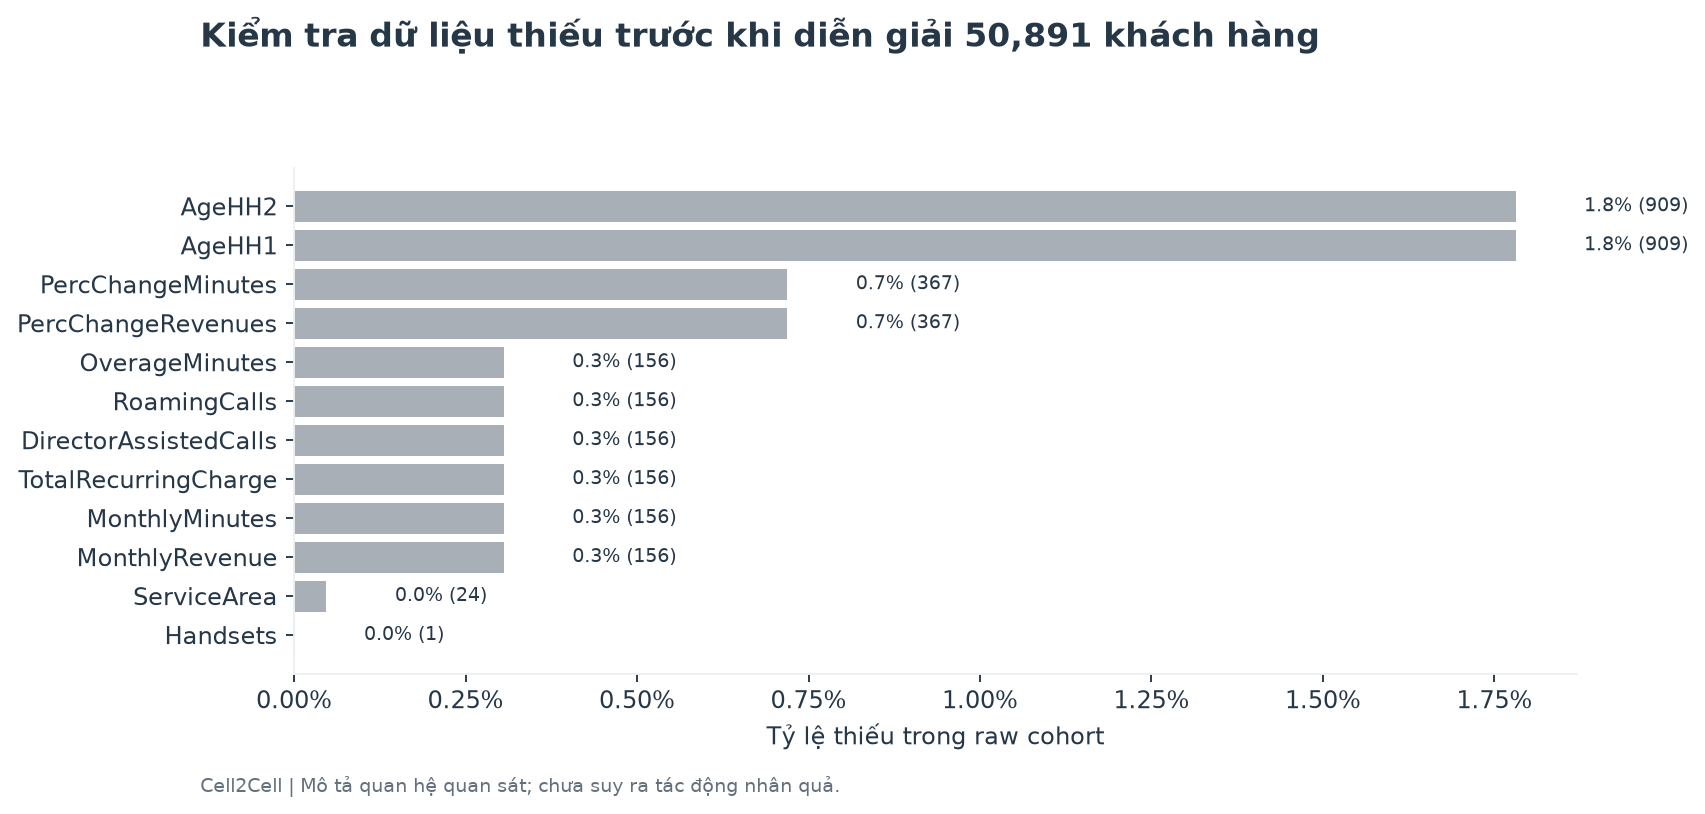

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E02')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Raw có 51,047 dòng, cohort phân tích 50,891 dòng, chênh 156 dòng do quy tắc nguồn. Raw có 3,515 ô thiếu; cohort còn 2,259 ô thiếu.

**Business Meaning**

Không đồng nhất thiếu dữ liệu với hành vi bằng 0. Trong EDA, thiếu được giữ thành nhóm; imputation của mô hình chỉ fit trên train.

**Next Question**

Quy tắc loại dòng thiếu MonthlyRevenue ảnh hưởng đại diện cohort ra sao?

**Kết luận chất lượng dữ liệu.** Quy mô phân tích và số dòng bị loại được ghi trong manifest. Các lỗi phạm vi giá trị được phân biệt với hành vi cực đoan, và missing được giữ để xử lý trong từng phân vùng huấn luyện. Không dùng thống kê toàn bộ cohort để fit imputer hoặc chọn ngưỡng mô hình.

## 4 Customer Overview và Churn Situation

Phần này xác định quy mô churn, doanh thu, vòng đời và sử dụng trước khi đi vào từng nhóm. Các phân phối chỉ mô tả sự khác nhau giữa hai nhóm; dữ liệu không thiết lập trình tự thời gian hay quan hệ nguyên nhân.

### E01 28.8% khách hàng trong cohort đã rời bỏ dịch vụ

**Câu hỏi kinh doanh:** Quy mô churn hiện tại trong cohort là bao nhiêu?

**Quyết định:** Đặt baseline cho phân tích và đo lift của mô hình.

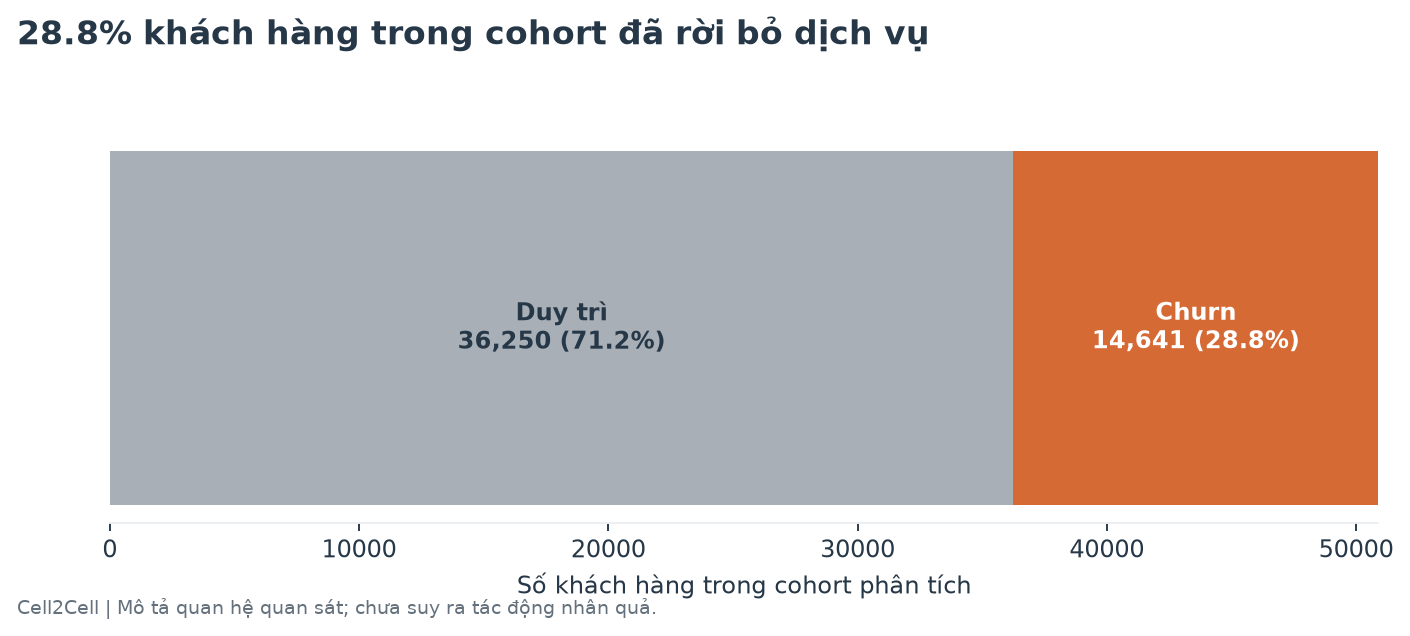

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E01')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Cohort gồm 50,891 khách hàng: 14,641 churn và 36,250 duy trì. Tỷ lệ này là tỷ trọng nhãn trong nguồn, chưa phải churn rate theo tháng vì không có mốc quan sát đầy đủ.

**Business Meaning**

Quy mô churn đáng kể yêu cầu xếp hạng mục tiêu; cần phân biệt khả năng churn với khả năng được giữ chân nhờ can thiệp.

**Next Question**

Churn tập trung ở giai đoạn vòng đời và nhóm hành vi nào?

### E03 Thời gian gắn bó (tháng): trung vị churn 17, duy trì 16

**Câu hỏi kinh doanh:** Phân phối MonthsInService có khác giữa churn và duy trì?

**Quyết định:** Xác định khoảng đo phù hợp trước khi xây quy tắc.

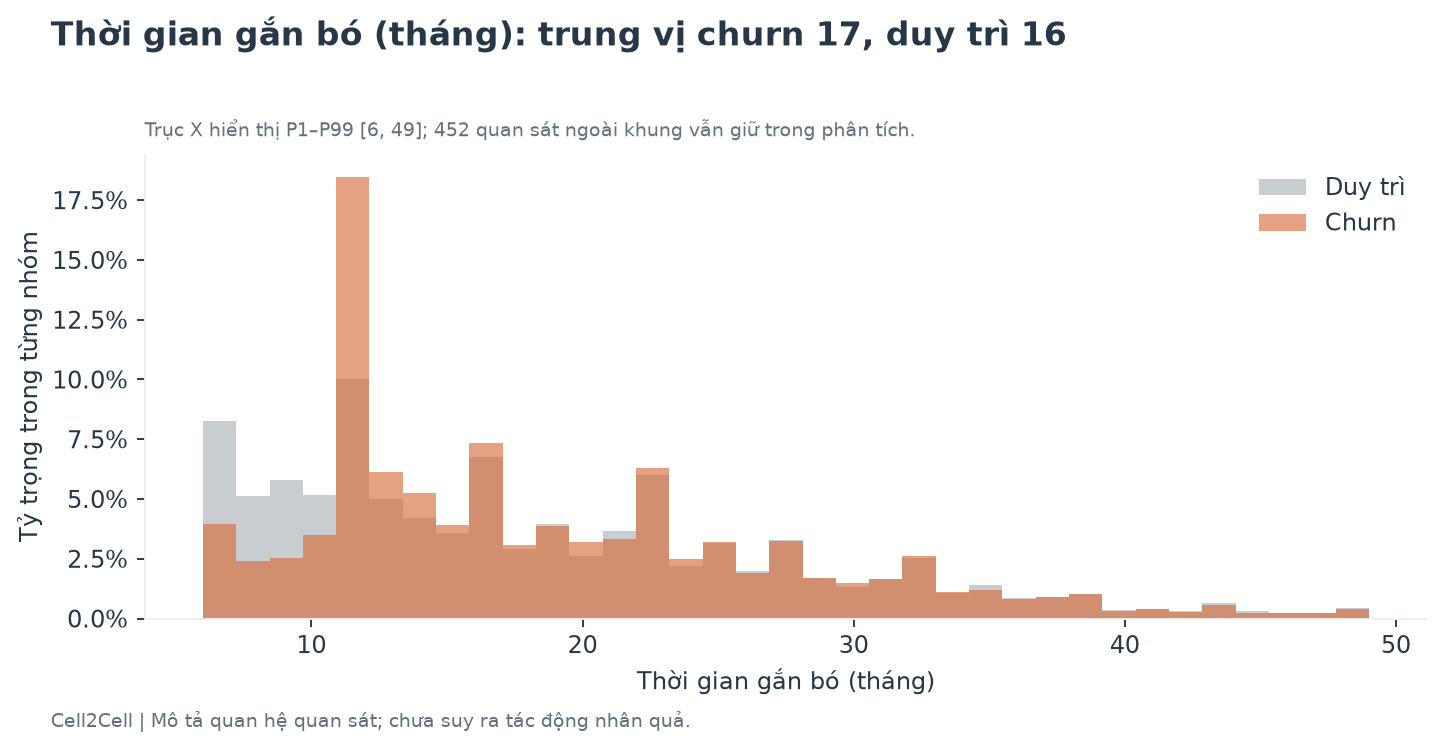

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E03')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Trung vị MonthsInService của nhóm churn là 17, so với 16 ở nhóm duy trì. Phân phối có chồng lấn, vì vậy không xem đây là ngưỡng dự báo độc lập.

**Business Meaning**

So sánh phân phối giúp tránh suy luận chỉ dựa vào số trung bình và nhận diện khách hàng cực trị hợp lệ.

**Next Question**

Churn rate thay đổi ra sao giữa các khoảng phân phối?

### E04 Doanh thu hàng tháng (đơn vị dữ liệu): trung vị churn 47.5, duy trì 48.8

**Câu hỏi kinh doanh:** Phân phối MonthlyRevenue có khác giữa churn và duy trì?

**Quyết định:** Xác định khoảng đo phù hợp trước khi xây quy tắc.

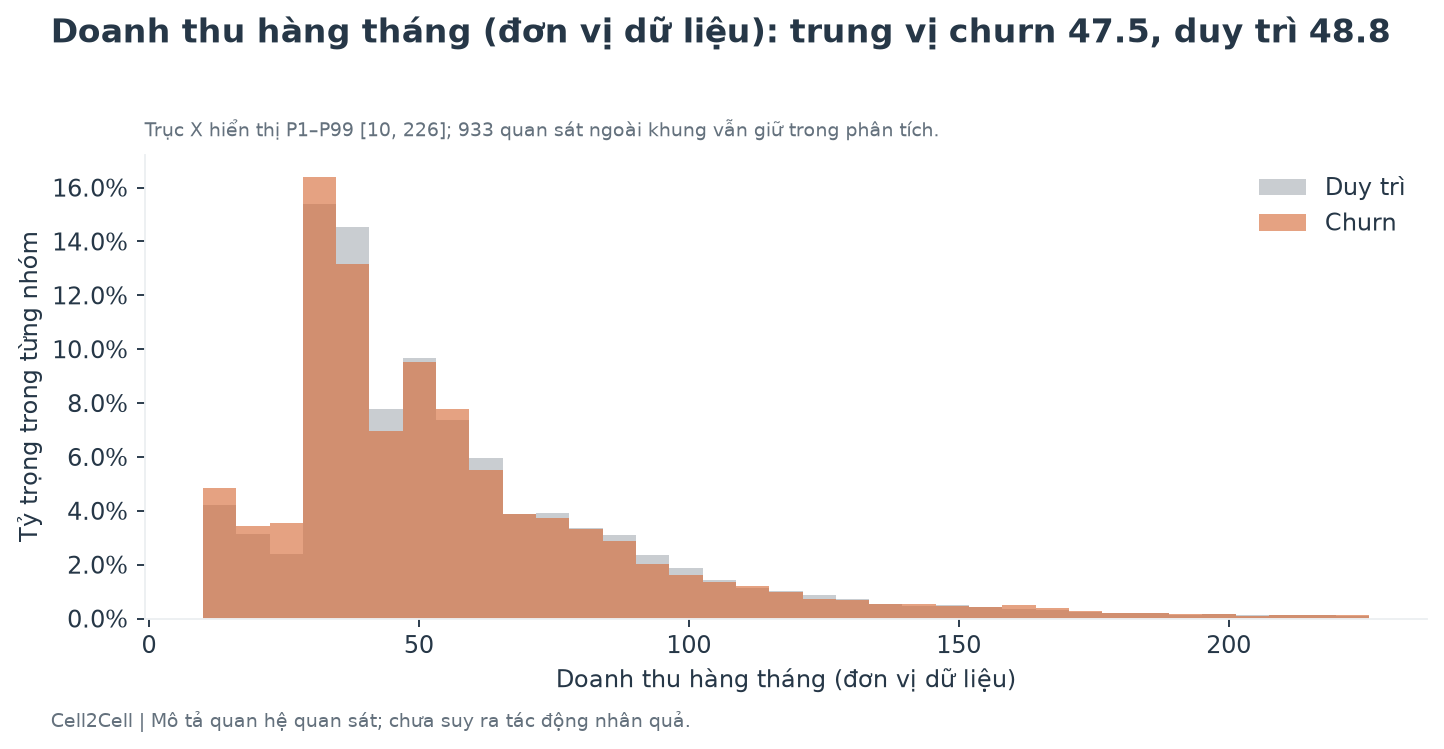

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E04')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Trung vị MonthlyRevenue của nhóm churn là 47.5, so với 48.8 ở nhóm duy trì. Phân phối có chồng lấn, vì vậy không xem đây là ngưỡng dự báo độc lập.

**Business Meaning**

So sánh phân phối giúp tránh suy luận chỉ dựa vào số trung bình và nhận diện khách hàng cực trị hợp lệ.

**Next Question**

Churn rate thay đổi ra sao giữa các khoảng phân phối?

### E05 Phút sử dụng hàng tháng: trung vị churn 330, duy trì 381

**Câu hỏi kinh doanh:** Phân phối MonthlyMinutes có khác giữa churn và duy trì?

**Quyết định:** Xác định khoảng đo phù hợp trước khi xây quy tắc.

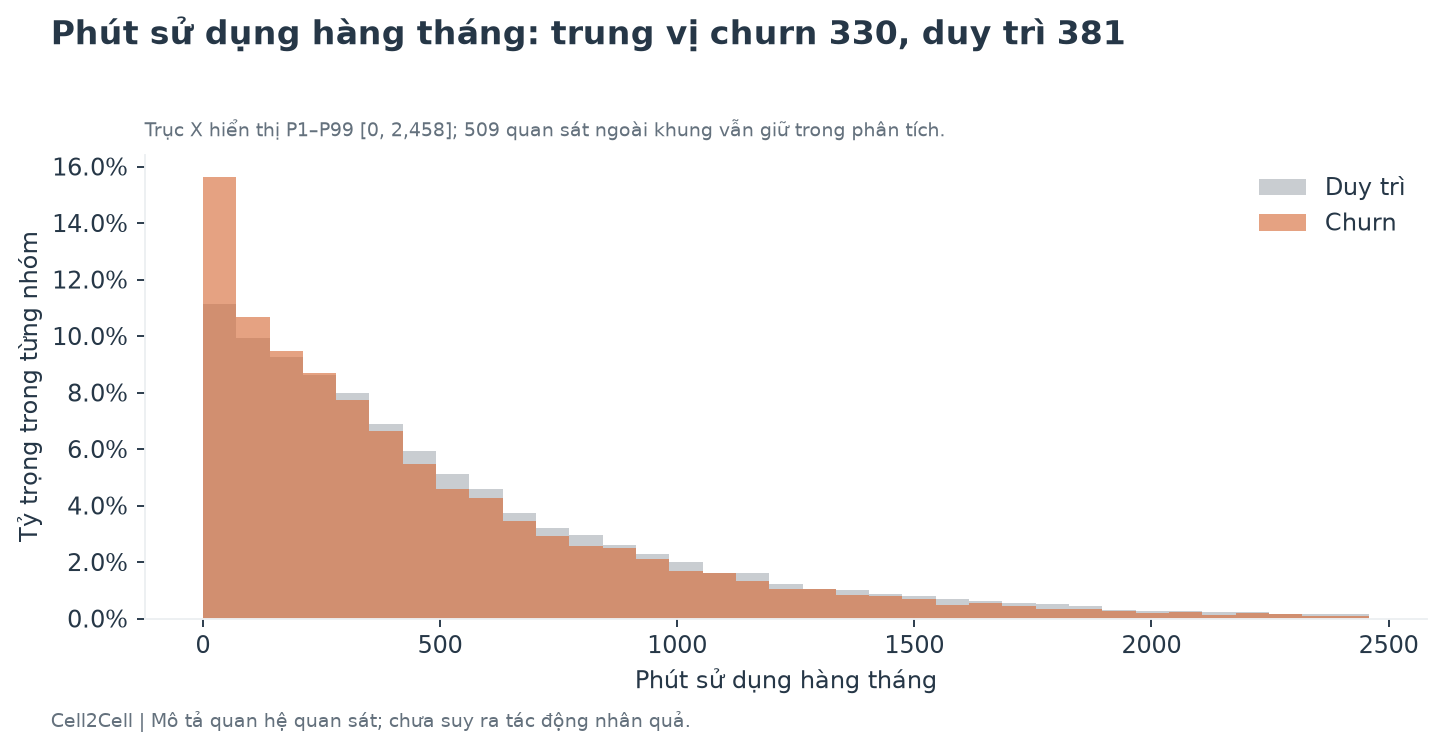

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E05')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Trung vị MonthlyMinutes của nhóm churn là 330, so với 381 ở nhóm duy trì. Phân phối có chồng lấn, vì vậy không xem đây là ngưỡng dự báo độc lập.

**Business Meaning**

So sánh phân phối giúp tránh suy luận chỉ dựa vào số trung bình và nhận diện khách hàng cực trị hợp lệ.

**Next Question**

Churn rate thay đổi ra sao giữa các khoảng phân phối?

## 5 Customer Profile Usage Revenue Call Quality và Lifecycle Analysis

Các nhóm được tạo từ phân phối quan sát và giữ riêng nhóm thiếu. Mỗi bảng phân nhóm chứa quy mô, số churn, tỷ lệ churn và khoảng tin cậy để phân biệt mức độ rủi ro với lượng khách hàng. Trục thời gian gắn bó và các nhóm sử dụng có thứ tự; đây không phải chuỗi thời gian theo lịch.

### E06 Thời gian gắn bó (tháng): nhóm 11–16 ghi nhận churn 34.1%

**Câu hỏi kinh doanh:** Thời gian gắn bó (tháng) liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

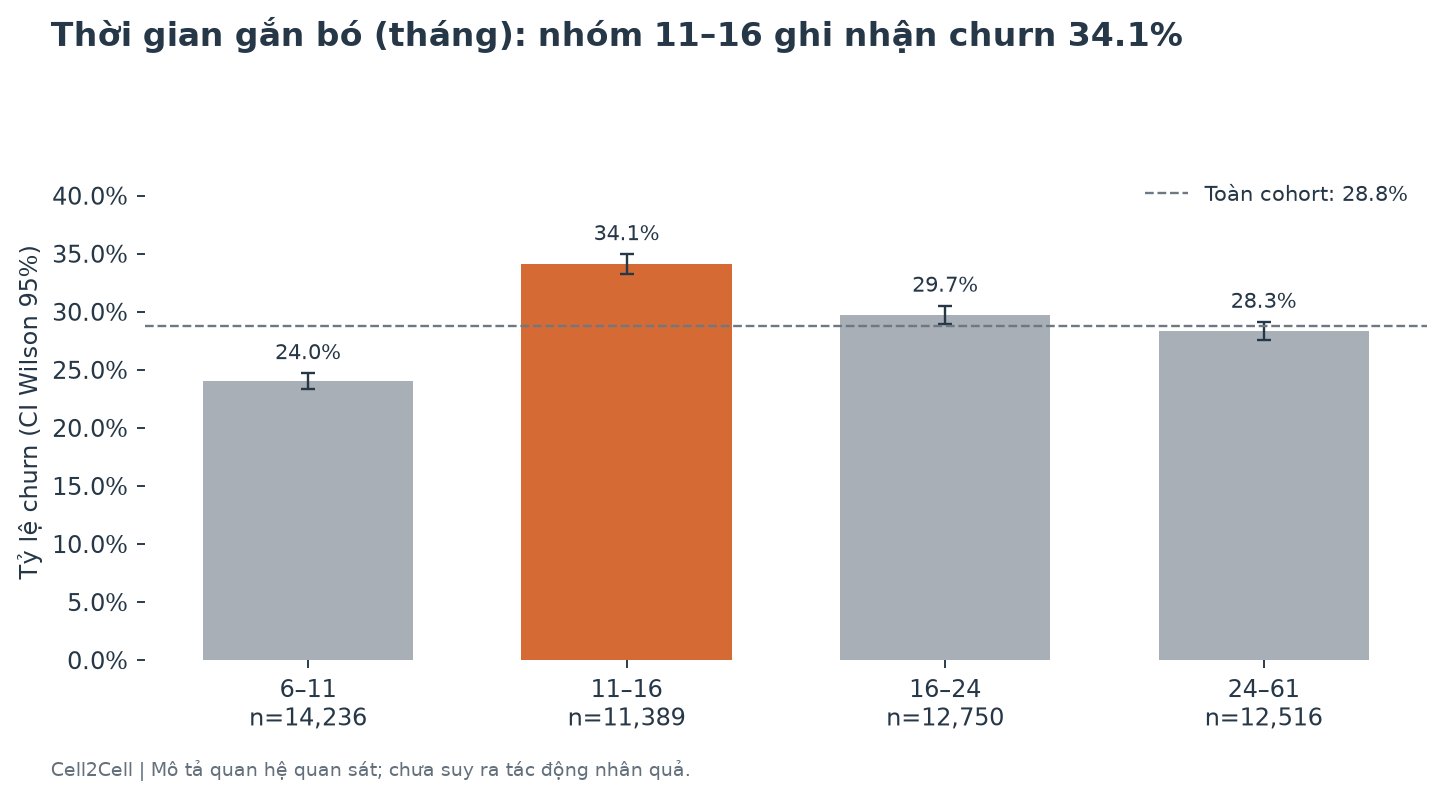

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E06')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm 11–16 có 11,389 khách hàng, 3,883 churn, tỷ lệ 34.1% (CI 95% 33.2%–35.0%). Nhóm 6–11 ghi nhận 24.0%; chênh lệch quan sát 10.1 điểm phần trăm.

**Business Meaning**

Có thể dùng thời gian gắn bó (tháng) để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E07 Doanh thu hàng tháng (đơn vị dữ liệu): nhóm -6.2–33.6 ghi nhận churn 31.4%

**Câu hỏi kinh doanh:** Doanh thu hàng tháng (đơn vị dữ liệu) liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

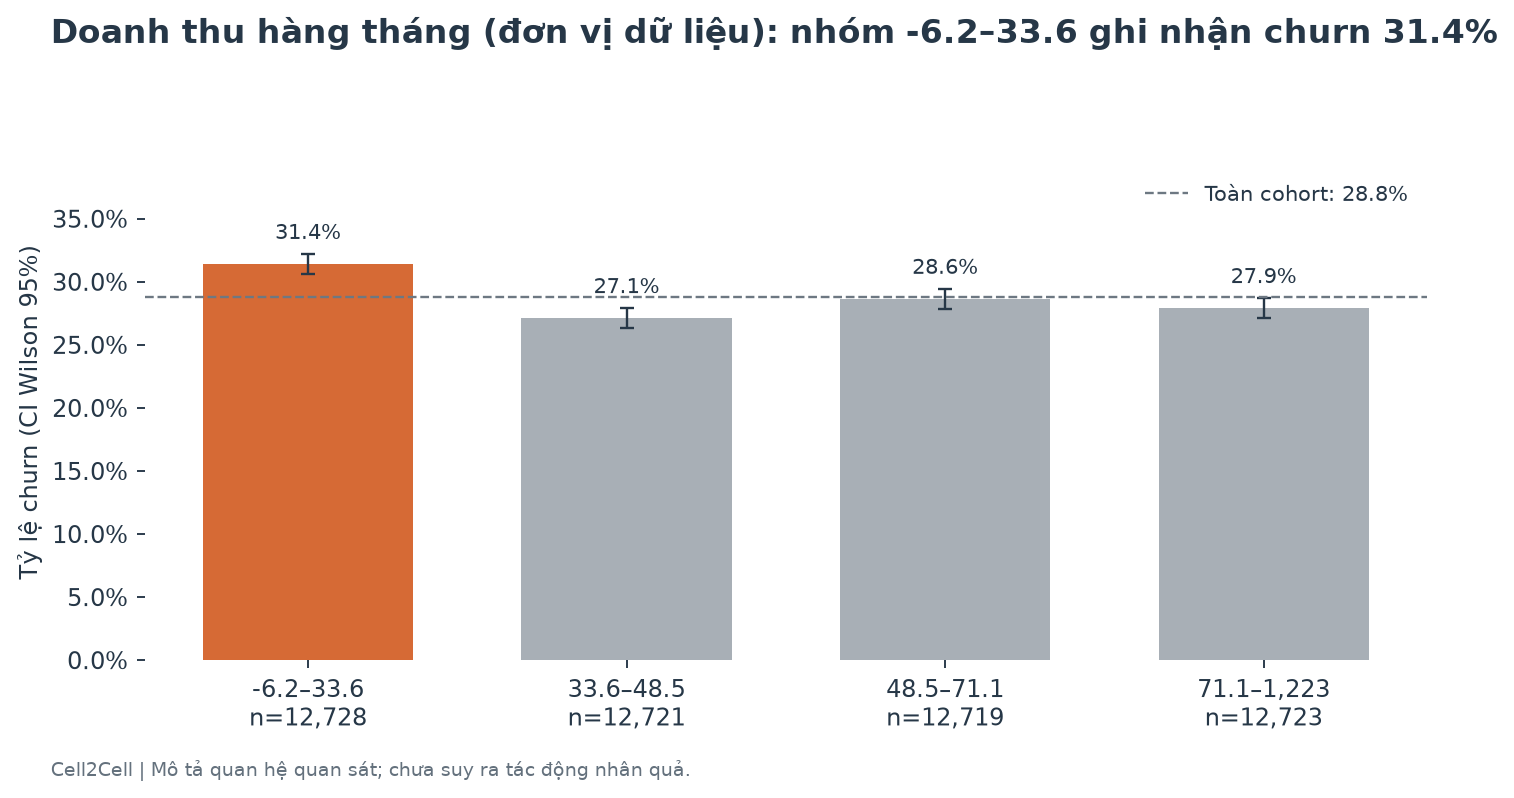

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E07')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm -6.2–33.6 có 12,728 khách hàng, 3,995 churn, tỷ lệ 31.4% (CI 95% 30.6%–32.2%). Nhóm 33.6–48.5 ghi nhận 27.1%; chênh lệch quan sát 4.3 điểm phần trăm.

**Business Meaning**

Có thể dùng doanh thu hàng tháng (đơn vị dữ liệu) để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E08 Phí định kỳ (đơn vị dữ liệu): nhóm -11–30 ghi nhận churn 33.5%

**Câu hỏi kinh doanh:** Phí định kỳ (đơn vị dữ liệu) liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

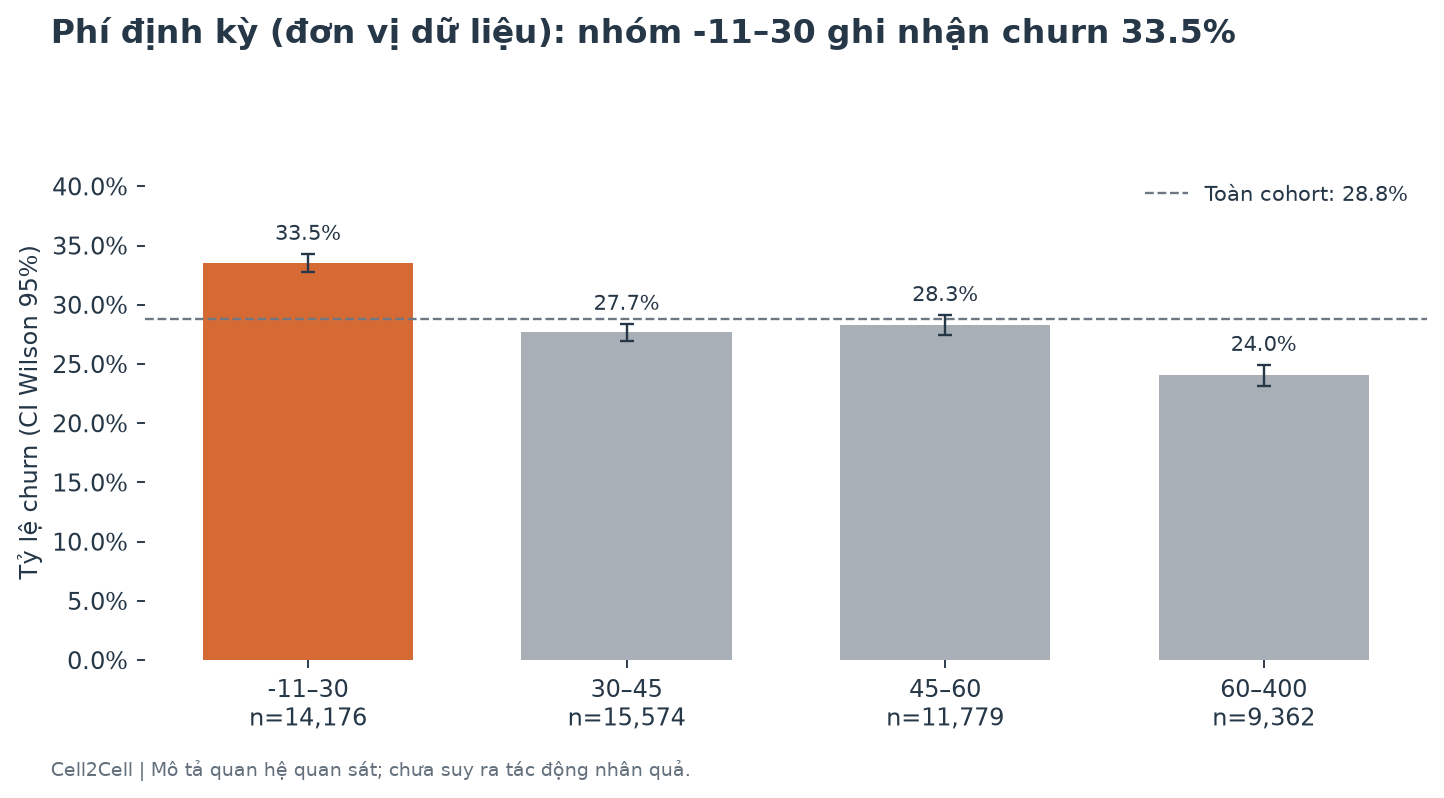

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E08')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm -11–30 có 14,176 khách hàng, 4,749 churn, tỷ lệ 33.5% (CI 95% 32.7%–34.3%). Nhóm 60–400 ghi nhận 24.0%; chênh lệch quan sát 9.5 điểm phần trăm.

**Business Meaning**

Có thể dùng phí định kỳ (đơn vị dữ liệu) để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E09 Phút sử dụng hàng tháng: nhóm 0–158 ghi nhận churn 32.9%

**Câu hỏi kinh doanh:** Phút sử dụng hàng tháng liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

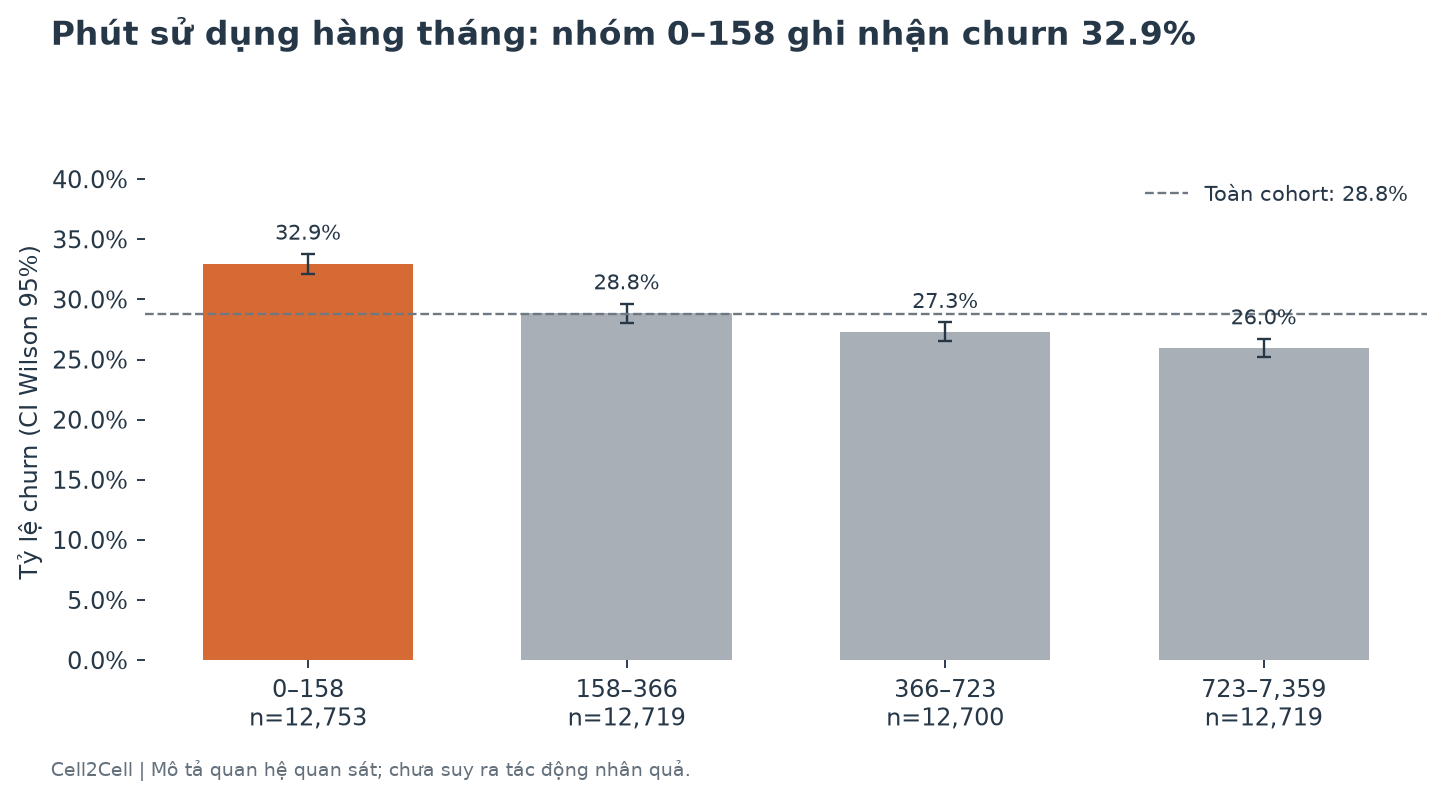

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E09')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm 0–158 có 12,753 khách hàng, 4,202 churn, tỷ lệ 32.9% (CI 95% 32.1%–33.8%). Nhóm 723–7,359 ghi nhận 26.0%; chênh lệch quan sát 7.0 điểm phần trăm.

**Business Meaning**

Có thể dùng phút sử dụng hàng tháng để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E10 Chỉ số thay đổi phút sử dụng: nhóm Thiếu / chưa rõ ghi nhận churn 65.4%

**Câu hỏi kinh doanh:** Chỉ số thay đổi phút sử dụng liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

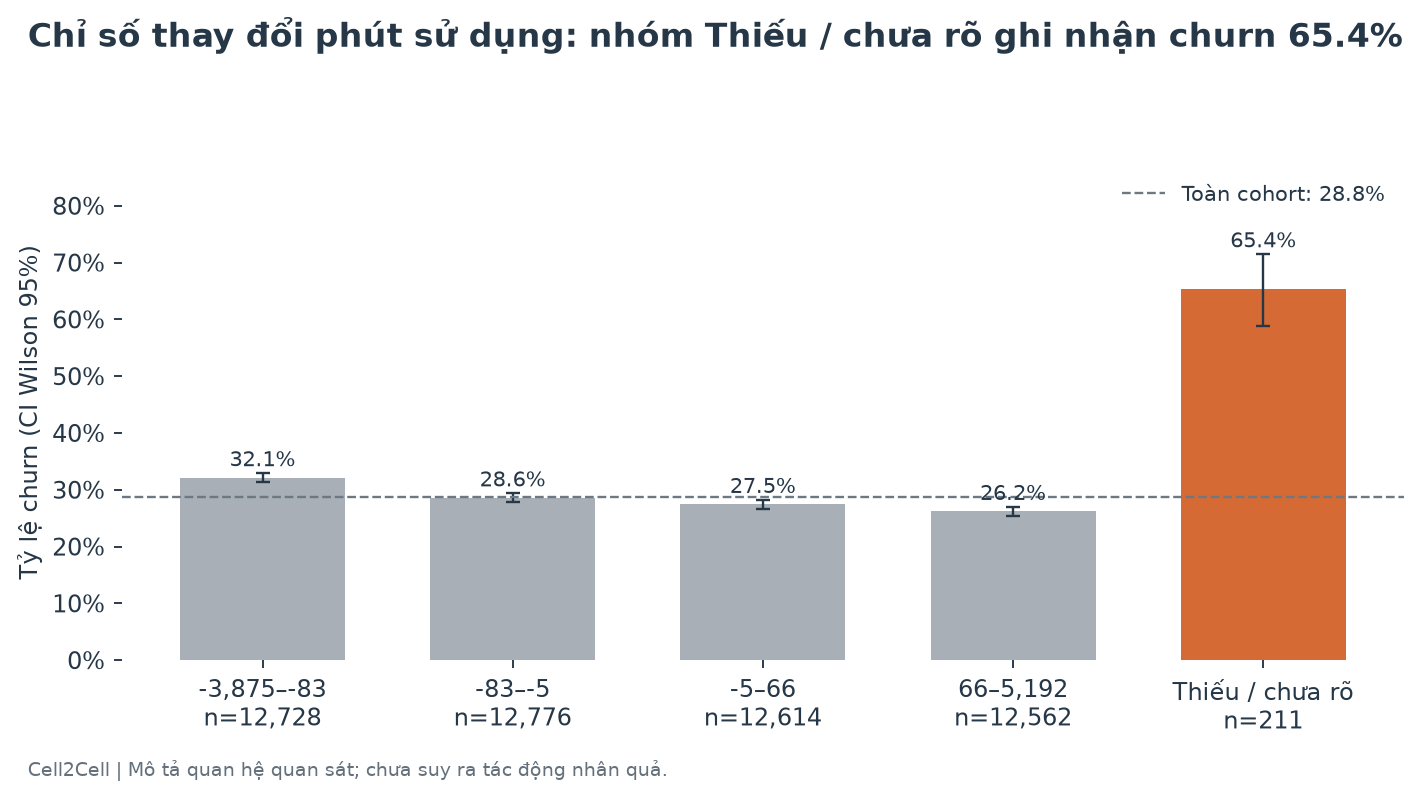

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E10')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm Thiếu / chưa rõ có 211 khách hàng, 138 churn, tỷ lệ 65.4% (CI 95% 58.8%–71.5%). Nhóm 66–5,192 ghi nhận 26.2%; chênh lệch quan sát 39.2 điểm phần trăm.

**Business Meaning**

Có thể dùng chỉ số thay đổi phút sử dụng để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E11 Chỉ số thay đổi doanh thu: nhóm Thiếu / chưa rõ ghi nhận churn 65.4%

**Câu hỏi kinh doanh:** Chỉ số thay đổi doanh thu liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

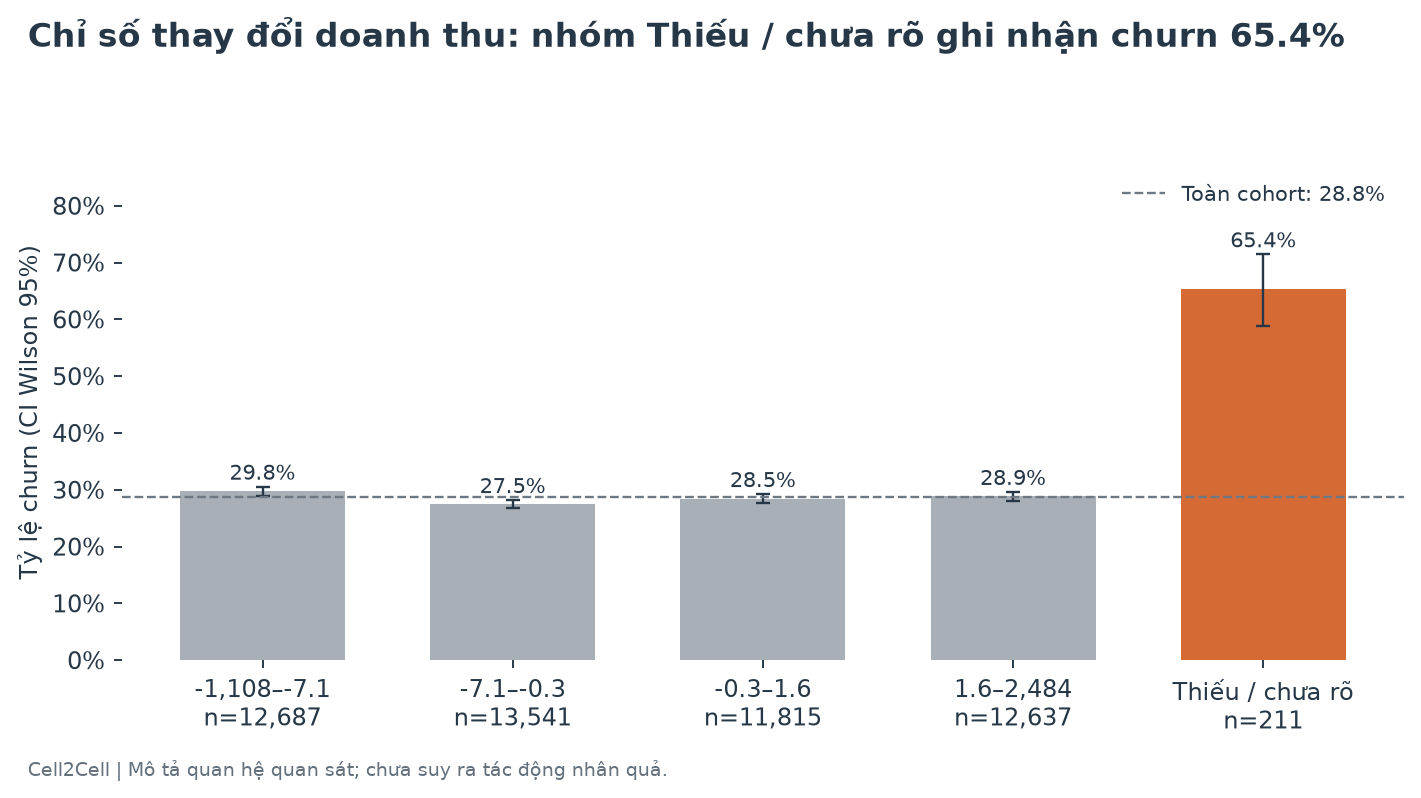

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E11')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm Thiếu / chưa rõ có 211 khách hàng, 138 churn, tỷ lệ 65.4% (CI 95% 58.8%–71.5%). Nhóm -7.1–-0.3 ghi nhận 27.5%; chênh lệch quan sát 37.9 điểm phần trăm.

**Business Meaning**

Có thể dùng chỉ số thay đổi doanh thu để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E12 Phút vượt hạn mức: nhóm >65–4,321 ghi nhận churn 31.0%

**Câu hỏi kinh doanh:** Phút vượt hạn mức liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

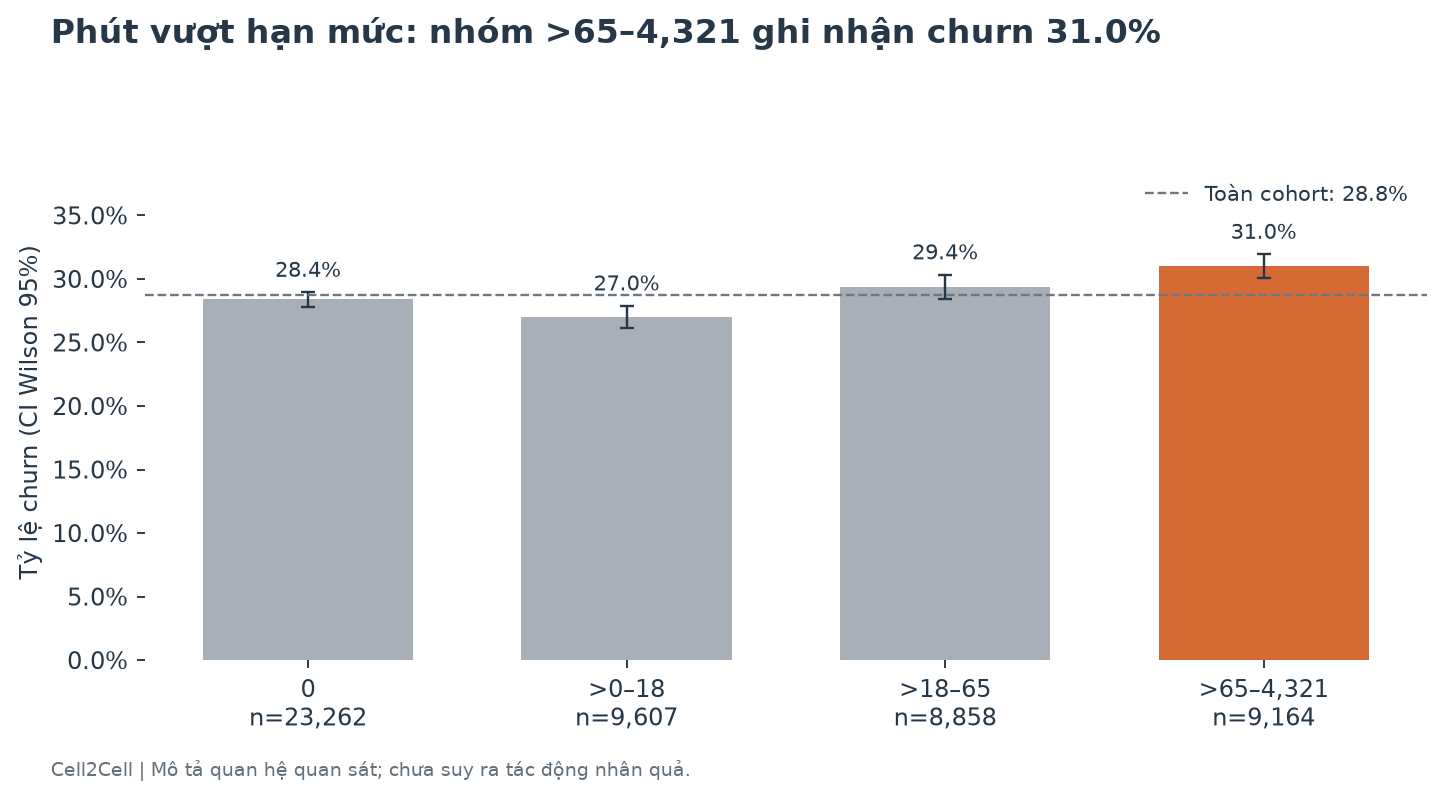

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E12')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm >65–4,321 có 9,164 khách hàng, 2,841 churn, tỷ lệ 31.0% (CI 95% 30.1%–32.0%). Nhóm >0–18 ghi nhận 27.0%; chênh lệch quan sát 4.0 điểm phần trăm.

**Business Meaning**

Có thể dùng phút vượt hạn mức để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E13 Chỉ số roaming: nhóm >2–1,112 ghi nhận churn 30.7%

**Câu hỏi kinh doanh:** Chỉ số roaming liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

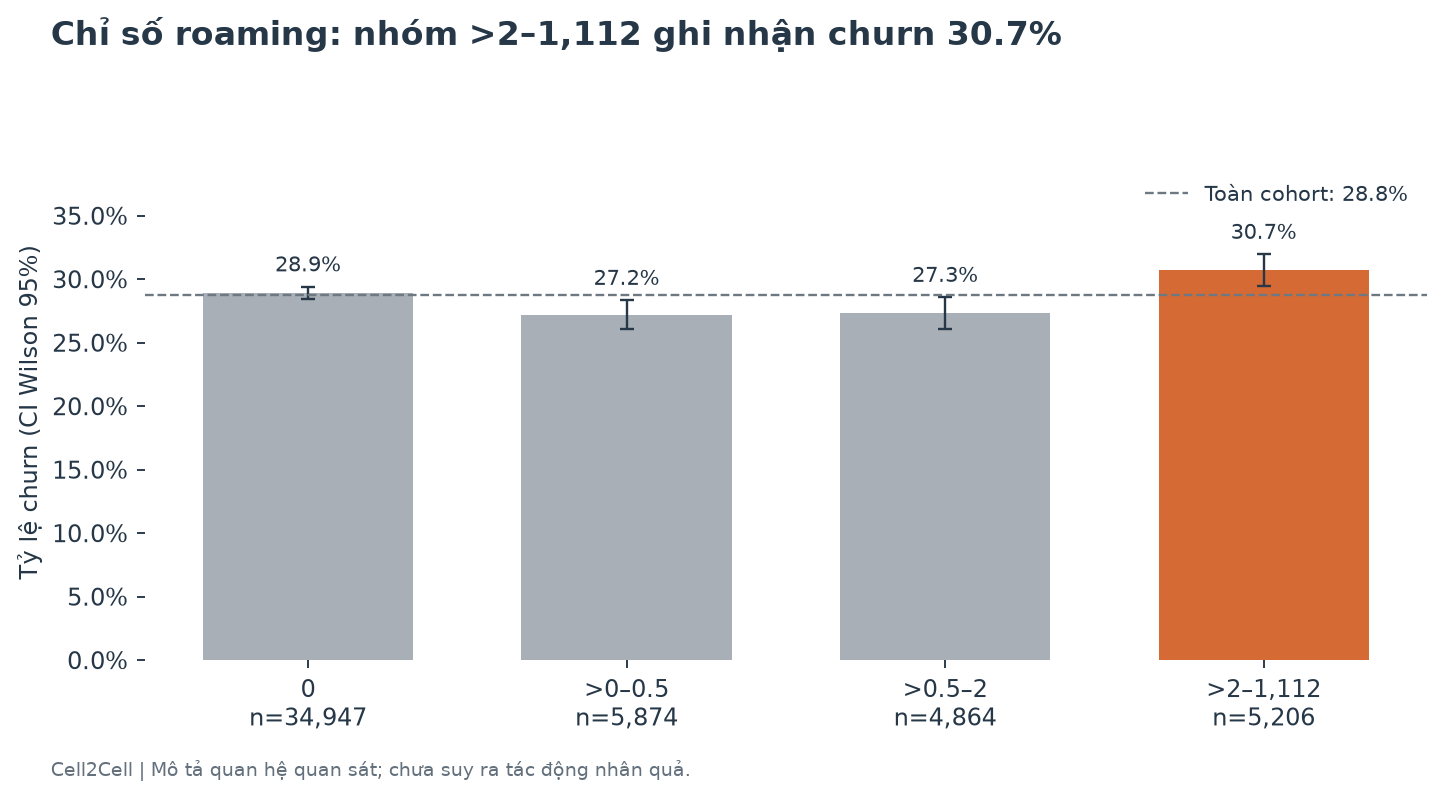

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E13')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm >2–1,112 có 5,206 khách hàng, 1,599 churn, tỷ lệ 30.7% (CI 95% 29.5%–32.0%). Nhóm >0–0.5 ghi nhận 27.2%; chênh lệch quan sát 3.5 điểm phần trăm.

**Business Meaning**

Có thể dùng chỉ số roaming để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E14 Cuộc gọi bị rớt: nhóm 0–0.7 ghi nhận churn 30.8%

**Câu hỏi kinh doanh:** Cuộc gọi bị rớt liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

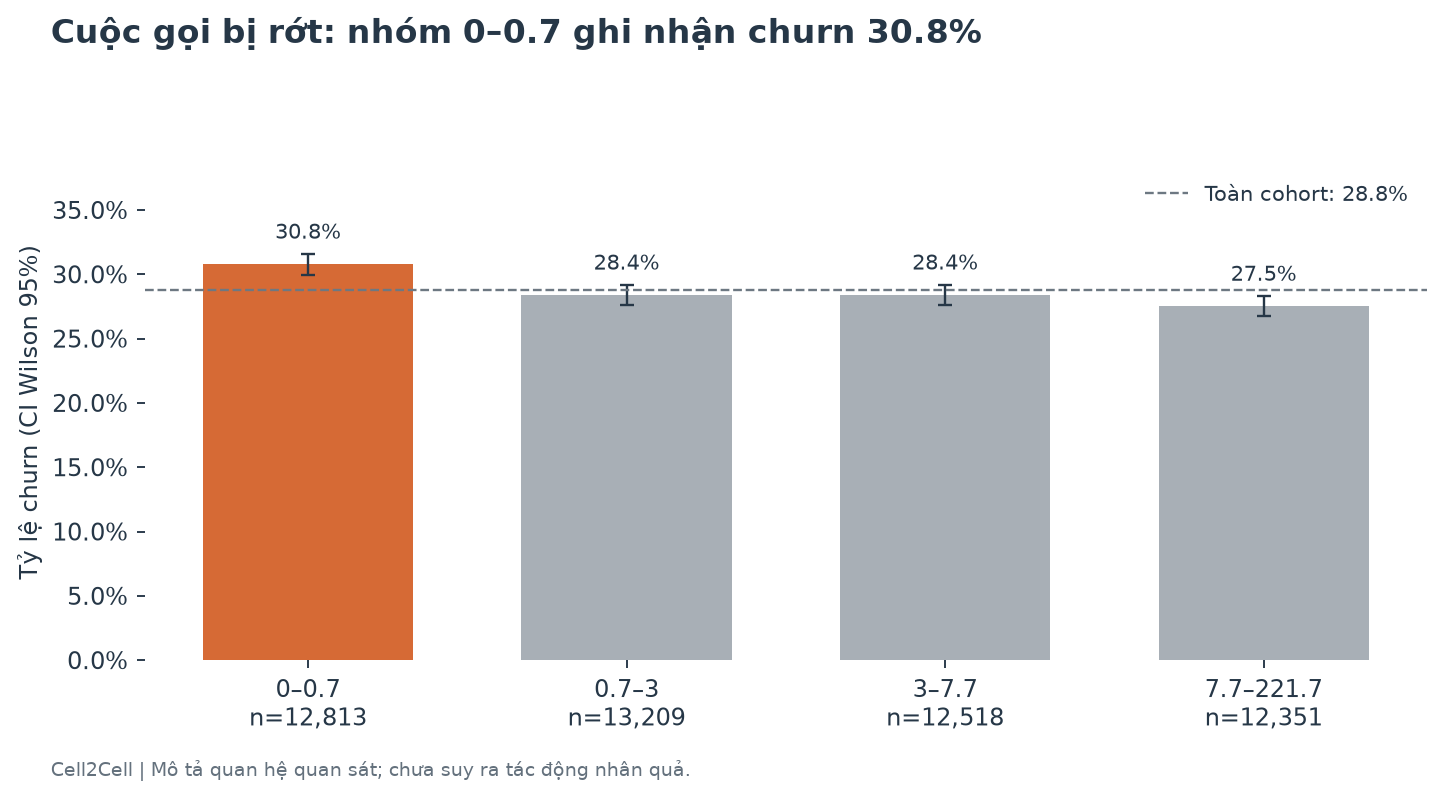

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E14')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm 0–0.7 có 12,813 khách hàng, 3,942 churn, tỷ lệ 30.8% (CI 95% 30.0%–31.6%). Nhóm 7.7–221.7 ghi nhận 27.5%; chênh lệch quan sát 3.3 điểm phần trăm.

**Business Meaning**

Có thể dùng cuộc gọi bị rớt để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E15 Cuộc gọi bị chặn: nhóm 0 ghi nhận churn 30.1%

**Câu hỏi kinh doanh:** Cuộc gọi bị chặn liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

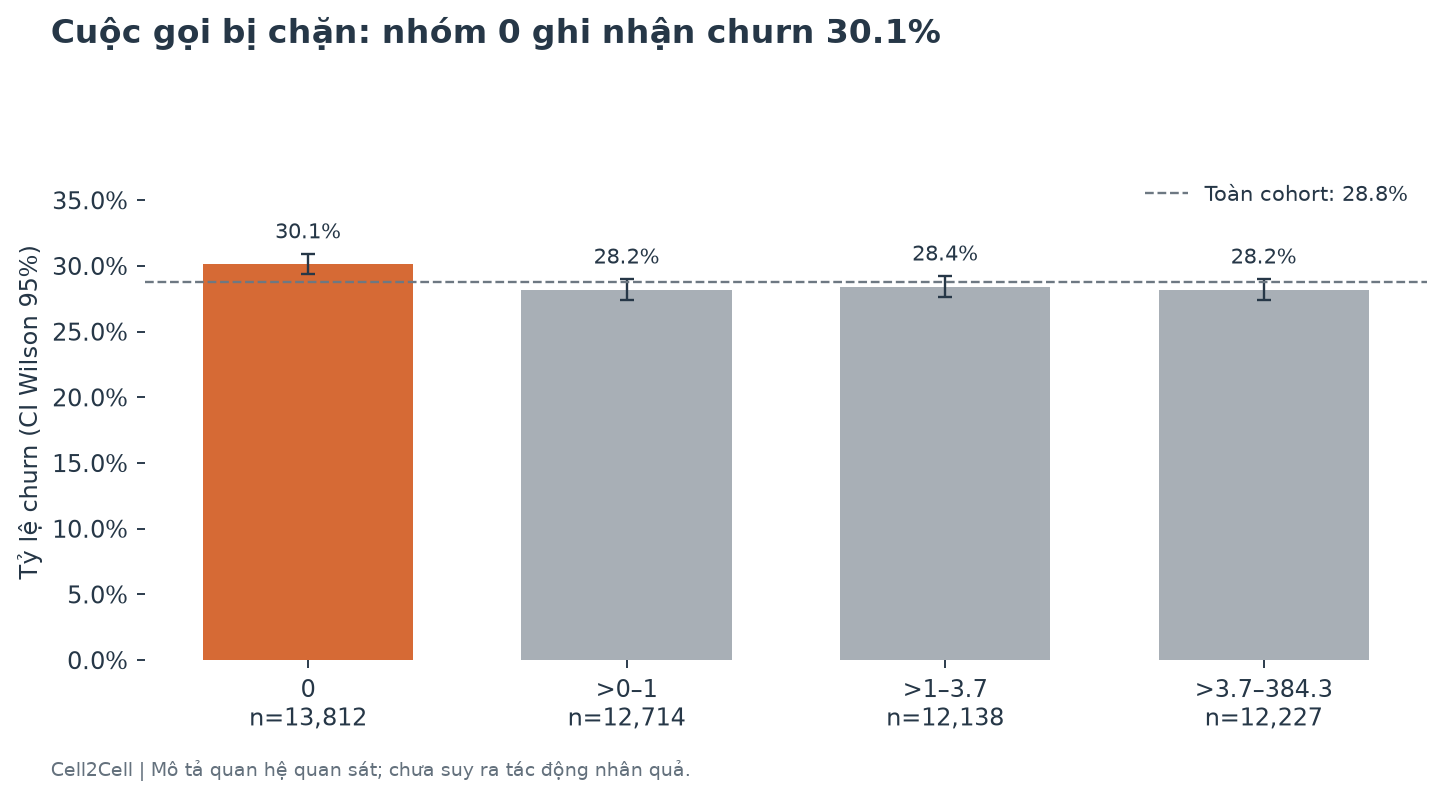

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E15')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm 0 có 13,812 khách hàng, 4,162 churn, tỷ lệ 30.1% (CI 95% 29.4%–30.9%). Nhóm >3.7–384.3 ghi nhận 28.2%; chênh lệch quan sát 1.9 điểm phần trăm.

**Business Meaning**

Có thể dùng cuộc gọi bị chặn để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E16 Cuộc gọi không được trả lời: nhóm 0–5.3 ghi nhận churn 31.6%

**Câu hỏi kinh doanh:** Cuộc gọi không được trả lời liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

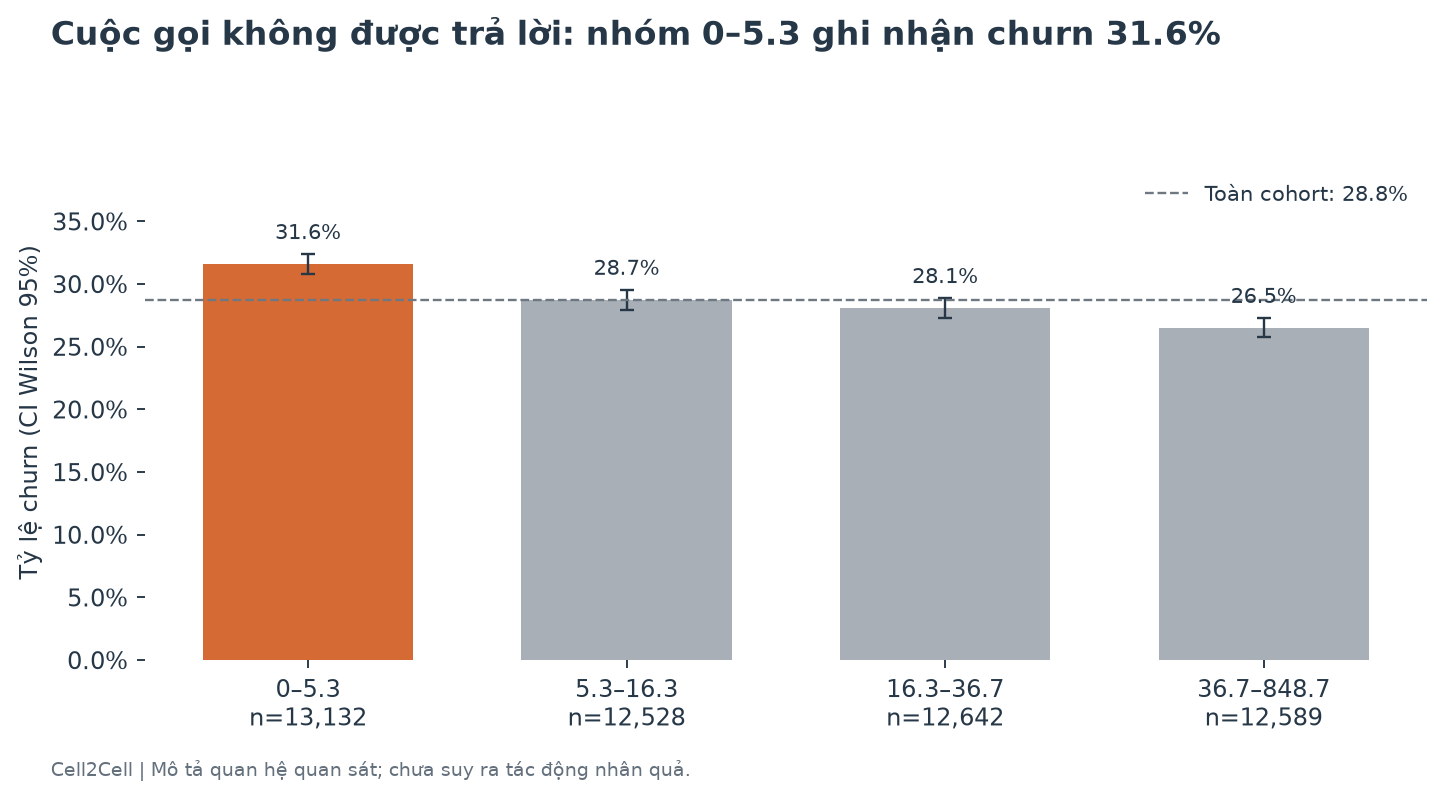

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E16')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm 0–5.3 có 13,132 khách hàng, 4,149 churn, tỷ lệ 31.6% (CI 95% 30.8%–32.4%). Nhóm 36.7–848.7 ghi nhận 26.5%; chênh lệch quan sát 5.1 điểm phần trăm.

**Business Meaning**

Có thể dùng cuộc gọi không được trả lời để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E17 Cuộc gọi tới Customer Care: nhóm 0 ghi nhận churn 30.6%

**Câu hỏi kinh doanh:** Cuộc gọi tới Customer Care liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

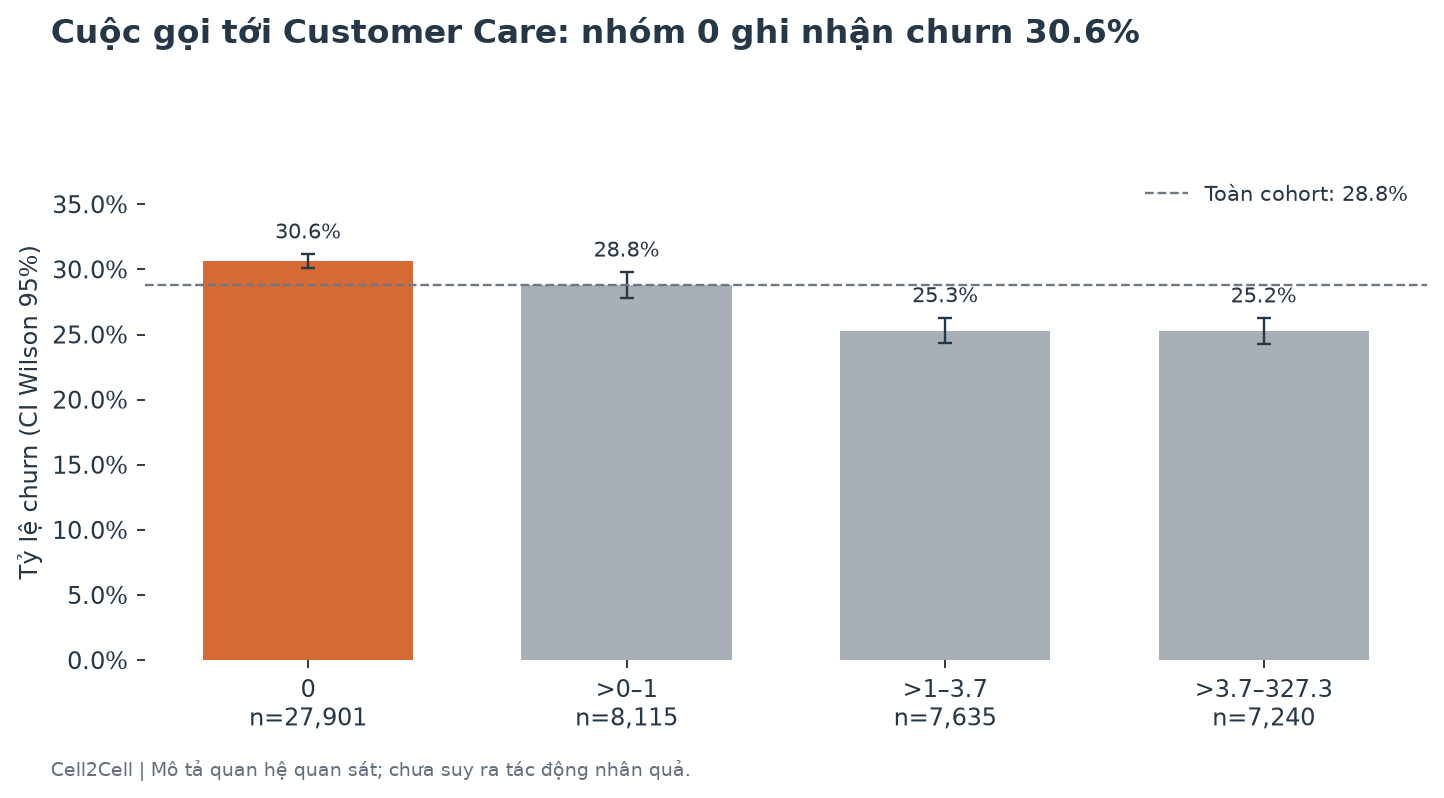

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E17')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm 0 có 27,901 khách hàng, 8,546 churn, tỷ lệ 30.6% (CI 95% 30.1%–31.2%). Nhóm >3.7–327.3 ghi nhận 25.2%; chênh lệch quan sát 5.4 điểm phần trăm.

**Business Meaning**

Có thể dùng cuộc gọi tới customer care để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E18 Tuổi thiết bị hiện tại (ngày): nhóm 329–514 ghi nhận churn 34.9%

**Câu hỏi kinh doanh:** Tuổi thiết bị hiện tại (ngày) liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

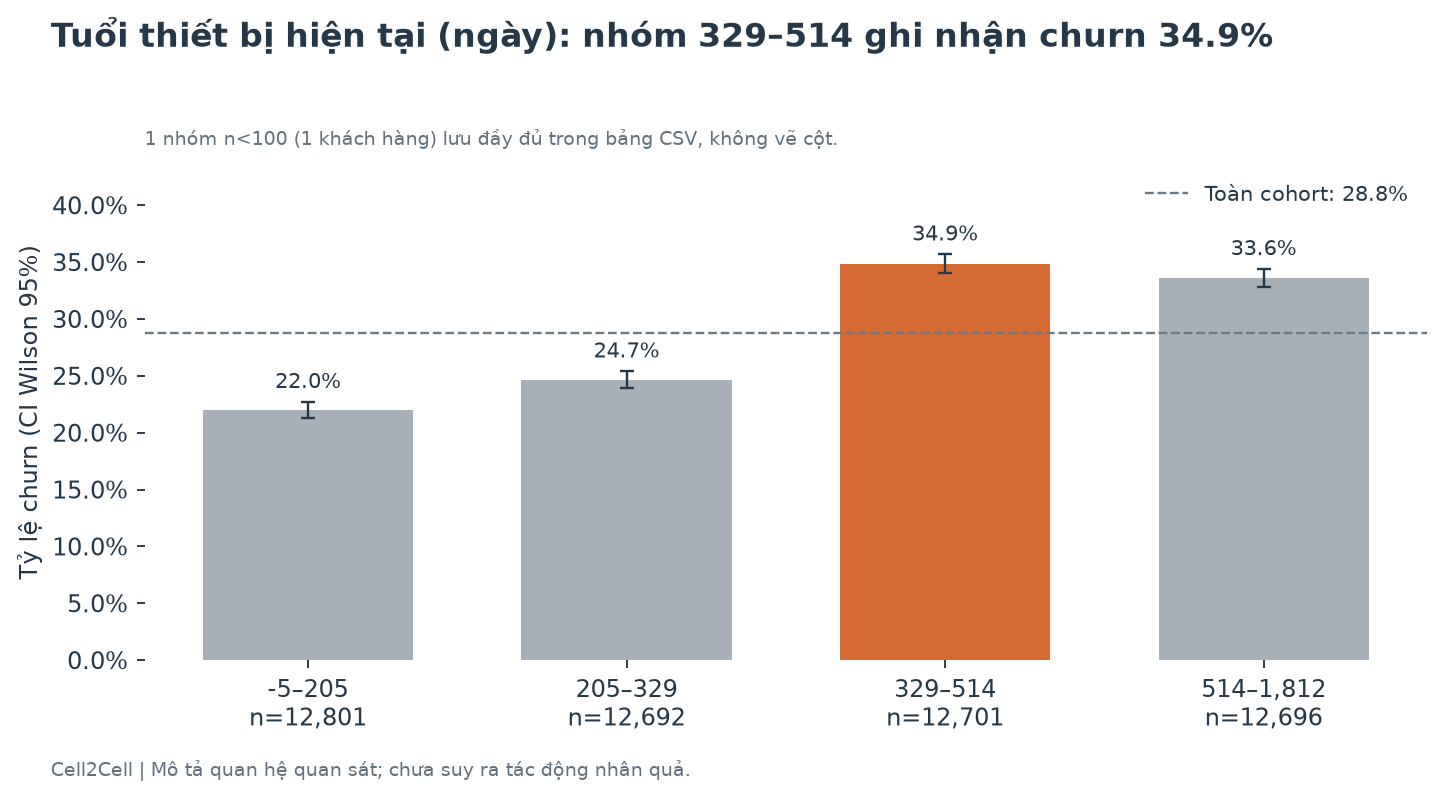

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E18')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm 329–514 có 12,701 khách hàng, 4,429 churn, tỷ lệ 34.9% (CI 95% 34.0%–35.7%). Nhóm -5–205 ghi nhận 22.0%; chênh lệch quan sát 12.9 điểm phần trăm.

**Business Meaning**

Có thể dùng tuổi thiết bị hiện tại (ngày) để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E19 Số thiết bị: nhóm 1–2 ghi nhận churn 29.3%

**Câu hỏi kinh doanh:** Số thiết bị liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

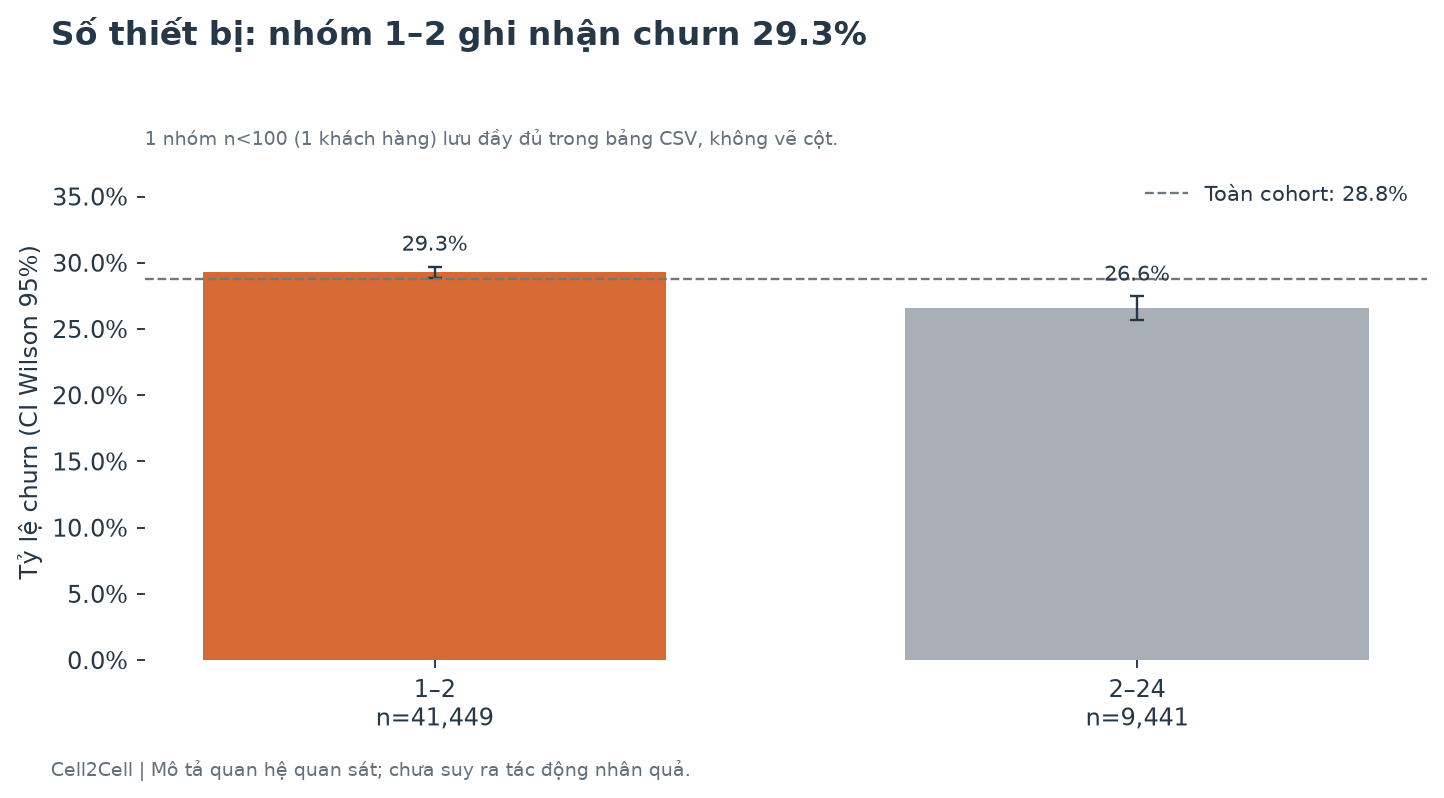

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E19')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm 1–2 có 41,449 khách hàng, 12,134 churn, tỷ lệ 29.3% (CI 95% 28.8%–29.7%). Nhóm 2–24 ghi nhận 26.6%; chênh lệch quan sát 2.7 điểm phần trăm.

**Business Meaning**

Có thể dùng số thiết bị để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E20 Số thuê bao đang hoạt động: nhóm 1–2 ghi nhận churn 31.0%

**Câu hỏi kinh doanh:** Số thuê bao đang hoạt động liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

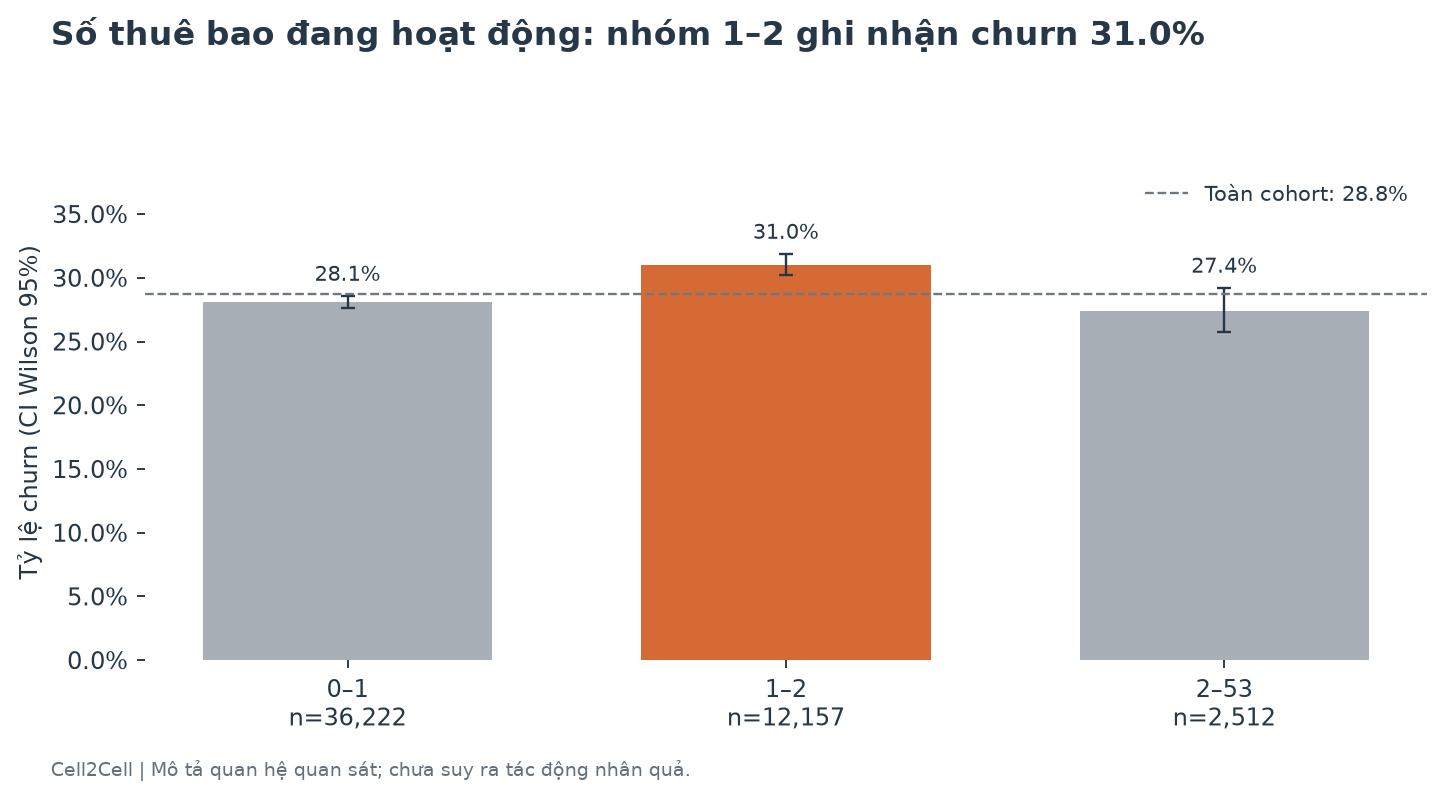

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E20')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm 1–2 có 12,157 khách hàng, 3,773 churn, tỷ lệ 31.0% (CI 95% 30.2%–31.9%). Nhóm 2–53 ghi nhận 27.4%; chênh lệch quan sát 3.6 điểm phần trăm.

**Business Meaning**

Có thể dùng số thuê bao đang hoạt động để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E21 Xếp hạng tín dụng: nhóm 3-Good ghi nhận churn 31.0%

**Câu hỏi kinh doanh:** Xếp hạng tín dụng liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

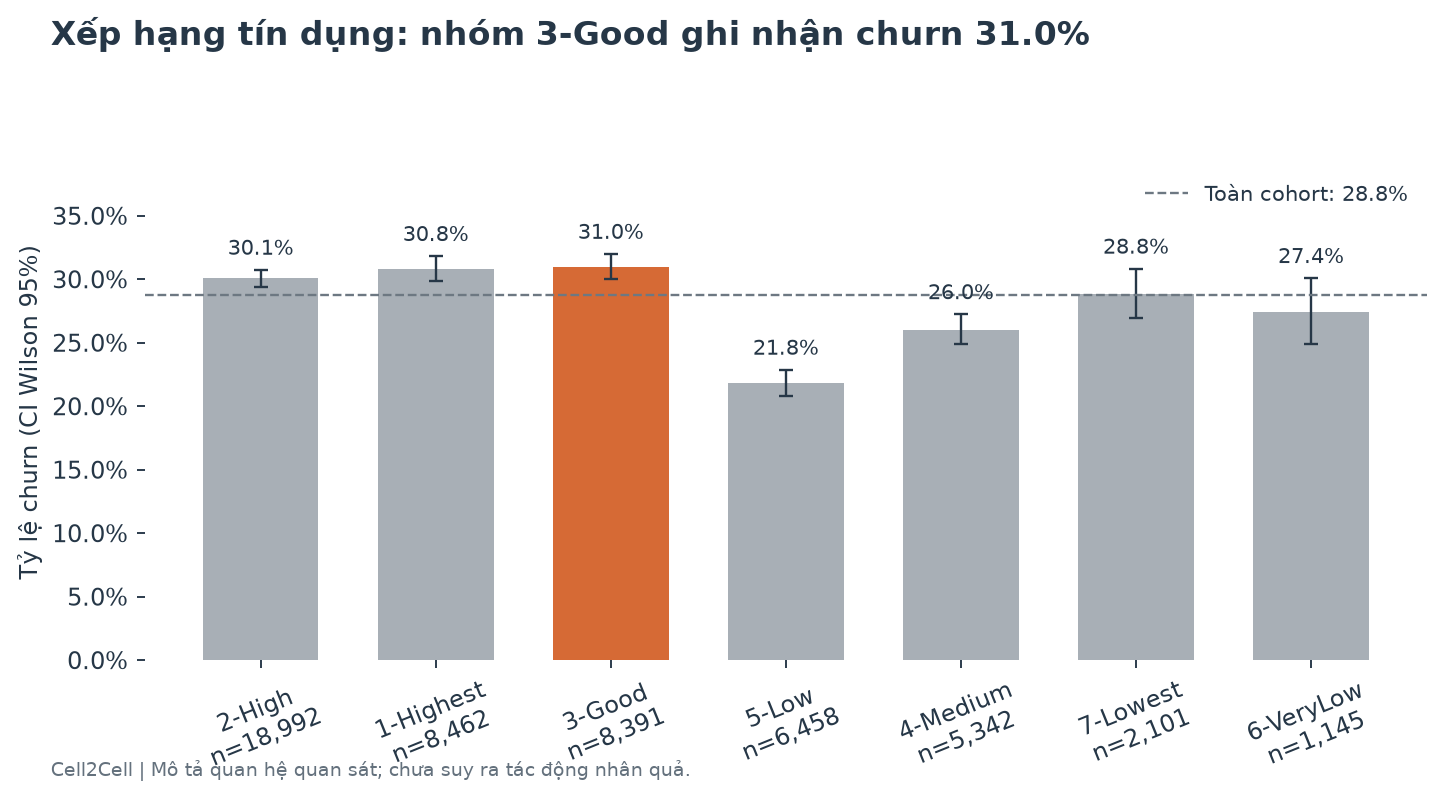

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E21')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm 3-Good có 8,391 khách hàng, 2,600 churn, tỷ lệ 31.0% (CI 95% 30.0%–32.0%). Nhóm 5-Low ghi nhận 21.8%; chênh lệch quan sát 9.2 điểm phần trăm.

**Business Meaning**

Có thể dùng xếp hạng tín dụng để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E22 Tuổi chủ hộ thứ nhất: nhóm 18–34 ghi nhận churn 30.4%

**Câu hỏi kinh doanh:** Tuổi chủ hộ thứ nhất liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

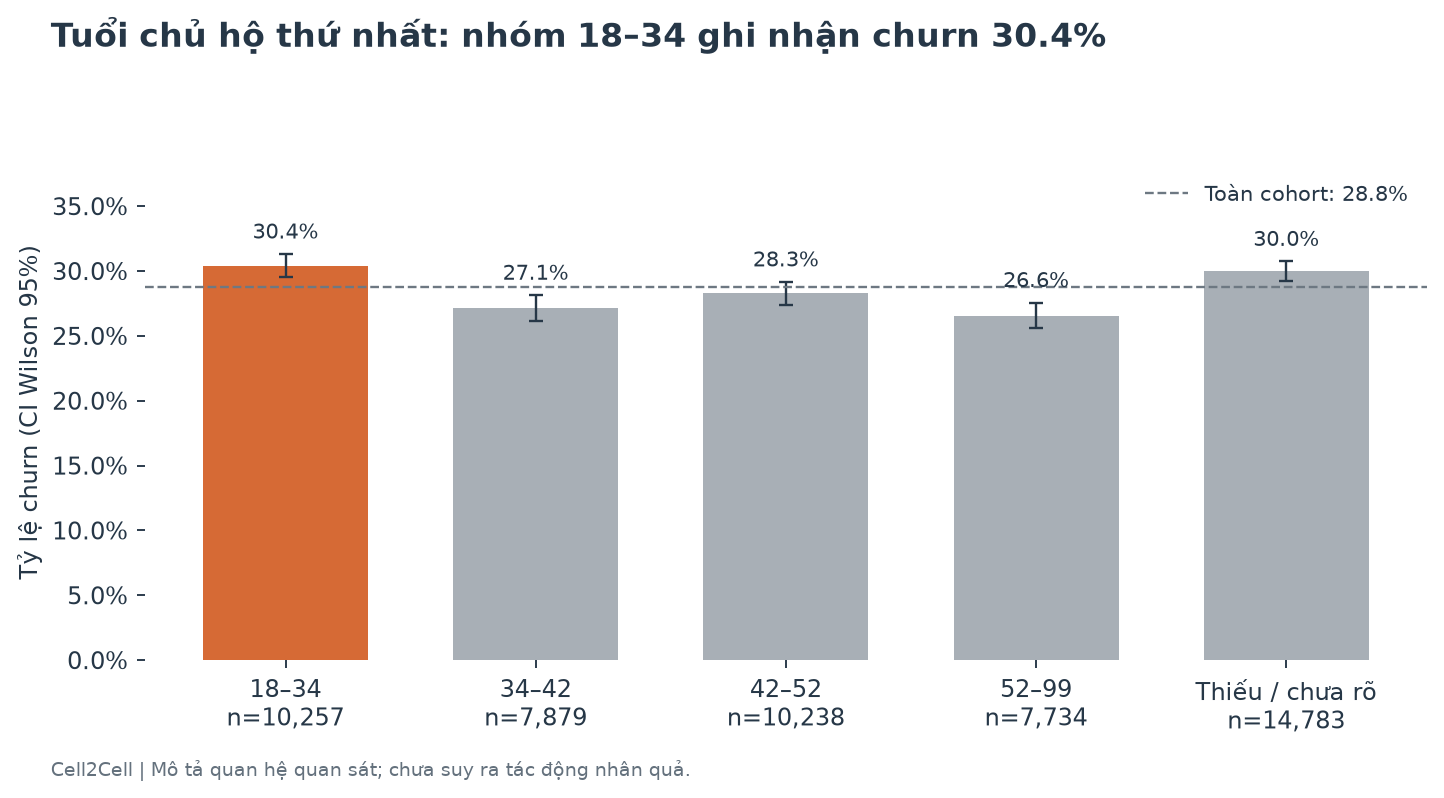

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E22')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm 18–34 có 10,257 khách hàng, 3,119 churn, tỷ lệ 30.4% (CI 95% 29.5%–31.3%). Nhóm 52–99 ghi nhận 26.6%; chênh lệch quan sát 3.8 điểm phần trăm.

**Business Meaning**

Có thể dùng tuổi chủ hộ thứ nhất để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E23 Nhóm thu nhập mã hóa: nhóm 0 ghi nhận churn 30.2%

**Câu hỏi kinh doanh:** Nhóm thu nhập mã hóa liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

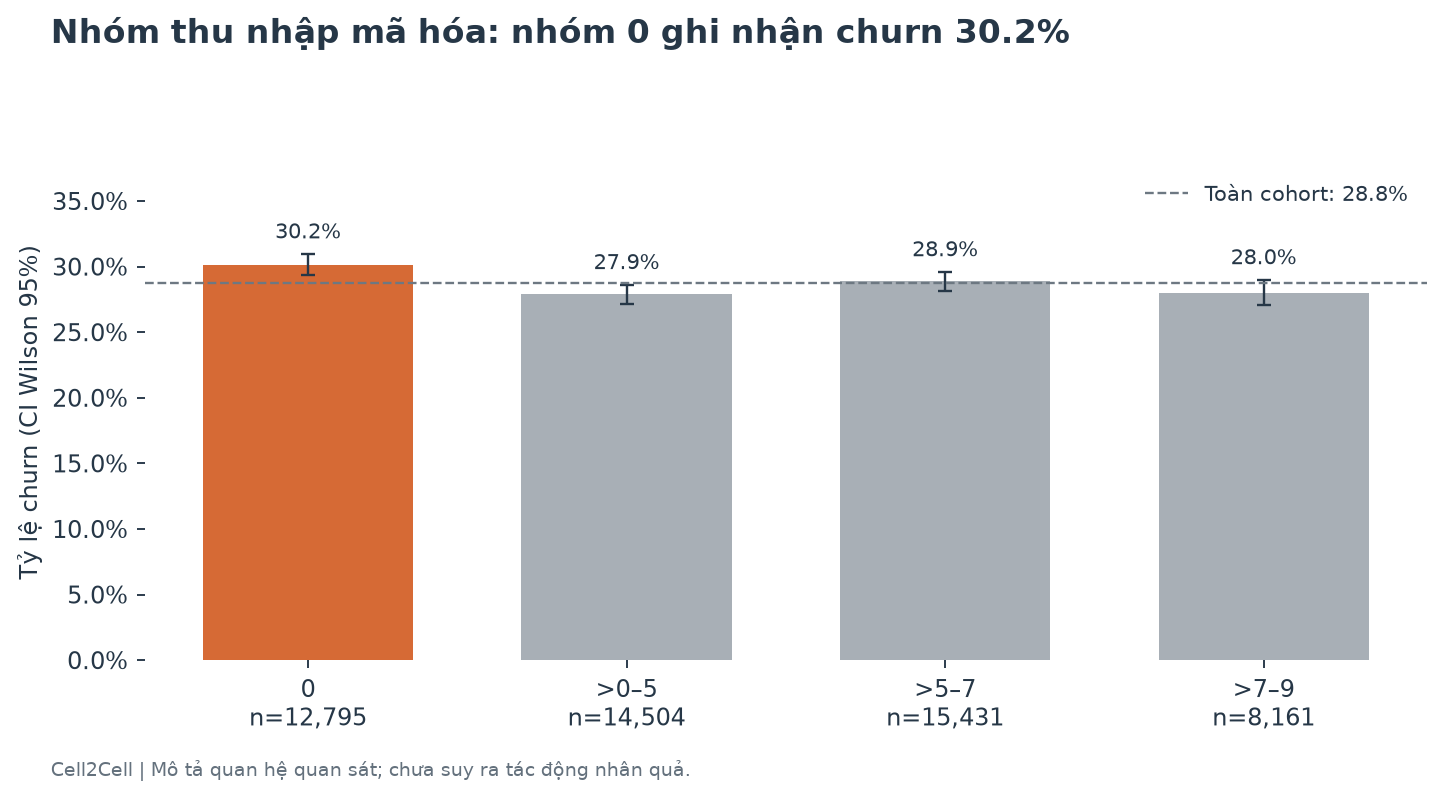

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E23')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm 0 có 12,795 khách hàng, 3,858 churn, tỷ lệ 30.2% (CI 95% 29.4%–31.0%). Nhóm >0–5 ghi nhận 27.9%; chênh lệch quan sát 2.3 điểm phần trăm.

**Business Meaning**

Có thể dùng nhóm thu nhập mã hóa để bổ sung phân nhóm kiểm tra vận hành, kết hợp quy mô nhóm, giá trị và các tín hiệu khác; một biến riêng lẻ chưa đủ để quyết định can thiệp.

**Next Question**

Khác biệt còn tồn tại khi kiểm soát thời gian gắn bó, giá trị và cường độ sử dụng hay không?

### E24 Số cuộc gọi retention: nhóm 1.0 ghi nhận churn 45.0%

**Câu hỏi kinh doanh:** Số cuộc gọi retention liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

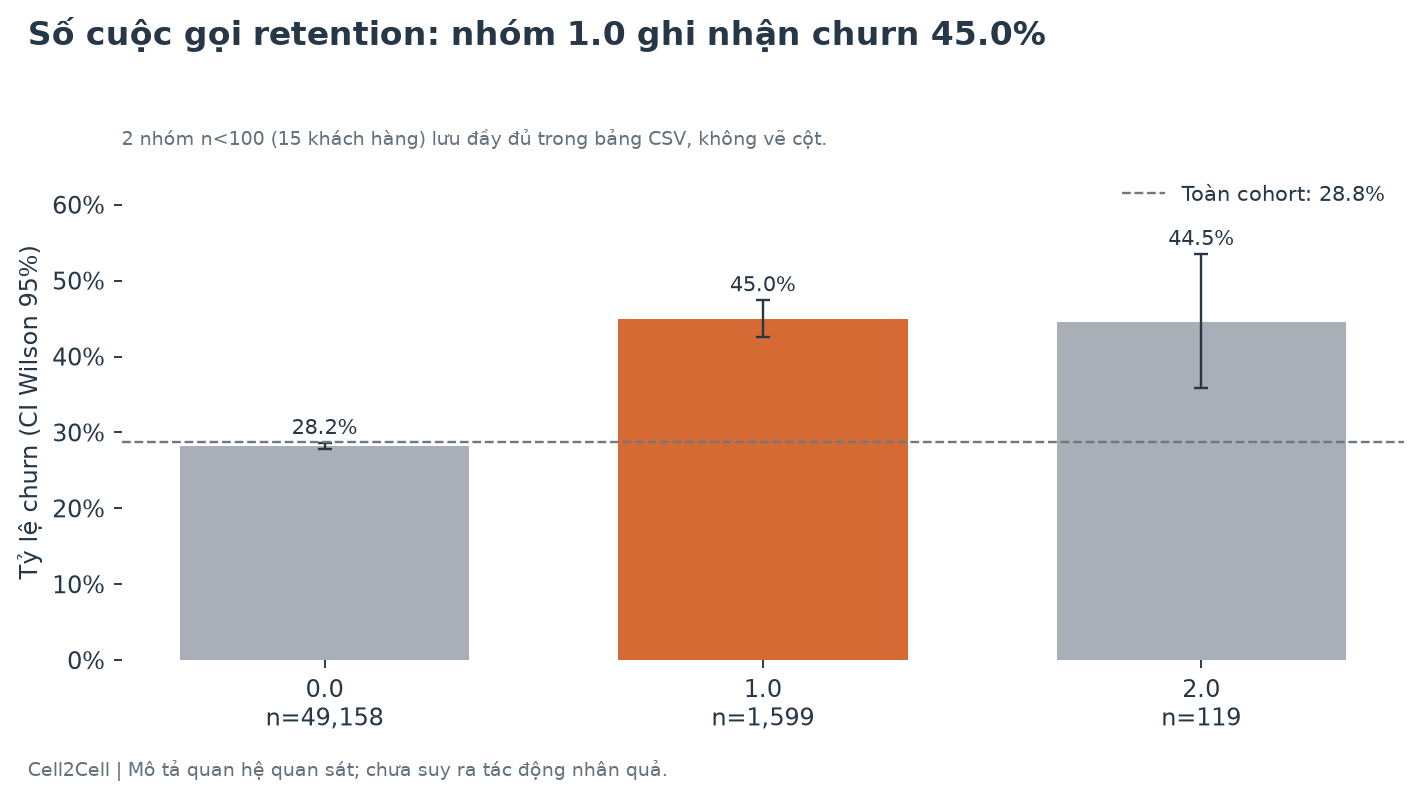

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E24')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm 1.0 có 1,599 khách hàng, 719 churn, tỷ lệ 45.0% (CI 95% 42.5%–47.4%). Nhóm 0.0 ghi nhận 28.2%; chênh lệch quan sát 16.8 điểm phần trăm.

**Business Meaning**

Đây là mô tả luồng xử lý giữ chân. Khách hàng được chuyển tới retention có thể đã có nguy cơ cao; kết quả không đo hiệu quả của offer và trường này bị loại khỏi mô hình cảnh báo sớm.

**Next Question**

Cần lưu thời điểm tiếp xúc, phân nhóm ngẫu nhiên treatment/control và đo incremental retention.

### E25 Số offer retention được chấp nhận: nhóm 1.0 ghi nhận churn 40.9%

**Câu hỏi kinh doanh:** Số offer retention được chấp nhận liên quan thế nào tới churn?

**Quyết định:** Dùng cùng các tín hiệu khác để xác định nhóm cần điều tra.

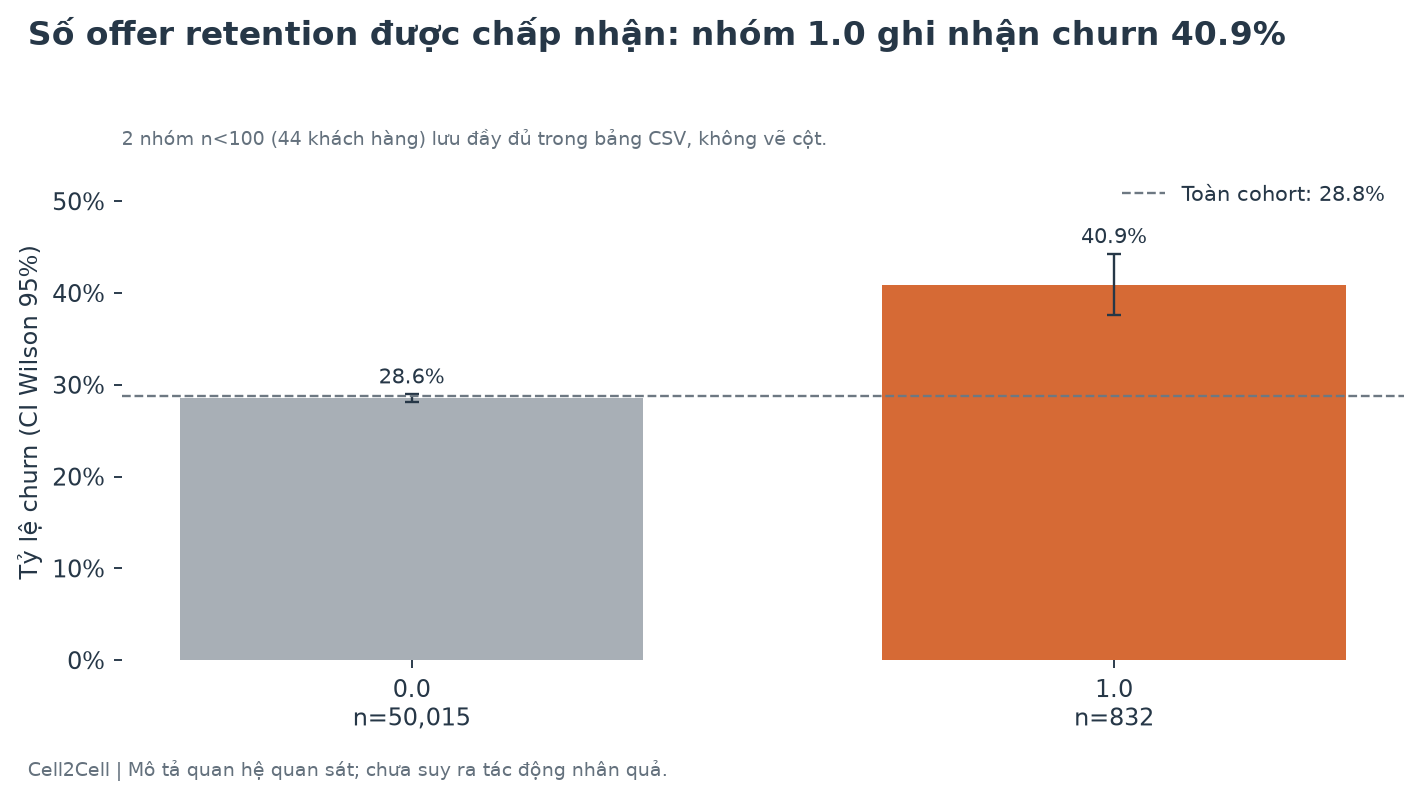

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E25')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm 1.0 có 832 khách hàng, 340 churn, tỷ lệ 40.9% (CI 95% 37.6%–44.2%). Nhóm 0.0 ghi nhận 28.6%; chênh lệch quan sát 12.3 điểm phần trăm.

**Business Meaning**

Đây là mô tả luồng xử lý giữ chân. Khách hàng được chuyển tới retention có thể đã có nguy cơ cao; kết quả không đo hiệu quả của offer và trường này bị loại khỏi mô hình cảnh báo sớm.

**Next Question**

Cần lưu thời điểm tiếp xúc, phân nhóm ngẫu nhiên treatment/control và đo incremental retention.

In [ ]:
display(pd.read_csv(BASE/'output/analysis/segment_profiles.csv'))
display(pd.read_csv(BASE/'output/analysis/descriptive_statistics.csv'))

,variable,group,n,churn_count,churn_rate,ci_low,ci_high,small_group,relative_risk
0,MonthsInService,6–11,14236,3419,0.240166,0.233219,0.247253,False,0.834798
1,MonthsInService,11–16,11389,3883,0.340943,0.332292,0.349701,False,1.185092
2,MonthsInService,16–24,12750,3791,0.297333,0.289461,0.305327,False,1.033508
3,MonthsInService,24–61,12516,3548,0.283477,0.275649,0.291438,False,0.985345
4,MonthlyRevenue,-6.2–33.6,12728,3995,0.313875,0.305870,0.321992,False,1.091005
...,...,...,...,...,...,...,...,...,...
81,RetentionCalls,4.0,2,2,1.000000,0.342380,1.000000,True,3.475924
82,RetentionOffersAccepted,0.0,50015,14282,0.285554,0.281612,0.289529,False,0.992565
83,RetentionOffersAccepted,1.0,832,340,0.408654,0.375745,0.442402,False,1.420450
84,RetentionOffersAccepted,2.0,36,16,0.444444,0.295413,0.604189,True,1.544855


,Unnamed: 0,CustomerID,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,BlockedCalls,UnansweredCalls,CustomerCareCalls,ThreewayCalls,ReceivedCalls,OutboundCalls,InboundCalls,PeakCallsInOut,OffPeakCallsInOut,DroppedBlockedCalls,CallForwardingCalls,CallWaitingCalls,MonthsInService,UniqueSubs,ActiveSubs,ServiceArea,Handsets,HandsetModels,CurrentEquipmentDays,AgeHH1,AgeHH2,ChildrenInHH,HandsetRefurbished,HandsetWebCapable,TruckOwner,RVOwner,Homeownership,BuysViaMailOrder,RespondsToMailOffers,OptOutMailings,NonUSTravel,OwnsComputer,HasCreditCard,RetentionCalls,RetentionOffersAccepted,NewCellphoneUser,NotNewCellphoneUser,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus,Churn
0,count,5.089100e+04,50891.000000,50891.000000,50891.000000,50891.000000,50891.000000,50891.000000,50680.000000,50680.000000,50891.000000,50891.000000,50891.000000,50891.000000,50891.000000,50891.000000,50891.00000,50891.000000,50891.000000,50891.000000,50891.000000,50891.000000,50891.000000,50891.000000,50891.000000,50891.000000,50867,50890.000000,50890.000000,50890.000000,49986.000000,49986.000000,50891,50891,50891,50891,50891,50891,50891,50891,50891,50891,50891,50891,50891.000000,50891.000000,50891,50891,50891.000000,50891.000000,50891,50891.000000,50891,50891,50891,50891,50891,50891,50891.000000
1,unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,747,NaN,NaN,NaN,NaN,NaN,2,2,2,2,2,2,2,2,2,2,2,2,NaN,NaN,2,2,NaN,NaN,2,NaN,16,2,7,4,8,3,NaN
2,top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NYCBRO917,NaN,NaN,NaN,NaN,NaN,No,No,Yes,No,No,Known,No,No,No,No,No,Yes,NaN,NaN,No,No,NaN,NaN,No,NaN,Unknown,No,2-High,Other,Other,Unknown,NaN
3,freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1682,NaN,NaN,NaN,NaN,NaN,38553,43833,45934,41375,46739,33878,32488,31718,50142,48020,41458,34397,NaN,NaN,41082,43870,NaN,NaN,50213,NaN,28919,49158,18992,24566,37526,19643,NaN
4,mean,3.201611e+06,58.834492,525.653416,46.830088,0.895229,40.027785,1.236244,-11.547908,-1.191985,6.016704,4.096508,28.320342,1.872987,0.299021,114.971453,25.40470,8.190515,90.630756,67.738372,10.174198,0.012315,1.844118,18.716197,1.531744,1.353854,NaN,1.804284,1.558047,379.832914,31.331313,21.140339,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.037020,0.018235,NaN,NaN,0.052190,4.324163,NaN,0.053683,NaN,NaN,NaN,NaN,NaN,NaN,0.287693
5,std,1.166734e+05,44.507336,529.871063,23.848871,2.228546,96.588076,9.818294,257.514772,39.574915,9.044896,10.961735,38.880018,5.101041,1.168101,166.526538,35.17331,16.675776,104.809296,92.743409,15.567582,0.595078,5.592370,9.769439,1.224428,0.675568,NaN,1.329860,0.905496,252.847765,22.092701,23.923805,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.205746,0.142341,NaN,NaN,0.307992,3.138110,NaN,0.382084,NaN,NaN,NaN,NaN,NaN,NaN,0.452692
6,min,3.000002e+06,-6.170000,0.000000,-11.000000,0.000000,0.000000,0.000000,-3875.000000,-1107.700000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,1.000000,0.000000,NaN,1.000000,1.000000,-5.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
7,25%,3.100484e+06,33.610000,158.000000,30.000000,0.000000,0.000000,0.000000,-83.000000,-7.100000,0.700000,0.000000,5.300000,0.000000,0.000000,8.500000,3.30000,0.000000,23.300000,11.000000,1.700000,0.000000,0.000000,11.000000,1.000000,1.000000,NaN,1.000000,1.000000,205.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
8,50%,3.201226e+0

**Kết luận phân tích đặc trưng.** Cần sử dụng chiều liên hệ thực sự trong dữ liệu thay vì mặc định khách hàng mới, nhiều cuộc gọi hỗ trợ hoặc nhiều cuộc gọi rớt luôn có rủi ro cao hơn. Nhãn các biến PercChange được giữ là chỉ số thay đổi theo nguồn; chưa gắn đơn vị phần trăm khi chưa có định nghĩa công thức. Các trường retention chỉ cho biết liên hệ quan sát, không đo hiệu quả của offer.

## 6 Multivariate Analysis và Churn Driver Summary

Tương tác được trình bày bằng heatmap có quy mô từng ô. Nhóm nhỏ cần thận trọng ngay cả khi tỷ lệ churn cao. Thống kê đơn biến kết hợp effect size và p-value; p-value nhỏ trên dữ liệu lớn không tự động tạo ra giá trị kinh doanh. Các phép kiểm tra mang tính khám phá, không phải kết luận xác nhận một giả thuyết duy nhất.

### E26 MonthsInService × MonthlyMinutes: nhóm n≥100 cao nhất đạt churn 37.9%

**Câu hỏi kinh doanh:** Tổ hợp MonthsInService và MonthlyMinutes bổ sung thông tin gì?

**Quyết định:** Ưu tiên kiểm tra các tổ hợp đủ quy mô trước khi thiết kế thử nghiệm.

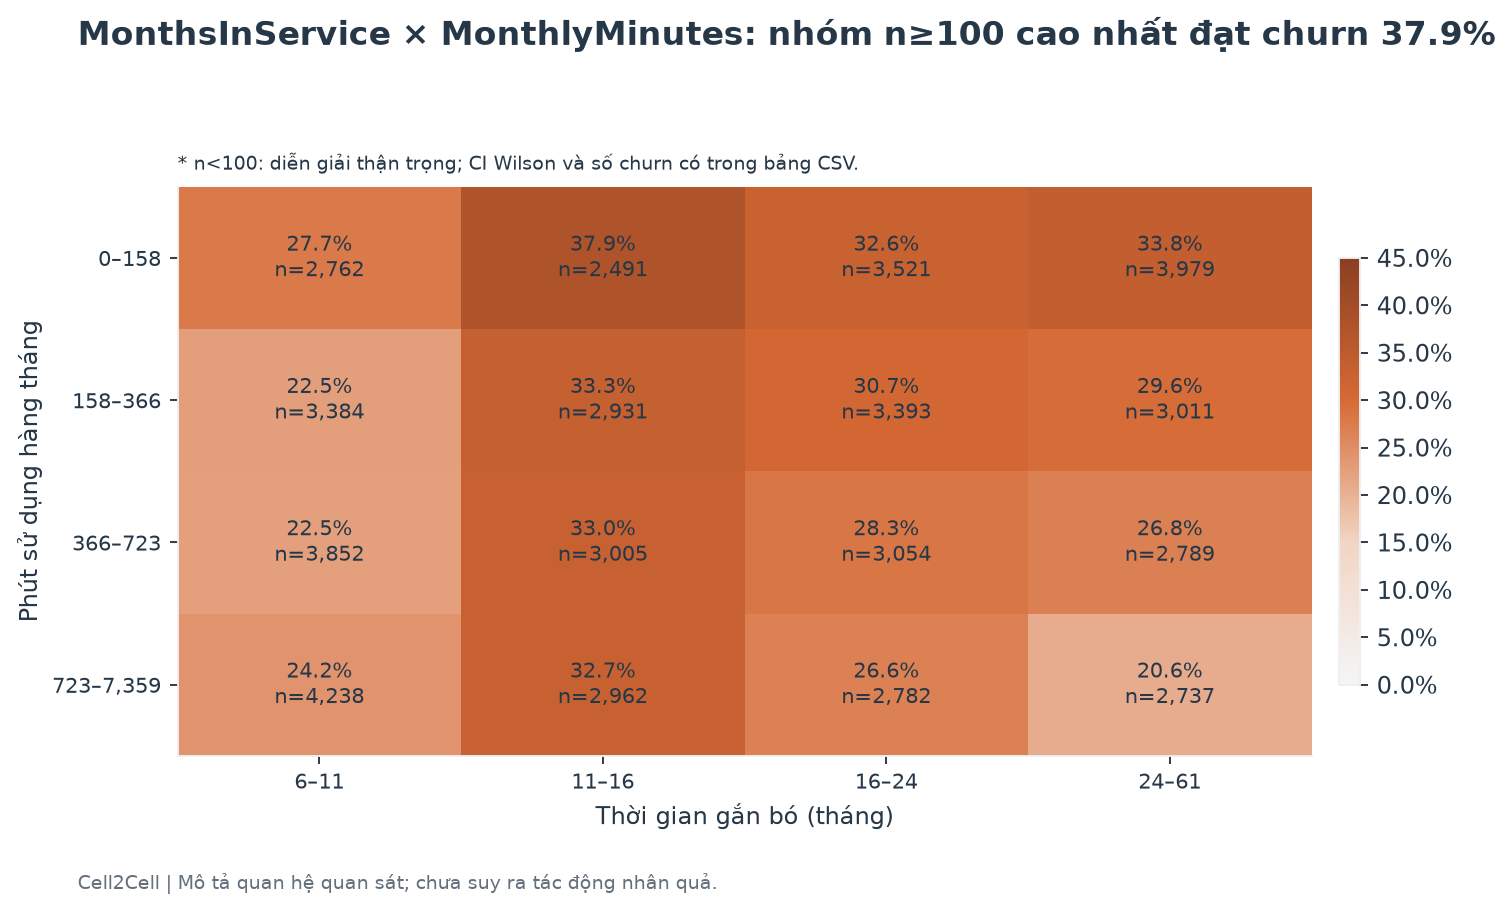

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E26')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm MonthsInService=11–16 và MonthlyMinutes=0–158 có 2,491 khách hàng; churn 37.9% (CI 95% 36.1%–39.9%). Đây là tổ hợp quan sát, chưa xác nhận tương tác nhân quả.

**Business Meaning**

Kết hợp tín hiệu giúp định nghĩa nhóm cần điều tra cụ thể hơn. Khi triển khai, ngưỡng phải học từ tập train và kiểm tra trên cohort tương lai.

**Next Question**

Mức chênh lệch có ổn định trong từng nhóm thời gian gắn bó và trên holdout?

### E27 DroppedCalls × CustomerCareCalls: nhóm n≥100 cao nhất đạt churn 31.5%

**Câu hỏi kinh doanh:** Tổ hợp DroppedCalls và CustomerCareCalls bổ sung thông tin gì?

**Quyết định:** Ưu tiên kiểm tra các tổ hợp đủ quy mô trước khi thiết kế thử nghiệm.

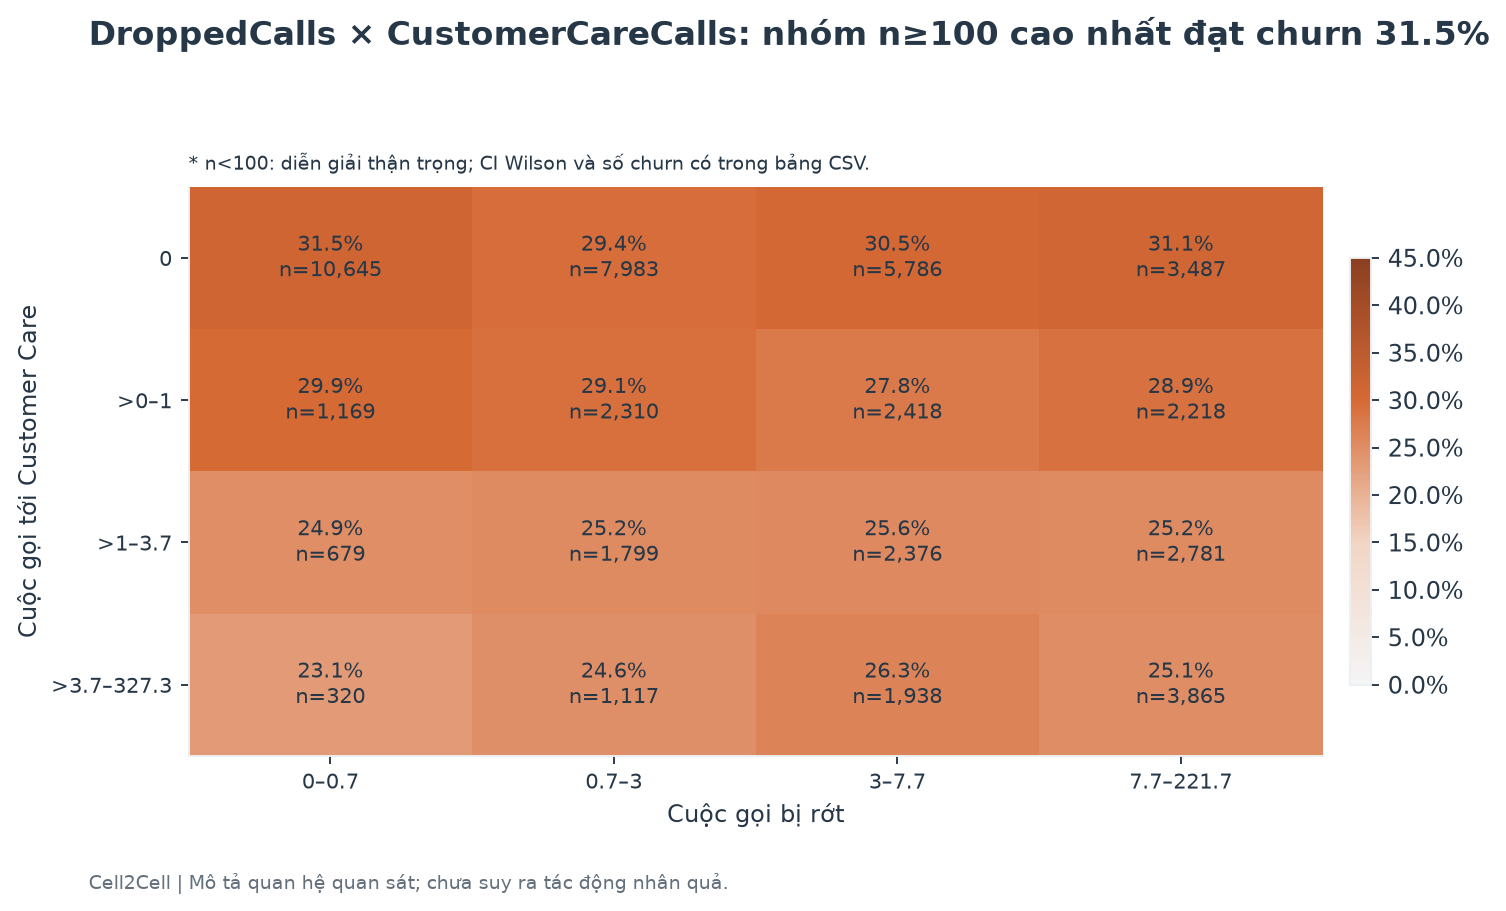

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E27')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm DroppedCalls=0–0.7 và CustomerCareCalls=0 có 10,645 khách hàng; churn 31.5% (CI 95% 30.6%–32.3%). Đây là tổ hợp quan sát, chưa xác nhận tương tác nhân quả.

**Business Meaning**

Kết hợp tín hiệu giúp định nghĩa nhóm cần điều tra cụ thể hơn. Khi triển khai, ngưỡng phải học từ tập train và kiểm tra trên cohort tương lai.

**Next Question**

Mức chênh lệch có ổn định trong từng nhóm thời gian gắn bó và trên holdout?

### E28 PercChangeMinutes × MonthlyRevenue: nhóm n≥100 cao nhất đạt churn 61.0%

**Câu hỏi kinh doanh:** Tổ hợp PercChangeMinutes và MonthlyRevenue bổ sung thông tin gì?

**Quyết định:** Ưu tiên kiểm tra các tổ hợp đủ quy mô trước khi thiết kế thử nghiệm.

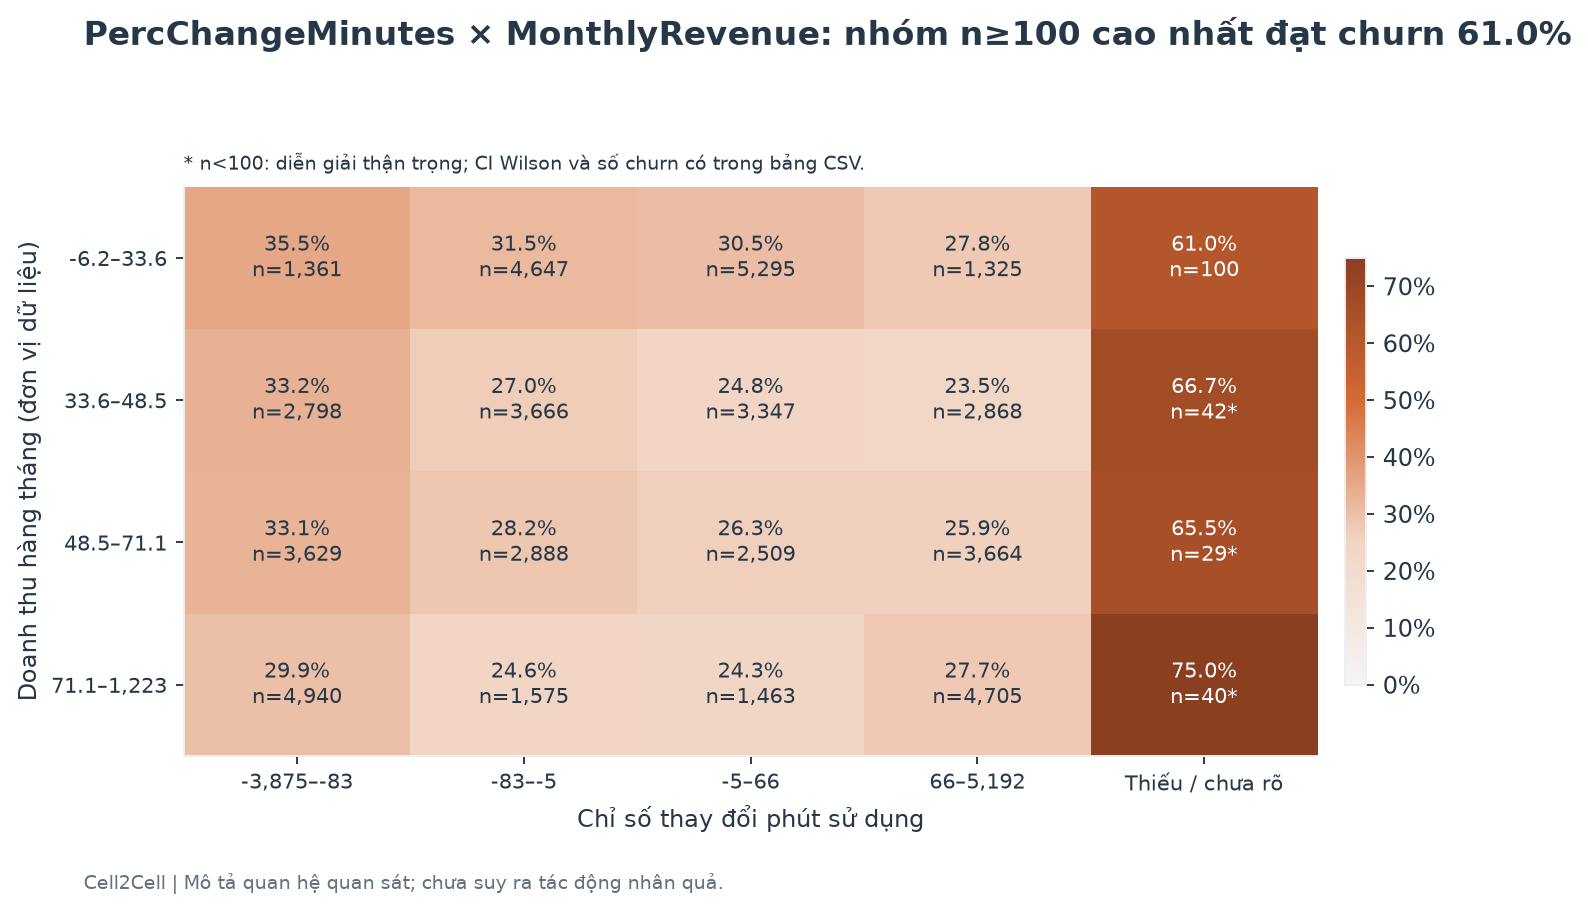

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E28')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm PercChangeMinutes=Thiếu / chưa rõ và MonthlyRevenue=-6.2–33.6 có 100 khách hàng; churn 61.0% (CI 95% 51.2%–70.0%). Đây là tổ hợp quan sát, chưa xác nhận tương tác nhân quả.

**Business Meaning**

Kết hợp tín hiệu giúp định nghĩa nhóm cần điều tra cụ thể hơn. Khi triển khai, ngưỡng phải học từ tập train và kiểm tra trên cohort tương lai.

**Next Question**

Mức chênh lệch có ổn định trong từng nhóm thời gian gắn bó và trên holdout?

### E29 CurrentEquipmentDays × MonthsInService: nhóm n≥100 cao nhất đạt churn 46.7%

**Câu hỏi kinh doanh:** Tổ hợp CurrentEquipmentDays và MonthsInService bổ sung thông tin gì?

**Quyết định:** Ưu tiên kiểm tra các tổ hợp đủ quy mô trước khi thiết kế thử nghiệm.

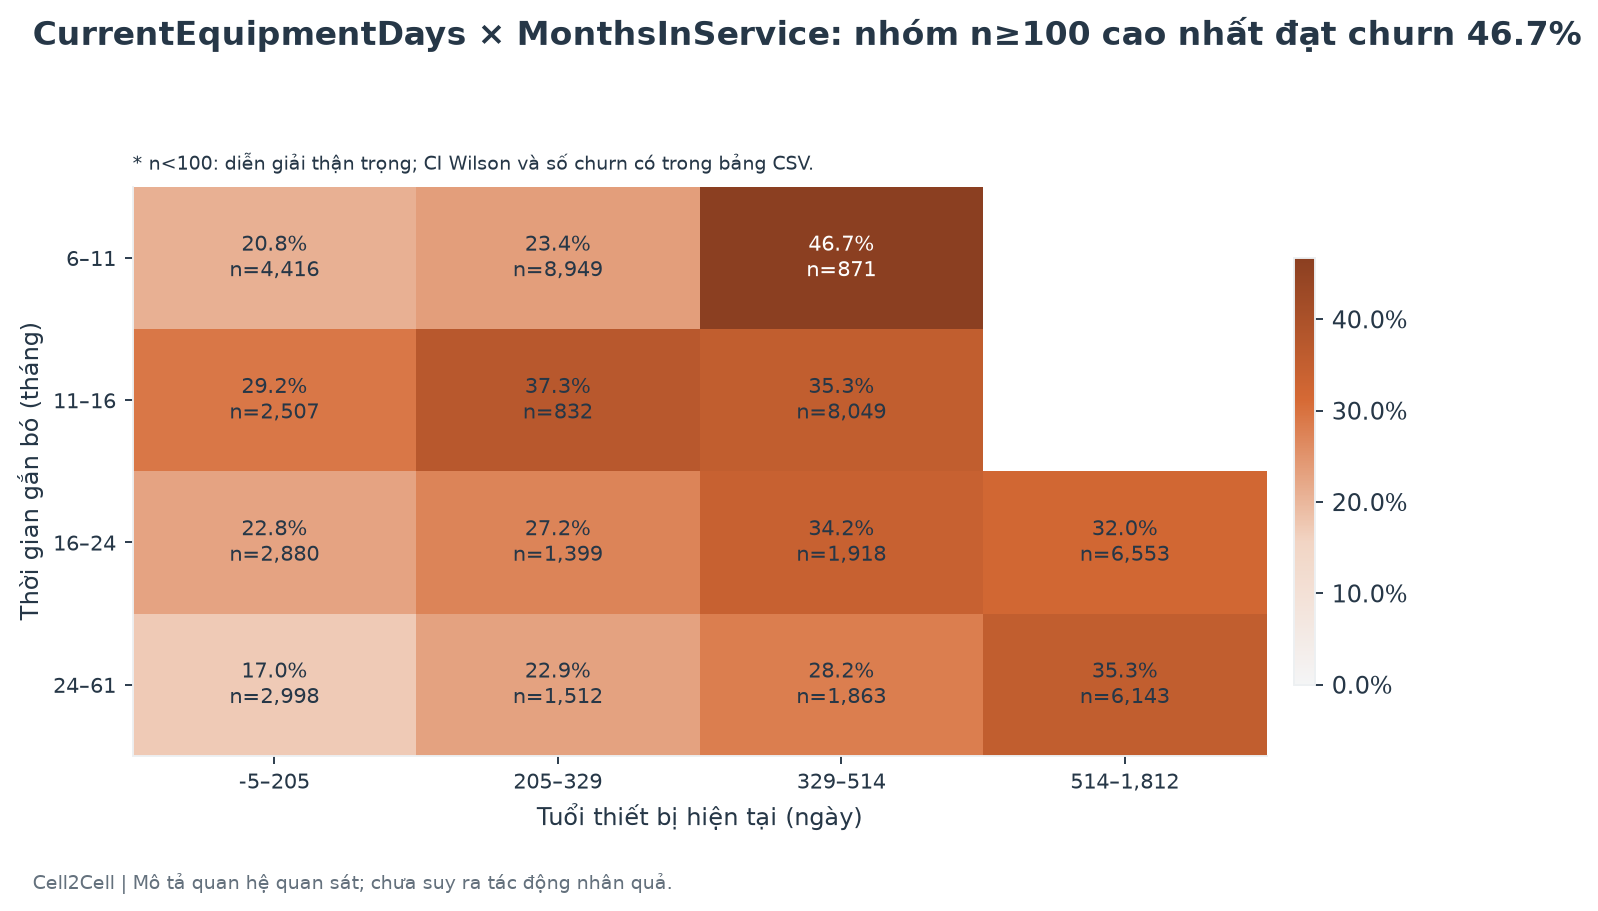

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E29')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Nhóm CurrentEquipmentDays=329–514 và MonthsInService=6–11 có 871 khách hàng; churn 46.7% (CI 95% 43.4%–50.0%). Đây là tổ hợp quan sát, chưa xác nhận tương tác nhân quả.

**Business Meaning**

Kết hợp tín hiệu giúp định nghĩa nhóm cần điều tra cụ thể hơn. Khi triển khai, ngưỡng phải học từ tập train và kiểm tra trên cohort tương lai.

**Next Question**

Mức chênh lệch có ổn định trong từng nhóm thời gian gắn bó và trên holdout?

### E30 CurrentEquipmentDays dẫn đầu liên hệ đơn biến trong nhóm biến liên tục

**Câu hỏi kinh doanh:** Biến liên tục nào phân biệt churn rõ nhất?

**Quyết định:** Đối chiếu với importance trên holdout và dữ liệu vận hành.

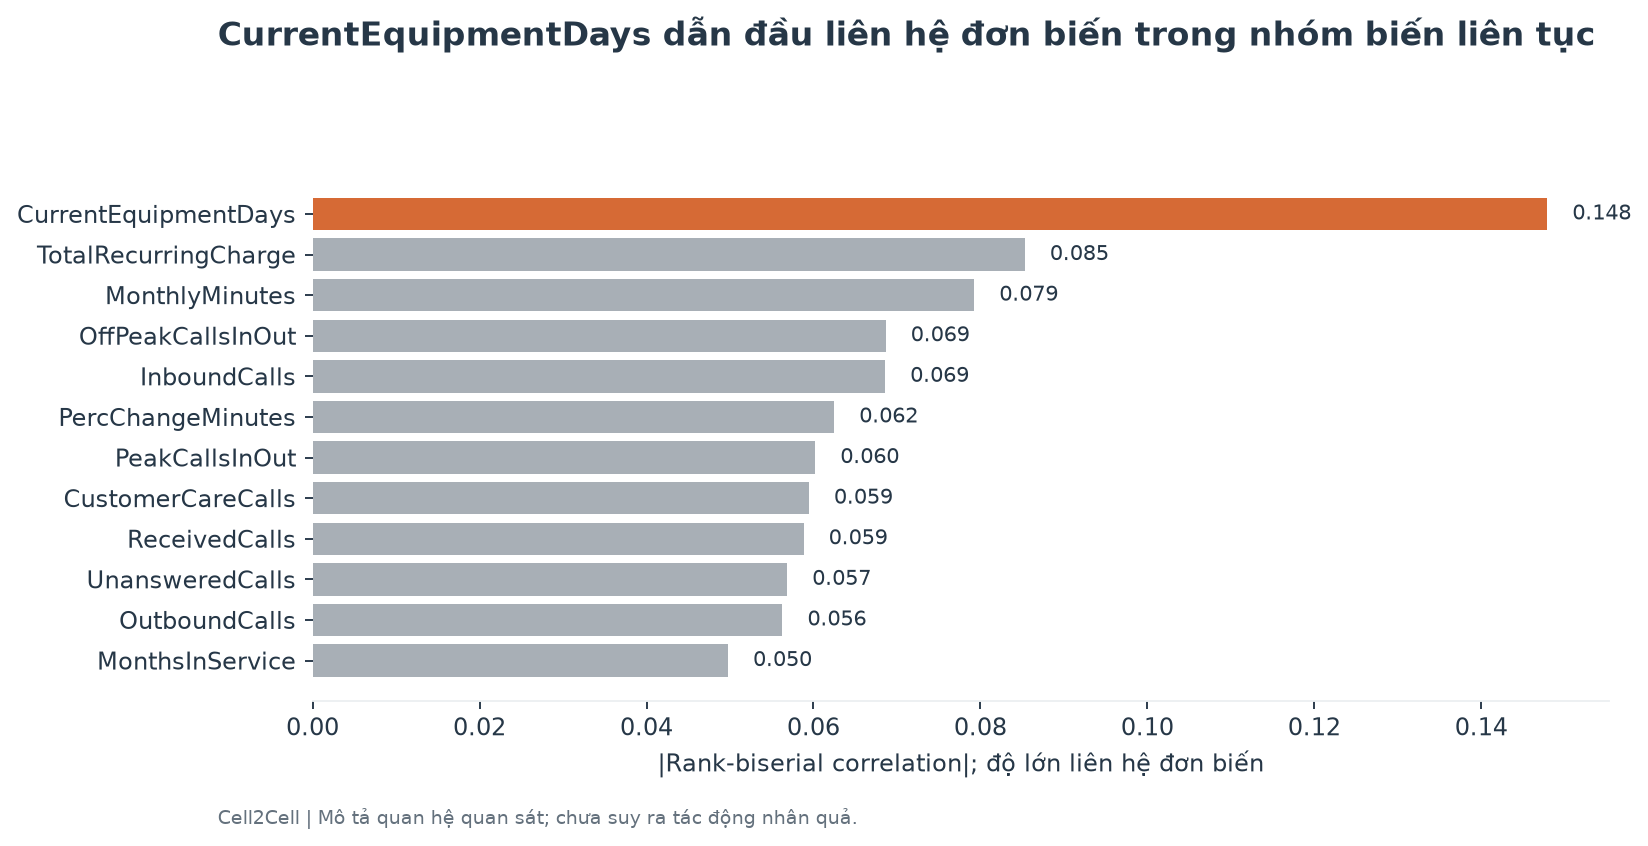

In [ ]:
_chart = next(c for c in eda_charts if c['id'] == 'E30')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Trong các biến số liên tục, CurrentEquipmentDays có độ lớn liên hệ thứ hạng cao nhất (|r|=0.148). Giá trị này là liên hệ đơn biến, không thay thế feature importance của mô hình và không chứng minh nguyên nhân.

**Business Meaning**

Ưu tiên điều tra các tín hiệu có cỡ hiệu ứng đáng kể thay vì chỉ dựa vào p-value vốn nhạy với cỡ mẫu.

**Next Question**

Tín hiệu nào còn đóng góp sau khi kết hợp các biến khác trên test?

In [ ]:
display(pd.read_csv(BASE/'output/analysis/univariate_associations.csv'))

,variable,method,effect,absolute_effect,p_value,n,retention_descriptive_only,q_value_bh
0,CurrentEquipmentDays,Rank-biserial correlation (churn minus non-churn),0.147906,0.147906,7.332534e-151,50890,False,4.032894e-149
1,TotalRecurringCharge,Rank-biserial correlation (churn minus non-churn),-0.085317,0.085317,7.942513e-52,50891,False,1.456127e-50
2,MonthlyMinutes,Rank-biserial correlation (churn minus non-churn),-0.079262,0.079262,1.178761e-44,50891,False,1.080531e-43
3,OffPeakCallsInOut,Rank-biserial correlation (churn minus non-churn),-0.068652,0.068652,5.938049e-34,50891,False,3.628808e-33
4,InboundCalls,Rank-biserial correlation (churn minus non-churn),-0.068586,0.068586,1.031599e-34,50891,False,7.092246e-34
5,RetentionCalls,Cramer V (uncorrected; descriptive),0.067788,0.067788,1.954654e-49,50891,True,2.687649e-48
6,MadeCallToRetentionTeam,Cramer V (uncorrected; descriptive),0.067236,0.067236,5.786185e-52,50891,True,1.456127e-50
7,CreditRating,Cramer V (uncorrected; descriptive),0.066545,0.066545,7.504002e-46,50891,False,8.254402e-45
8,PercChangeMinutes,Rank-biserial correlation (churn minus non-churn),-0.062484,0.062484,3.355437e-28,50680,False,1.677718e-27
9,HandsetWebCapable,Cramer V (uncorrected; descriptive),0.061984,0.061984,1.979282e-44,50891,False,1.555150e-43


## 7 Feature Engineering và Operational Early Warning Model

Bốn tỷ số có ý nghĩa được tạo bằng phép tính theo từng dòng: doanh thu trên phút sử dụng, thuê bao hoạt động trên tổng thuê bao, liên hệ hỗ trợ trên thời lượng và chỉ báo rớt/chặn cuộc gọi trên thời lượng. Mẫu số bằng không tạo missing, không được thay bằng một giá trị tùy ý.

Dữ liệu được chia stratified thành train, validation và test với random state 42. Logistic Regression tạo mốc so sánh; Random Forest và Histogram Gradient Boosting kiểm tra quan hệ phi tuyến. Chọn mô hình dựa trên average precision và chất lượng xếp hạng trên validation. Ngưỡng liên hệ được chọn trên validation cho kịch bản năng lực, rồi đóng băng trước đánh giá test. Kiểm tra hiệu chỉnh sigmoid cũng chỉ dùng train và validation.

Không có mốc snapshot đủ tin cậy nên chưa đánh giá được drift và kết quả ở thời kỳ tương lai. Stratified random split không thay thế được temporal validation khi vận hành.

In [ ]:
# Chạy huấn luyện thực sự từ đầu; không lấy metrics từ kết quả đã lưu.
models.run()
model_summary = json.loads((BASE/'output/analysis/model_summary.json').read_text(encoding='utf-8'))
display(pd.DataFrame(model_summary['splits']).T)
display(pd.DataFrame(model_summary['feature_engineering']))
display(pd.read_csv(BASE/'output/analysis/model_comparison_validation.csv'))
display(pd.DataFrame([model_summary['test']]))
display(pd.DataFrame(model_summary['test_bootstrap_95_ci']).T)
print('Missing policy:', model_summary['missing_policy'])
print('Excluded identifiers:', model_summary['excluded_identifiers'])
print('Excluded leakage:', model_summary['excluded_potential_leakage'])

Acquiring and auditing the official Cell2Cell loader output...


{"raw_rows": 51047, "loader_rows": 50891, "loader_feature_count": 56, "churn_count": 14641, "churn_rate": 0.28769330529956183}


Training Logistic Regression on 30,534 train rows...


Training Random Forest on 30,534 train rows...


Training Histogram Gradient Boosting on 30,534 train rows...


...

,feature,formula
0,AgeHH1,0 is not an adult household age: treated as un...
1,AgeHH2,0 is not an adult household age: treated as un...
2,IncomeGroup,0 -> Unknown; other codes treated as categorie...
3,HandsetPrice,Numeric price; Unknown -> missing; train media...
4,revenue_per_minute,1 * MonthlyRevenue / MonthlyMinutes; denominat...
5,active_sub_ratio,1 * ActiveSubs / UniqueSubs; denominator=0 -> ...
6,care_calls_per_1000_minutes,1000 * CustomerCareCalls / MonthlyMinutes; den...
7,quality_calls_per_1000_minutes,1000 * DroppedBlockedCalls / MonthlyMinutes; d...


,model,split,threshold,n,churn_count,churn_rate,accuracy,precision,recall,f1,roc_auc,pr_auc_average_precision,brier_score,log_loss,targeted_n,targeted_fraction,tn,fp,fn,tp,precision_top10,capture_top20,lift_top10,fit_seconds
0,Histogram Gradient Boosting,validation,0.5,10178,2928,0.287679,0.724209,0.616570,0.109290,0.185669,0.665981,0.447485,0.189809,0.562930,519,0.050992,7051,199,2608,320,0.549116,0.332309,1.908778,4.486412
1,Random Forest,validation,0.5,10178,2928,0.287679,0.715661,0.619718,0.030055,0.057329,0.661270,0.436264,0.191860,0.567241,142,0.013952,7196,54,2840,88,0.524558,0.318989,1.823412,9.617420
2,Logistic Regression,validation,0.5,10178,2928,0.287679,0.714580,0.543396,0.049180,0.090197,0.618876,0.392817,0.197437,0.582119,265,0.026037,7129,121,2784,144,0.456778,0.292008,1.587803,1.810394


,threshold,n,churn_count,churn_rate,accuracy,precision,recall,f1,roc_auc,pr_auc_average_precision,brier_score,log_loss,targeted_n,targeted_fraction,tn,fp,fn,tp
0,0.388961,10179,2928,0.287651,0.711367,0.497542,0.345628,0.4079,0.685728,0.466648,0.186485,0.554516,2034,0.199823,6229,1022,1916,1012


,lower_95,upper_95
roc_auc,0.675237,0.698000
pr_auc_average_precision,0.446868,0.486593
precision_top10,0.537328,0.601179
capture_top10,0.188856,0.208743
lift_top10,1.888371,2.087226


Missing policy: AgeHH1/AgeHH2 zero -> missing; IncomeGroup zero -> Unknown and remaining codes categorical; HandsetPrice parsed numeric with Unknown -> missing. Numeric median plus missing indicator; categorical Unknown. All imputation/scaling/encoding fitted within each training partition.
Excluded identifiers: ['CustomerID', 'ServiceArea']
Excluded leakage: ['RetentionCalls', 'RetentionOffersAccepted', 'MadeCallToRetentionTeam']


## 8 Model Evaluation Interpretability và Threshold Analysis

Average precision đánh giá chất lượng xếp hạng trong Precision–Recall; ROC AUC đánh giá phân biệt tổng thể. Precision, recall và số người được chọn thay đổi theo ngưỡng. Đánh giá test dùng cấu hình và ngưỡng đã đóng băng. Khoảng bootstrap phản ánh biến thiên trên tập test quan sát, chưa bao gồm drift ở thời gian mới.

Coefficient của Logistic Regression cho biết chiều liên hệ trong cấu trúc mô hình. Permutation importance đo mức suy giảm chất lượng khi xáo trộn một trường và có thể bị phân tán bởi các trường tương quan. Cả hai đều không phải tác động nhân quả.

In [ ]:
risk_scores, model_charts = riskviz.run()
display(pd.read_csv(BASE/'output/analysis/threshold_analysis_validation.csv'))
display(pd.read_csv(BASE/'output/analysis/logistic_coefficients.csv').head(25))
display(pd.read_csv(BASE/'output/analysis/permutation_importance_test.csv').head(20))

Risk scores: 50,891; historical non-churn candidates: 36,250; charts: 11


,threshold,n,churn_count,churn_rate,accuracy,precision,recall,f1,roc_auc,pr_auc_average_precision,brier_score,log_loss,targeted_n,targeted_fraction,tn,fp,fn,tp
0,0.050000,10178,2928,0.287679,0.287679,0.287679,1.000000,0.446818,0.665981,0.447485,0.189809,0.56293,10178,1.000000,0,7250,0,2928
1,0.075000,10178,2928,0.287679,0.291315,0.288646,0.999317,0.447914,0.665981,0.447485,0.189809,0.56293,10137,0.995972,39,7211,2,2926
2,0.100000,10178,2928,0.287679,0.317744,0.295394,0.990096,0.455031,0.665981,0.447485,0.189809,0.56293,9814,0.964237,335,6915,29,2899
3,0.125000,10178,2928,0.287679,0.357831,0.305603,0.968579,0.464613,0.665981,0.447485,0.189809,0.56293,9280,0.911770,806,6444,92,2836
4,0.150000,10178,2928,0.287679,0.395068,0.315084,0.939549,0.471910,0.665981,0.447485,0.189809,0.56293,8731,0.857831,1270,5980,177,2751
5,0.175000,10178,2928,0.287679,0.436235,0.326543,0.903347,0.479688,0.665981,0.447485,0.189809,0.56293,8100,0.795834,1795,5455,283,2645
6,0.200000,10178,2928,0.287679,0.476813,0.339279,0.864071,0.487241,0.665981,0.447485,0.189809,0.56293,7457,0.732659,2323,4927,398,2530
7,0.225000,10178,2928,0.287679,0.515425,0.352734,0.819672,0.493218,0.665981,0.447485,0.189809,0.56293,6804,0.668501,2846,4404,528,2400
8,0.250000,10178,2928,0.287679,0.550108,0.363621,0.751708,0.490146,0.665981,0.447485,0.189809,0.56293,6053,0.594714,3398,3852,727,2201
9,0.275000,10178,2928,0.287679,0.587738,0.378869,0.677254,0.485910,0.665981,0.447485,0.189809,0.56293,5234,0.514246,3999,3251,945,1983


,encoded_feature,coefficient,odds_ratio,absolute_coefficient
0,numeric__CurrentEquipmentDays,0.351917,1.421791,0.351917
1,categorical__CreditRating_5-Low,-0.291833,0.746894,0.291833
2,categorical__IncomeGroup_Group 2,0.186653,1.205209,0.186653
3,numeric__MonthsInService,-0.186247,0.830069,0.186247
4,numeric__PercChangeMinutes,-0.165180,0.847741,0.165180
5,categorical__HandsetRefurbished_No,-0.154320,0.856998,0.154320
6,categorical__CreditRating_3-Good,0.145477,1.156591,0.145477
7,numeric__MonthlyMinutes,-0.142932,0.866813,0.142932
8,categorical__IncomeGroup_Group 8,-0.139422,0.869861,0.139422
9,numeric__PercChangeRevenues,0.138106,1.148098,0.138106


,feature,importance_mean_pr_auc_decrease,importance_std
0,PercChangeMinutes,0.069077,0.002959
1,MonthsInService,0.042802,0.001822
2,CurrentEquipmentDays,0.039147,0.002319
3,MonthlyMinutes,0.036626,0.002299
4,TotalRecurringCharge,0.011876,0.001675
5,revenue_per_minute,0.009365,0.001051
6,PercChangeRevenues,0.008169,0.001372
7,CreditRating,0.006742,0.001139
8,quality_calls_per_1000_minutes,0.006634,0.001707
9,Handsets,0.005064,0.001873


### M01 Histogram Gradient Boosting dẫn đầu xếp hạng trên validation

**Câu hỏi kinh doanh:** Mức cải thiện so với Logistic Regression có đủ để bù độ phức tạp?

**Quyết định:** Chọn theo chất lượng xếp hạng và xem xét khả năng vận hành.

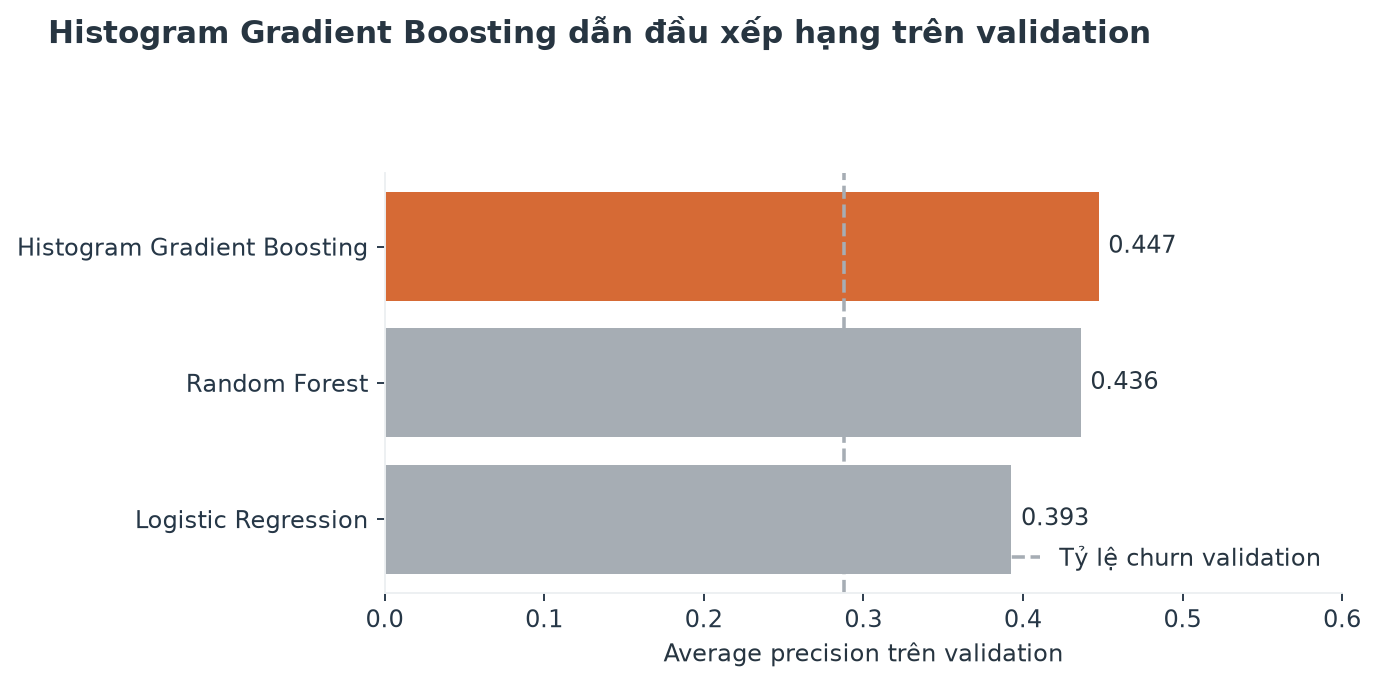

In [ ]:
_chart = next(c for c in model_charts if c['id'] == 'M01')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Average precision validation của mô hình được chọn là 0.447.

**Business Meaning**

Chọn theo chất lượng xếp hạng và xem xét khả năng vận hành.

**Next Question**

Mức cải thiện so với Logistic Regression có đủ để bù độ phức tạp?

### M02 ROC AUC trên test đạt 0.686

**Câu hỏi kinh doanh:** Chất lượng xếp hạng có ổn định trên kỳ dữ liệu tiếp theo?

**Quyết định:** Kết quả là bằng chứng đánh giá lịch sử; cần backtest theo thời gian khi có snapshot.

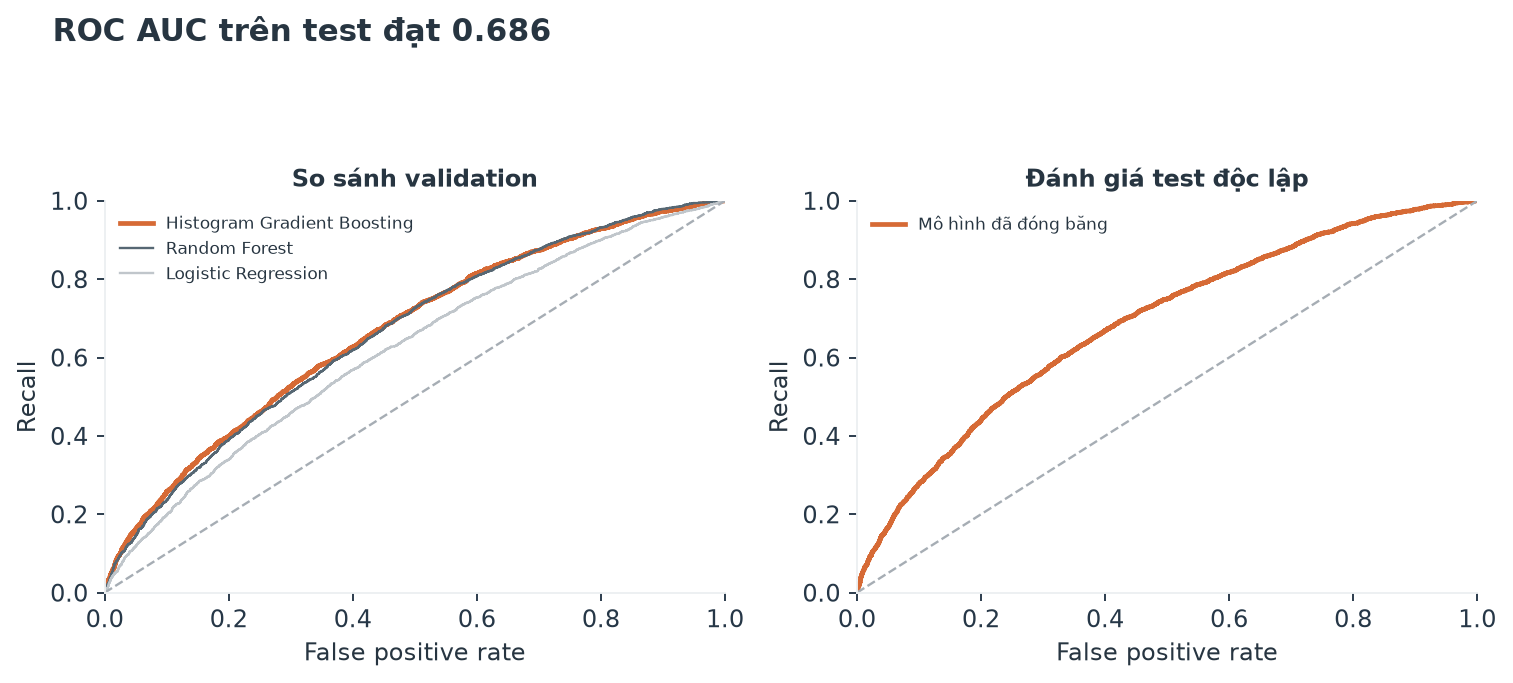

In [ ]:
_chart = next(c for c in model_charts if c['id'] == 'M02')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Kết quả test được tính sau khi chọn mô hình và ngưỡng bằng validation; roc_auc=0.686.

**Business Meaning**

Kết quả là bằng chứng đánh giá lịch sử; cần backtest theo thời gian khi có snapshot.

**Next Question**

Chất lượng xếp hạng có ổn định trên kỳ dữ liệu tiếp theo?

### M03 Average precision trên test đạt 0.467

**Câu hỏi kinh doanh:** Chất lượng xếp hạng có ổn định trên kỳ dữ liệu tiếp theo?

**Quyết định:** Kết quả là bằng chứng đánh giá lịch sử; cần backtest theo thời gian khi có snapshot.

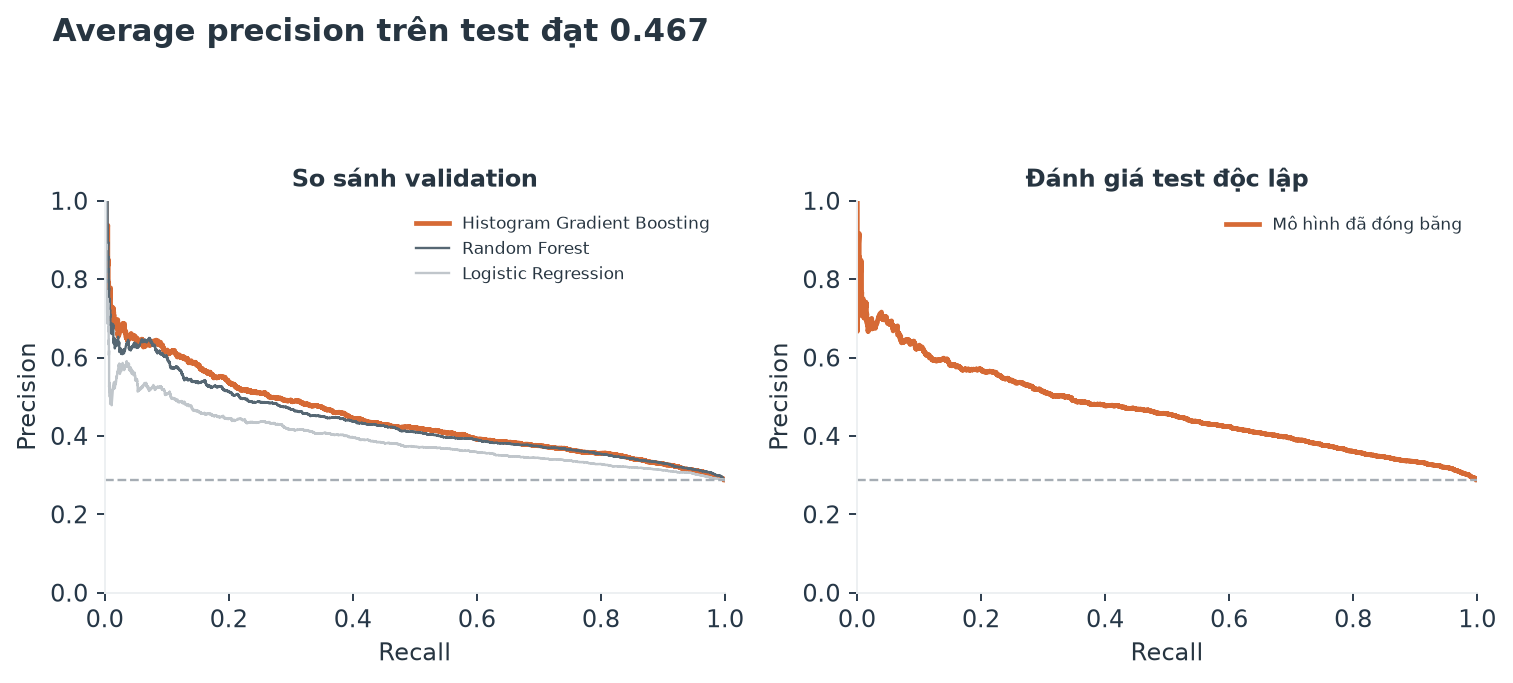

In [ ]:
_chart = next(c for c in model_charts if c['id'] == 'M03')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Kết quả test được tính sau khi chọn mô hình và ngưỡng bằng validation; pr_auc_average_precision=0.467.

**Business Meaning**

Kết quả là bằng chứng đánh giá lịch sử; cần backtest theo thời gian khi có snapshot.

**Next Question**

Chất lượng xếp hạng có ổn định trên kỳ dữ liệu tiếp theo?

### M04 Ngưỡng 0.389 tương ứng kịch bản năng lực top 20%

**Câu hỏi kinh doanh:** Năng lực thực tế và chi phí liên hệ là bao nhiêu?

**Quyết định:** Đội retention cần xác nhận năng lực và chi phí trước khi chốt ngưỡng chiến dịch.

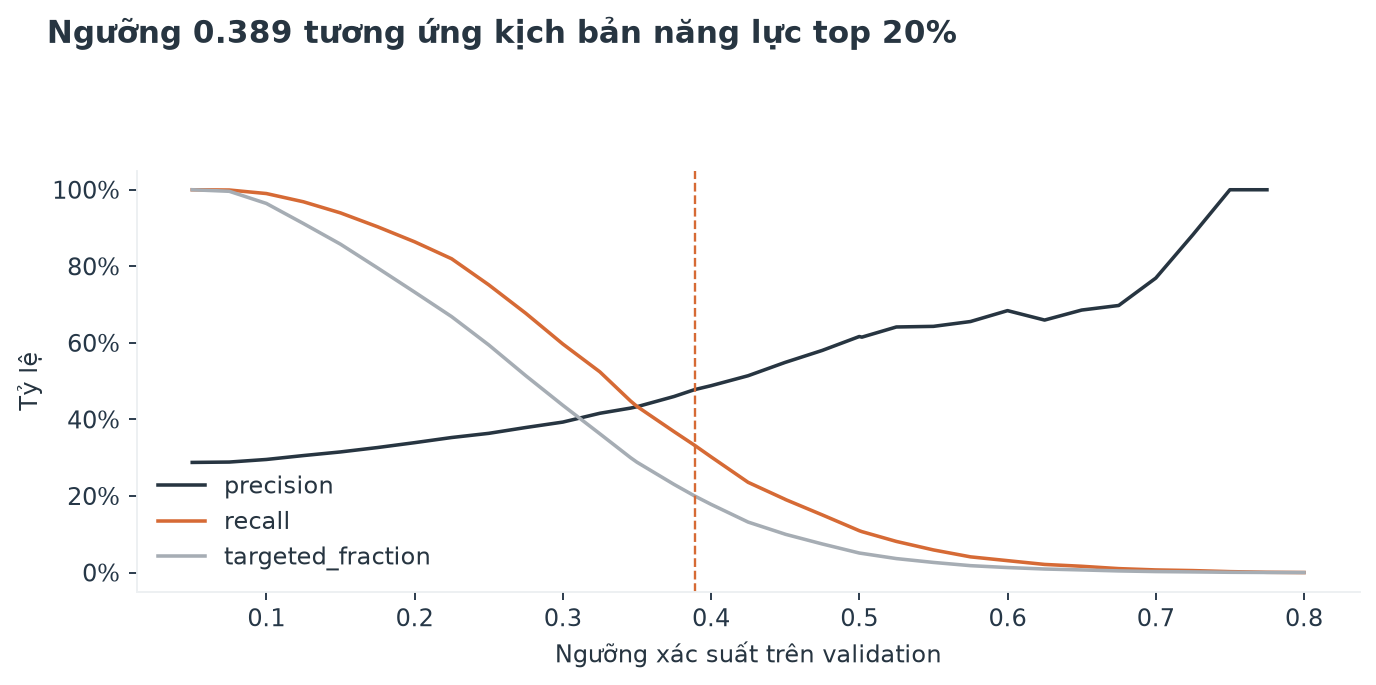

In [ ]:
_chart = next(c for c in model_charts if c['id'] == 'M04')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Ngưỡng được lấy từ phân vị validation cho kịch bản liên hệ 20%; chưa có năng lực vận hành thực tế được cung cấp.

**Business Meaning**

Đội retention cần xác nhận năng lực và chi phí trước khi chốt ngưỡng chiến dịch.

**Next Question**

Năng lực thực tế và chi phí liên hệ là bao nhiêu?

### M05 Mô hình nhận diện 1,012 churner và bỏ sót 1,916 trên test

**Câu hỏi kinh doanh:** Can thiệp chi phí thấp có phù hợp nhóm dương tính giả?

**Quyết định:** False positive tiêu tốn chăm sóc; false negative là cơ hội bị bỏ lỡ. Không suy ra số người có thể giữ chân.

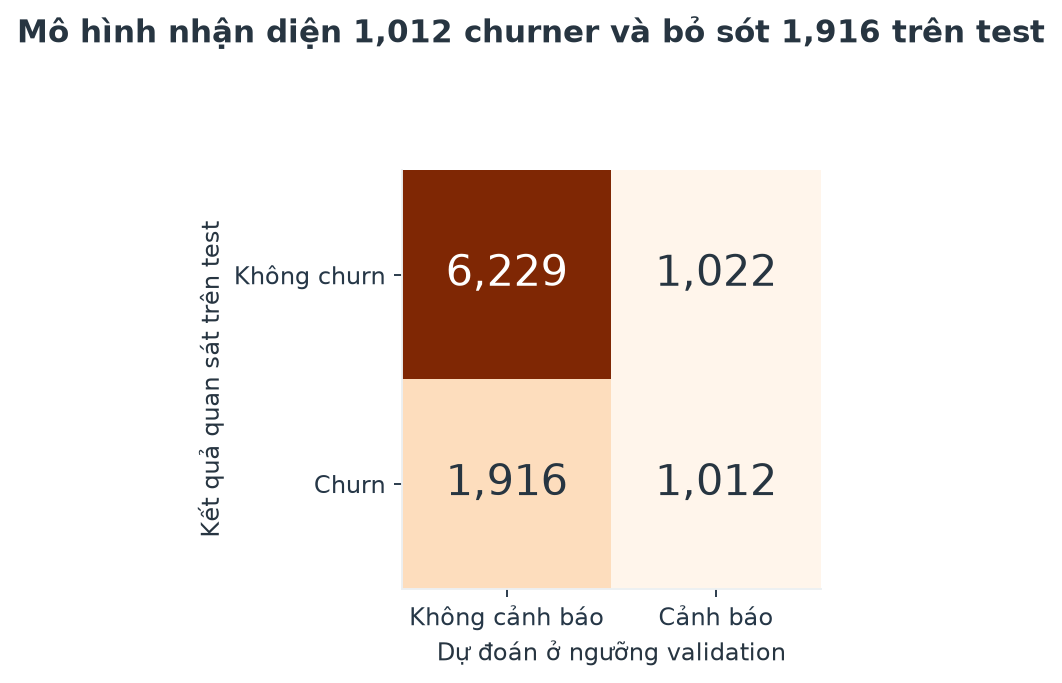

In [ ]:
_chart = next(c for c in model_charts if c['id'] == 'M05')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Có 1,022 false positive và 1,916 false negative tại ngưỡng đã đóng băng.

**Business Meaning**

False positive tiêu tốn chăm sóc; false negative là cơ hội bị bỏ lỡ. Không suy ra số người có thể giữ chân.

**Next Question**

Can thiệp chi phí thấp có phù hợp nhóm dương tính giả?

### M06 Brier score trên test bằng 0.186

**Câu hỏi kinh doanh:** Sai lệch hiệu chỉnh có tăng theo thời gian?

**Quyết định:** Xác suất cần được theo dõi độ hiệu chỉnh khi áp dụng cho cohort và thời điểm mới.

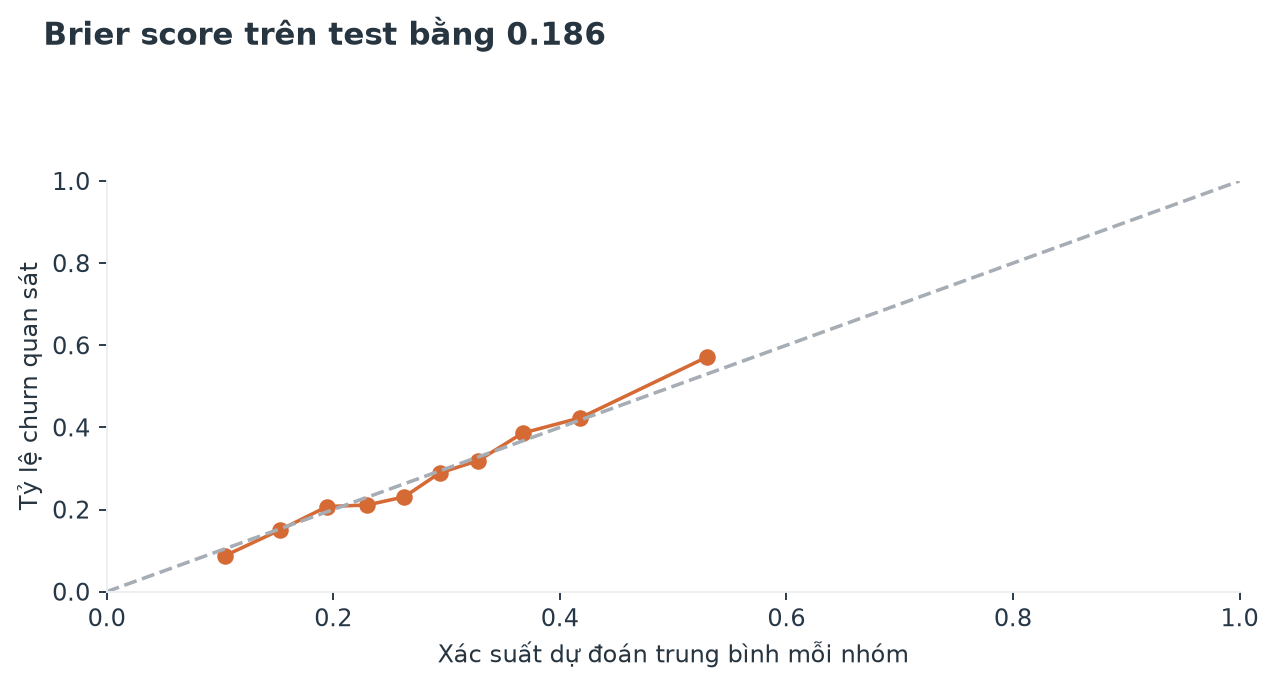

In [ ]:
_chart = next(c for c in model_charts if c['id'] == 'M06')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Kiểm tra hiệu chỉnh dùng các nhóm phân vị xác suất trên test; calibrated=False.

**Business Meaning**

Xác suất cần được theo dõi độ hiệu chỉnh khi áp dụng cho cohort và thời điểm mới.

**Next Question**

Sai lệch hiệu chỉnh có tăng theo thời gian?

### M07 PercChangeMinutes có mức đóng góp xếp hạng lớn nhất khi hoán vị

**Câu hỏi kinh doanh:** Kết quả còn ổn định nếu bỏ các biến tương quan?

**Quyết định:** Đây là phụ thuộc dự báo của mô hình, chịu ảnh hưởng của tương quan giữa các biến.

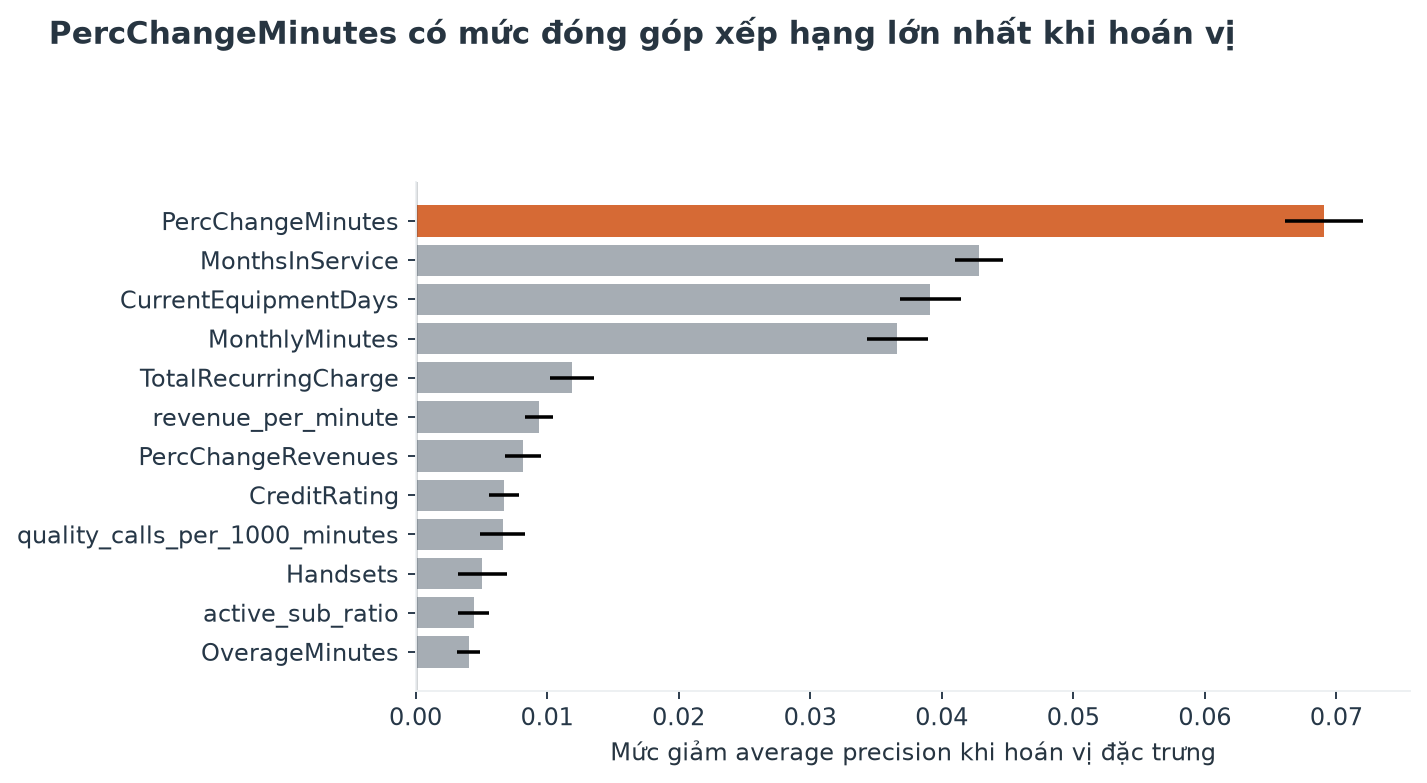

In [ ]:
_chart = next(c for c in model_charts if c['id'] == 'M07')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Permutation importance lớn nhất trong lần đánh giá là PercChangeMinutes; độ biến thiên được thể hiện bằng thanh sai số.

**Business Meaning**

Đây là phụ thuộc dự báo của mô hình, chịu ảnh hưởng của tương quan giữa các biến.

**Next Question**

Kết quả còn ổn định nếu bỏ các biến tương quan?

## 9 Customer Risk Scoring Segmentation và Prioritization

Điểm lịch sử được tạo bằng năm fold: từng khách hàng được chấm bởi mô hình không fit nhãn của chính người đó. Cấu hình được chọn từ cùng dữ liệu lịch sử nên metrics OOF không thay thế kết quả test độc lập. Mô hình production fit toàn bộ lịch sử được lưu riêng sau khi đóng đánh giá.

Các ngưỡng Low, Medium, High và Very High Risk lấy từ phân vị validation. Giá trị dùng MonthlyRevenue không âm; đây là đại diện giá trị, chưa phải CLV. Các cờ dấu hiệu chỉ được dùng khi nhóm tương ứng trong train có quy mô đủ và churn rate cao hơn baseline. Chúng mô tả hồ sơ đi kèm, không phải giải thích đóng góp cục bộ của từng dự đoán.

P1 kết hợp giá trị cao và rủi ro cao; P2 là giá trị cao với rủi ro trung bình; P3 dùng chăm sóc chi phí thấp cho giá trị thấp hơn với rủi ro từ trung bình; P4 theo dõi. Thứ tự trong nhóm dùng xác suất nhân đại diện giá trị và không thể được diễn giải là doanh thu sẽ cứu được.

In [ ]:
risk_summary = json.loads((BASE/'output/analysis/risk_summary.json').read_text(encoding='utf-8'))
display(pd.read_csv(BASE/'output/analysis/personas.csv'))
display(pd.read_csv(BASE/'output/analysis/risk_segments.csv'))
display(pd.read_csv(BASE/'output/analysis/priority_summary.csv'))
display(pd.DataFrame(risk_summary['signal_evidence_train']).T)
display(risk_scores.head(15)[['customer_id','churn_probability','risk_segment','priority_level','key_risk_signals','observed_churn','recommended_action']])
assert risk_scores.customer_id.is_unique
assert risk_scores.churn_probability.between(0,1).all()
assert len(risk_scores) == len(frame)
assert not risk_scores[['customer_id','churn_probability','risk_segment','priority_level','recommended_action']].isna().any().any()

,customer_persona,customers,actual_churn,churn_rate,mean_probability,monthly_revenue_mean,monthly_minutes_mean,value_proxy_sum,recommended_action
0,Giá trị cao và rủi ro cao,4882,2348,0.480950,0.467081,87.606338,647.558583,427694.14,"Ưu tiên tư vấn cá nhân; kiểm tra chất lượng, g..."
1,Nhóm theo dõi và duy trì quan hệ,40837,9733,0.238338,0.241878,58.939683,553.659451,2406926.02,Theo dõi định kỳ và chăm sóc theo nhu cầu; chư...
2,Rủi ro cao còn lại,2239,1129,0.504243,0.484838,29.177820,150.782046,65337.52,Chăm sóc tự động và khảo sát ngắn; chuyển chuy...
3,Rủi ro cao kèm giảm sử dụng,1392,709,0.509339,0.473919,35.304109,359.544540,49143.32,Xác minh thay đổi nhu cầu; tư vấn gói cước và ...
4,Rủi ro cao kèm thiết bị sử dụng lâu,1541,722,0.468527,0.467327,29.240558,91.998053,45059.70,Kiểm tra khả năng đáp ứng của thiết bị; tư vấn...


,risk_segment,customers,actual_churn,churn_rate,mean_probability
0,High Risk,5039,2162,0.429053,0.416467
1,Low Risk,25640,4722,0.184165,0.189427
2,Medium Risk,15197,5011,0.329736,0.330371
3,Very High Risk,5015,2746,0.547557,0.527839


,priority_level,customers,actual_churn,churn_rate,mean_probability,value_proxy_sum
0,P1,4882,2348,0.480950,0.467081,427694.14
1,P2,6746,2198,0.325823,0.330084,563312.39
2,P3,13623,5373,0.394407,0.386061,428564.82
3,P4,25640,4722,0.184165,0.189427,1574589.35


,train_customers,train_churn_rate,wilson_lower_95,train_baseline,included_as_risk_signal
usage_decline,7629,0.317997,0.307641,0.287712,True
revenue_decline,7629,0.290733,0.28065,0.287712,False
quality,7600,0.279737,0.269758,0.287712,False
care,7289,0.253258,0.243407,0.287712,False
equipment,7628,0.336261,0.325744,0.287712,True
tenure_band,6772,0.342292,0.331083,0.287712,True


,customer_id,churn_probability,risk_segment,priority_level,key_risk_signals,observed_churn,recommended_action
24002,3189262,0.436951,High Risk,P1,Mức thay đổi sử dụng thuộc tứ phân vị thấp; Th...,0,"Ưu tiên tư vấn cá nhân; kiểm tra chất lượng, g..."
31086,3247882,0.569399,Very High Risk,P1,Tổ hợp đặc trưng được mô hình nhận diện; cần x...,1,Đã ghi nhận churn trong dữ liệu lịch sử; chỉ p...
23445,3184774,0.427458,High Risk,P1,Tuổi thiết bị cao hơn Q75,0,"Ưu tiên tư vấn cá nhân; kiểm tra chất lượng, g..."
7603,3059858,0.423471,High Risk,P1,Mức thay đổi sử dụng thuộc tứ phân vị thấp,1,Đã ghi nhận churn trong dữ liệu lịch sử; chỉ p...
45967,3364034,0.568998,Very High Risk,P1,Tổ hợp đặc trưng được mô hình nhận diện; cần x...,0,"Ưu tiên tư vấn cá nhân; kiểm tra chất lượng, g..."
24836,3196158,0.547915,Very High Risk,P1,Thời gian gắn bó giữa Q25 và trung vị huấn luyện,1,Đã ghi nhận churn trong dữ liệu lịch sử; chỉ p...
24673,3194730,0.516325,Very High Risk,P1,Thời gian gắn bó giữa Q25 và trung vị huấn luyện,0,"Ưu tiên tư vấn cá nhân; kiểm tra chất lượng, g..."
37618,3300310,0.441975,High Risk,P1,Mức thay đổi sử dụng thuộc tứ phân vị thấp; Th...,0,"Ưu tiên tư vấn cá nhân; kiểm tra chất lượng, g..."
26139,3206798,0.395917,High Risk,P1,Mức thay đổi sử dụng thuộc tứ phân vị thấp; Th...,0,"Ưu tiên tư vấn cá nhân; kiểm tra chất lượng, g..."
39688,3316738,0.469366,Very High Risk,P1,Tổ hợp đặc trưng được mô hình nhận diện; cần x...,0,"Ưu tiên tư vấn cá nhân; kiểm tra chất lượng, g..."


### M10 4,882 khách hàng thuộc nhóm giá trị cao và rủi ro cao

**Câu hỏi kinh doanh:** Có bao nhiêu người còn hoạt động ở snapshot triển khai?

**Quyết định:** Danh sách ưu tiên kết hợp rủi ro và giá trị, cần xác nhận trạng thái hiện tại trước liên hệ.

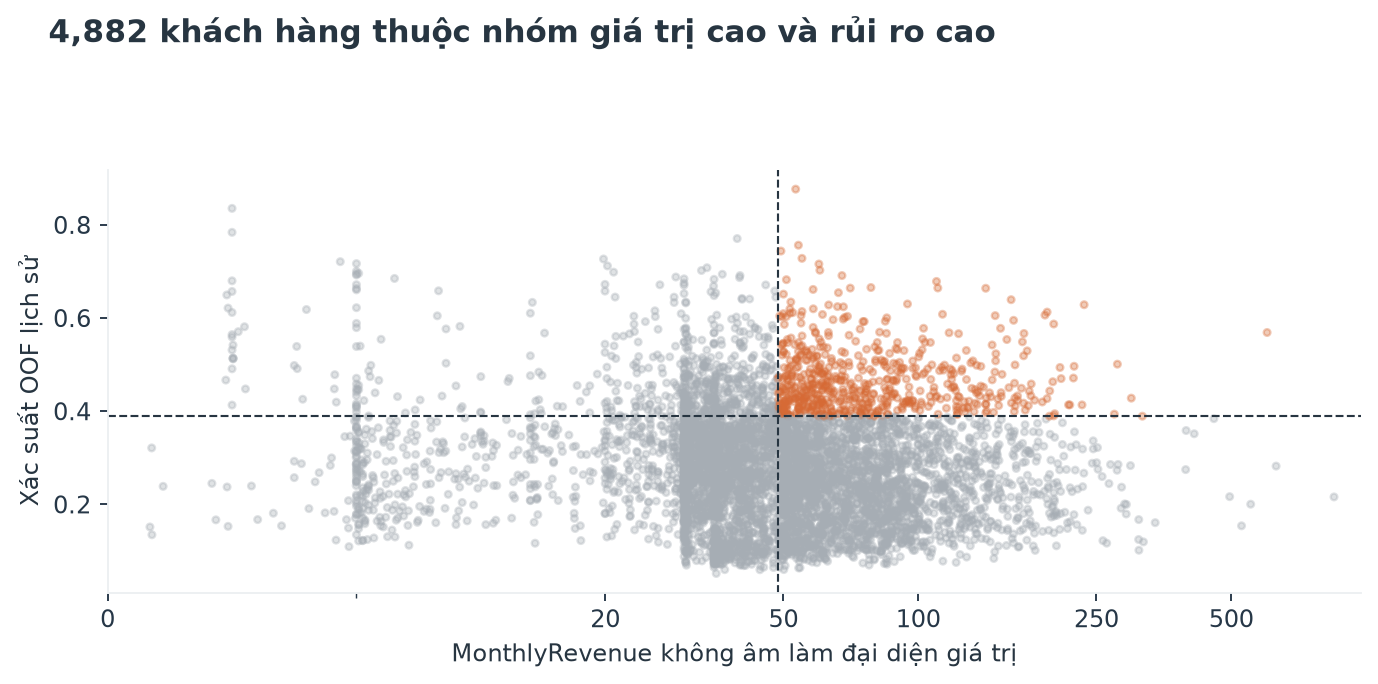

In [ ]:
_chart = next(c for c in model_charts if c['id'] == 'M10')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

P1 chiếm 9.6% cohort lịch sử; trục giá trị dùng thang symlog để giữ cả mức bằng không và giá trị lớn.

**Business Meaning**

Danh sách ưu tiên kết hợp rủi ro và giá trị, cần xác nhận trạng thái hiện tại trước liên hệ.

**Next Question**

Có bao nhiêu người còn hoạt động ở snapshot triển khai?

### M11 Phân vị validation định nghĩa bốn mức rủi ro lịch sử

**Câu hỏi kinh doanh:** Quy mô từng nhóm có thay đổi ở snapshot mới?

**Quyết định:** Ngưỡng phân vị tạo thứ tự ưu tiên, cần điều chỉnh theo năng lực và dữ liệu kỳ triển khai.

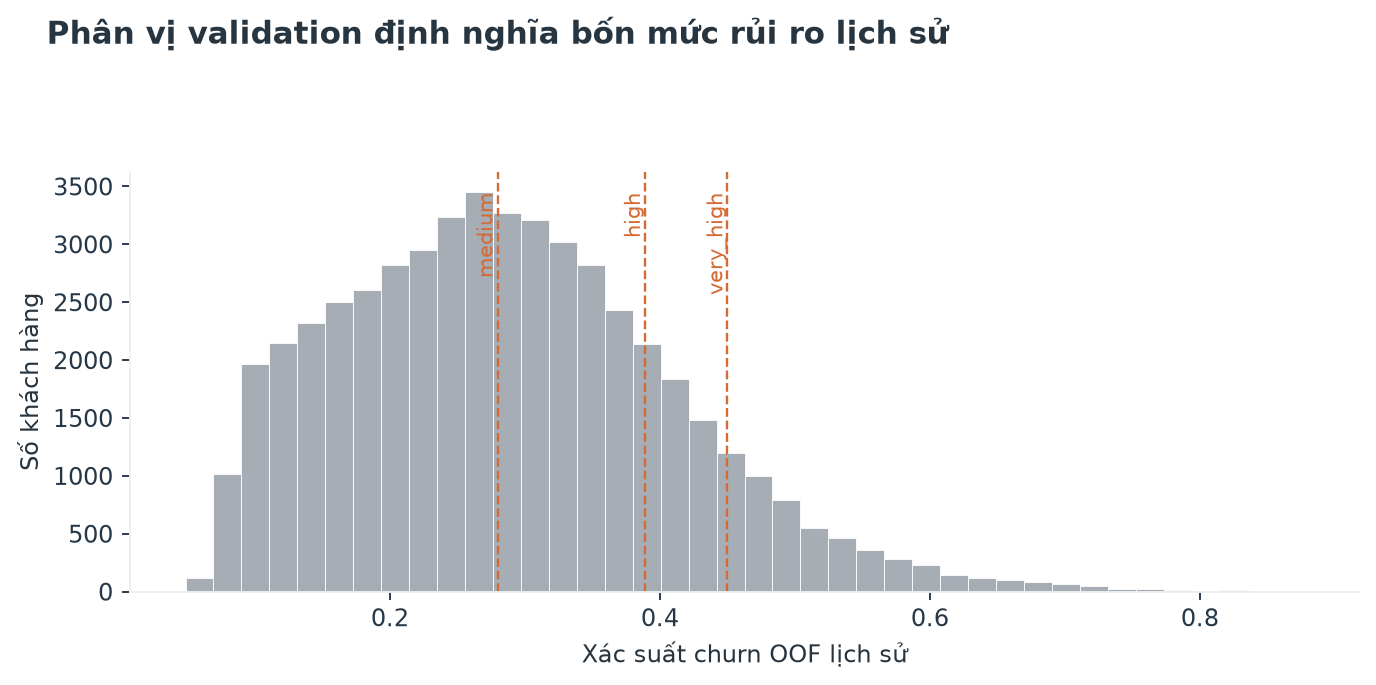

In [ ]:
_chart = next(c for c in model_charts if c['id'] == 'M11')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Ngưỡng Medium=0.280, High=0.389 và Very High=0.450; áp dụng cho 50,891 điểm OOF.

**Business Meaning**

Ngưỡng phân vị tạo thứ tự ưu tiên, cần điều chỉnh theo năng lực và dữ liệu kỳ triển khai.

**Next Question**

Quy mô từng nhóm có thay đổi ở snapshot mới?

**Kết luận chấm điểm.** File toàn bộ cohort giữ nhãn churn đã quan sát và trạng thái cần xác nhận. File ứng viên lịch sử chỉ giữ nhóm chưa churn trong snapshot nguồn. Trước khi gọi khách hàng, công ty cần lấy snapshot mới, xác nhận khách còn hoạt động, thời điểm sẵn có của mọi feature và các điều kiện liên hệ trong hệ thống vận hành.

## 10 Targeting Deciles Lift và Cumulative Gains

Kịch bản top 5%, 10%, 20% và 30% phản ánh các phương án năng lực được yêu cầu phân tích. Số churner bao phủ là số đã quan sát trong test, không phải số sẽ được giữ chân. Lift là precision của nhóm ưu tiên chia tỷ lệ churn của toàn test.

In [ ]:
display(pd.read_csv(BASE/'output/analysis/targeting_test.csv'))
display(pd.read_csv(BASE/'output/analysis/deciles_test.csv'))

,capacity,customers,actual_churn,precision,capture_recall,lift,minimum_score
0,0.05,509,314,0.616896,0.107240,2.144598,0.508800
1,0.10,1018,582,0.571709,0.198770,1.987510,0.454864
2,0.20,2036,1013,0.497544,0.345970,1.729680,0.388931
3,0.30,3054,1406,0.460380,0.480191,1.600480,0.346825


,decile,customers,actual_churn,churn_rate,min_probability,max_probability,cumulative_customers,cumulative_fraction,cumulative_capture,cumulative_lift
0,1,1018,582,0.571709,0.454864,0.831068,1018,0.100010,0.198770,1.987510
1,2,1018,431,0.423379,0.388931,0.454475,2036,0.200020,0.345970,1.729680
2,3,1018,393,0.386051,0.346825,0.388891,3054,0.300029,0.480191,1.600480
3,4,1018,325,0.319253,0.309978,0.346817,4072,0.400039,0.591189,1.477826
4,5,1018,294,0.288802,0.279029,0.309920,5090,0.500049,0.691598,1.383061
5,6,1018,236,0.231827,0.246610,0.278928,6108,0.600059,0.772199,1.286873
6,7,1018,214,0.210216,0.213351,0.246569,7126,0.700069,0.845287,1.207434
7,8,1018,211,0.207269,0.175184,0.213343,8144,0.800079,0.917350,1.146575
8,9,1018,153,0.150295,0.128679,0.175169,9162,0.900088,0.969604,1.077232
9,10,1017,89,0.087512,0.060808,0.128678,10179,1.000000,1.000000,1.000000


### M08 Decile rủi ro cao nhất có churn rate 57.2%

**Câu hỏi kinh doanh:** Nhóm giá trị cao chiếm bao nhiêu trong decile đầu?

**Quyết định:** Kết hợp tỷ lệ churn với quy mô nhóm để đánh giá khả năng tập trung nguồn lực.

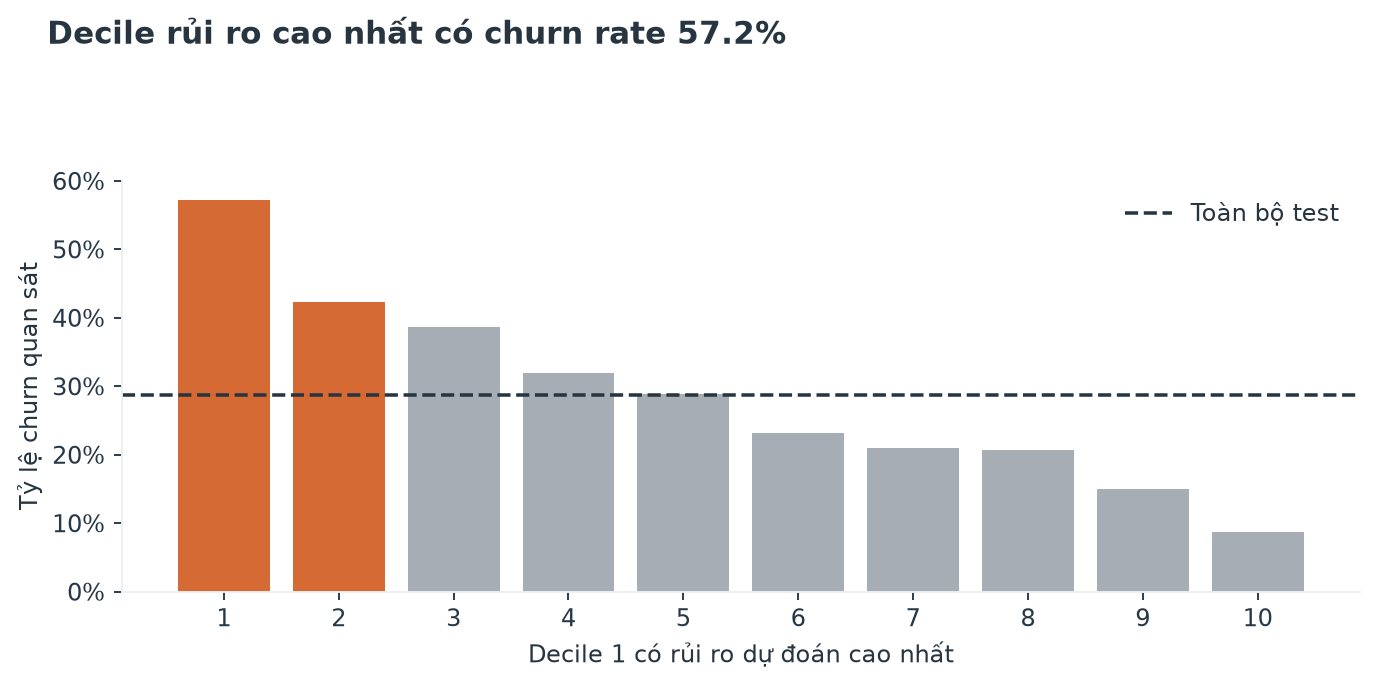

In [ ]:
_chart = next(c for c in model_charts if c['id'] == 'M08')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Decile 1 gồm 1,018 người và 582 churner; churn rate=57.2%.

**Business Meaning**

Kết hợp tỷ lệ churn với quy mô nhóm để đánh giá khả năng tập trung nguồn lực.

**Next Question**

Nhóm giá trị cao chiếm bao nhiêu trong decile đầu?

### M09 Top 20% rủi ro bao phủ 34.6% churner trên test

**Câu hỏi kinh doanh:** Tỷ lệ giữ chân tăng thêm trong thử nghiệm là bao nhiêu?

**Quyết định:** Đây là hiệu quả nhận diện; số được giữ chân và doanh thu tăng thêm phải đo bằng nhóm đối chứng.

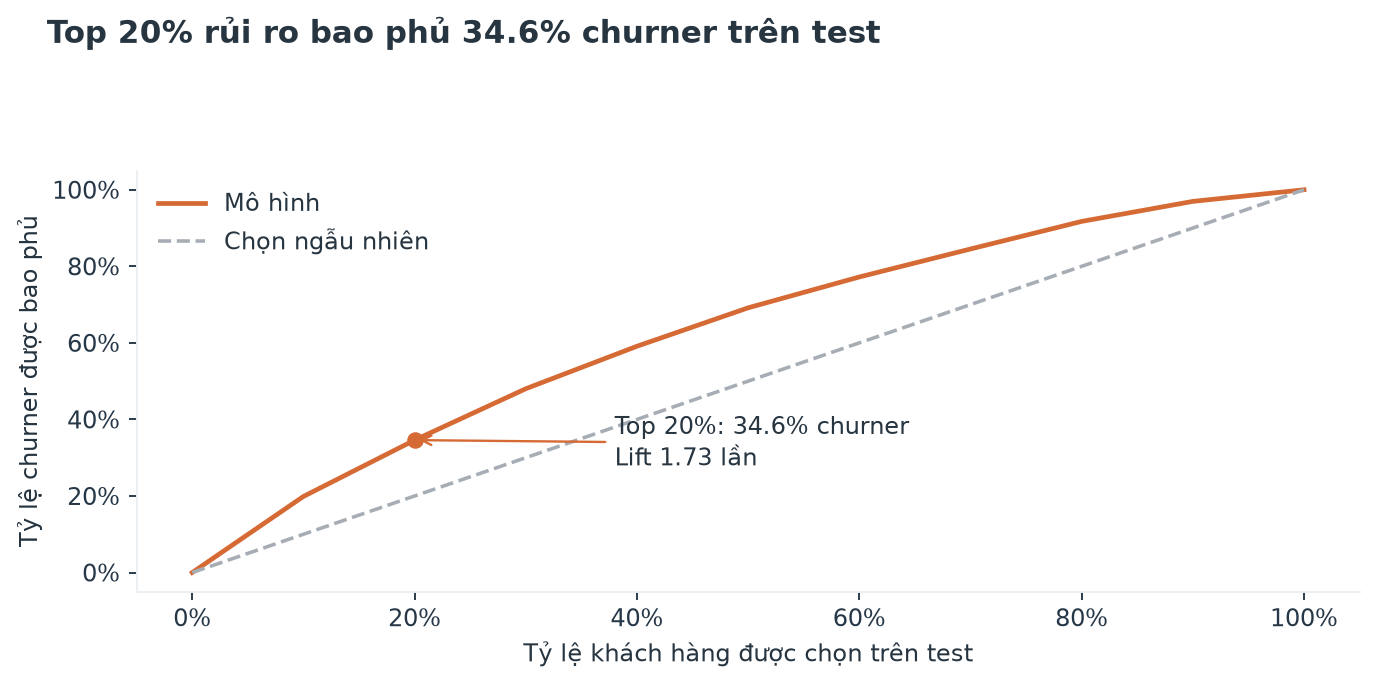

In [ ]:
_chart = next(c for c in model_charts if c['id'] == 'M09')
display(Image(filename=str(BASE / _chart['path'])))

**Insight**

Đội retention chọn 2,036 người sẽ bao phủ 1,013 churner đã quan sát trong test, lift 1.73 lần.

**Business Meaning**

Đây là hiệu quả nhận diện; số được giữ chân và doanh thu tăng thêm phải đo bằng nhóm đối chứng.

**Next Question**

Tỷ lệ giữ chân tăng thêm trong thử nghiệm là bao nhiêu?

## 11 Interactive Data Visualization

Thiết kế áp dụng Knaflic bằng tiêu đề kết luận từ kết quả, trục và nhãn trực tiếp, màu cam cho churn hoặc điểm cần chú ý, nền xám cho nhóm so sánh và hạn chế đường kẻ. Thiết kế theo Ward, Grinstein và Keim xác định nhiệm vụ tương tác trước: nhận diện bằng hover, so sánh nhóm, lọc theo dấu hiệu, chọn vùng để khám phá. Vị trí và độ dài mã hóa các so sánh định lượng; không dùng diện tích hoặc bảng màu cầu vồng để thay so sánh chính xác.

Biểu đồ tương tác có bản HTML tự chứa trong `output/interactive`. Các file này mở độc lập trong trình duyệt. Hover giúp kiểm tra hồ sơ, legend/menu lọc nhóm; zoom chỉ thay đổi vùng xem, không thay đổi mẫu số của bảng kết quả đã tính.

In [ ]:
# Bổ sung risk explorer khi file điểm đã được tạo.
interactive_records = visuals.make_interactive(pd.read_csv(BASE/'data/cell2cell_analysis.csv')) + visuals.add_risk_interactive()
visuals.write_json(BASE/'output/analysis/interactive_charts.json', interactive_records)
interactive = json.loads((BASE/'output/analysis/interactive_charts.json').read_text(encoding='utf-8'))
display(pd.DataFrame(interactive))

,id,slug,path,title,interaction_task,n_display,n_population,sampling,interpretation
0,I01,Usage_Behavior_Explorer,D:\trực quan\output\interactive\Usage_Behavior...,Khám phá mức sử dụng và doanh thu,Identify / compare / zoom / select,8000,50891,"Deterministic stratified by Churn, random_stat...",Quan hệ quan sát; các chỉ số PercChange không ...
1,I02,Early_Warning_Explorer,D:\trực quan\output\interactive\Early_Warning_...,Khám phá hai chỉ số thay đổi hành vi,Explore / filter / identify,8000,50891,"Deterministic stratified by Churn, random_stat...",Quan hệ quan sát; các chỉ số PercChange không ...
2,I03,Churn_Risk_Explorer,D:\trực quan\output\interactive\Churn_Risk_Exp...,Churn Risk Explorer,Filter / identify / select / zoom,8000,50891,NaN,NaN
3,I04,Risk_Distribution,D:\trực quan\output\interactive\Risk_Distribut...,Risk Distribution,Compare / filter / inspect bins,50891,50891,NaN,NaN


### I01 Khám phá mức sử dụng và doanh thu

**Interaction task:** Identify / compare / zoom / select

In [ ]:
_interactive = next(c for c in interactive if c['id'] == 'I01')
_interactive_path = Path(_interactive['path'])
_interactive_src = _interactive_path.relative_to(BASE).as_posix() if _interactive_path.is_absolute() else _interactive_path.as_posix()
display(IFrame(src=_interactive_src, width='100%', height=600))

### I02 Khám phá hai chỉ số thay đổi hành vi

**Interaction task:** Explore / filter / identify

In [ ]:
_interactive = next(c for c in interactive if c['id'] == 'I02')
_interactive_path = Path(_interactive['path'])
_interactive_src = _interactive_path.relative_to(BASE).as_posix() if _interactive_path.is_absolute() else _interactive_path.as_posix()
display(IFrame(src=_interactive_src, width='100%', height=600))

### I03 Churn Risk Explorer

**Interaction task:** Filter / identify / select / zoom

In [ ]:
_interactive = next(c for c in interactive if c['id'] == 'I03')
_interactive_path = Path(_interactive['path'])
_interactive_src = _interactive_path.relative_to(BASE).as_posix() if _interactive_path.is_absolute() else _interactive_path.as_posix()
display(IFrame(src=_interactive_src, width='100%', height=600))

### I04 Risk Distribution

**Interaction task:** Compare / filter / inspect bins

In [ ]:
_interactive = next(c for c in interactive if c['id'] == 'I04')
_interactive_path = Path(_interactive['path'])
_interactive_src = _interactive_path.relative_to(BASE).as_posix() if _interactive_path.is_absolute() else _interactive_path.as_posix()
display(IFrame(src=_interactive_src, width='100%', height=600))

## 12 Retention Strategies Business Recommendations và KPI

Đội retention nên bắt đầu từ nhóm giá trị cao và điểm rủi ro cao sau khi xác nhận trạng thái hiện tại. Chuyên viên cần kiểm tra dấu hiệu quan sát được trước khi lựa chọn giải pháp. Nhóm giảm sử dụng cần xác minh thay đổi nhu cầu và độ phù hợp gói cước; nhóm có thiết bị sử dụng lâu cần kiểm tra khả năng đáp ứng rồi mới tư vấn đổi thiết bị. Sự cố và lịch sử hỗ trợ cần được rà soát khi thực sự hiện diện, không mặc định nhiều cuộc gọi chăm sóc đồng nghĩa với churn.

Chính sách được triển khai theo chuỗi bằng chứng, khách hàng mục tiêu, can thiệp, lý do và KPI. Nhóm giá trị thấp hơn có thể dùng kênh tự động và chuyển chuyên viên khi phát hiện vấn đề. Nhóm điểm thấp tiếp tục được theo dõi và chăm sóc phù hợp nhu cầu. Chi phí offer và doanh thu được bảo vệ không thể suy ra chỉ từ churn probability.

Quy trình vận hành gồm cập nhật snapshot, kiểm tra chất lượng và tính sẵn có, chấm điểm, lọc trạng thái hoạt động, xếp ưu tiên theo năng lực, phân công chăm sóc, ghi nhận kết quả và đánh giá bằng nhóm đối chứng. Trước production cần kiểm tra calibration, drift và khả năng tái lập trên snapshot tiếp theo.

In [ ]:
kpi = pd.DataFrame([
    ['Churn rate','Số churn / số đủ điều kiện theo cùng cửa sổ','Theo kỳ nhãn'],
    ['Precision@k','Churner trong top k / khách trong top k','Mỗi kỳ đánh giá'],
    ['Capture@k','Churner trong top k / toàn bộ churner','Mỗi kỳ đánh giá'],
    ['Lift@k','Precision@k / churn rate toàn cohort','Mỗi kỳ đánh giá'],
    ['Offer acceptance','Người chấp nhận / người nhận offer hợp lệ','Theo chiến dịch'],
    ['Observed retained rate','Khách còn hoạt động / khách đủ điều kiện theo dõi','Theo cửa sổ kết quả'],
    ['Incremental retention lift','Retained rate treatment - retained rate control','Sau thử nghiệm'],
    ['Incremental saved customers','Incremental retention lift × số khách treatment','Sau thử nghiệm'],
    ['Cost per incremental save','Chi phí tăng thêm / incremental saved customers','Khi tác động tăng thêm dương'],
    ['Incremental revenue protected','Doanh thu trên khách treatment trừ control, điều chỉnh quy mô','Sau thử nghiệm'],
],columns=['KPI','Công thức','Tần suất'])
display(kpi)
kpi.to_csv(BASE/'output/analysis/kpi_framework.csv',index=False,encoding='utf-8-sig')

,KPI,Công thức,Tần suất
0,Churn rate,Số churn / số đủ điều kiện theo cùng cửa sổ,Theo kỳ nhãn
1,Precision@k,Churner trong top k / khách trong top k,Mỗi kỳ đánh giá
2,Capture@k,Churner trong top k / toàn bộ churner,Mỗi kỳ đánh giá
3,Lift@k,Precision@k / churn rate toàn cohort,Mỗi kỳ đánh giá
4,Offer acceptance,Người chấp nhận / người nhận offer hợp lệ,Theo chiến dịch
5,Observed retained rate,Khách còn hoạt động / khách đủ điều kiện theo dõi,Theo cửa sổ kết quả
6,Incremental retention lift,Retained rate treatment - retained rate control,Sau thử nghiệm
7,Incremental saved customers,Incremental retention lift × số khách treatment,Sau thử nghiệm
8,Cost per incremental save,Chi phí tăng thêm / incremental saved customers,Khi tác động tăng thêm dương
9,Incremental revenue protected,"Doanh thu trên khách treatment trừ control, đi...",Sau thử nghiệm


### Thiết kế thử nghiệm retention

Phân bổ ngẫu nhiên treatment và control trong các tầng rủi ro và giá trị đủ điều kiện. Cả hai nhóm phải có cùng ngày bắt đầu và cửa sổ theo dõi nhãn. Ghi nhận phân nhóm trước khi liên hệ và đánh giá theo intention to treat, kể cả khách không nghe máy. KPI chính là chênh lệch tỷ lệ duy trì giữa treatment và control cùng khoảng tin cậy; tỷ lệ chấp nhận offer chỉ là chỉ số quy trình.

Chọn mức tác động tối thiểu có ý nghĩa, cỡ mẫu và thời hạn theo dõi trước khi chạy dựa trên năng lực, baseline kỳ triển khai và ngân sách. Dữ liệu hiện tại chưa chứa phép phân bổ ngẫu nhiên nên không cung cấp bằng chứng rằng một offer cụ thể làm giảm churn. Hiệu quả targeting và hiệu quả can thiệp là hai câu hỏi phải được đo riêng.

## 13 Kết luận và giới hạn

Kết quả giúp xếp hạng và lựa chọn nhóm cần kiểm tra, nhưng không xác định chắc chắn khách nào sẽ rời bỏ hoặc ai có thể được giữ chân. Dữ liệu quan sát còn thiếu mốc thời gian, chi phí, đối thủ và thông tin nguyên nhân chi tiết. Các biến nhạy với mã hóa hoặc cơ chế thiếu cần được xác minh với chủ dữ liệu. Ưu tiên tiếp theo là chuẩn hóa snapshot trước sự kiện, thử nghiệm retention có đối chứng và theo dõi mô hình ở các kỳ mới.

### Tài liệu tham khảo

1. Empulse, tài liệu và mã nguồn `fetch_cell2cell`: https://empulse.readthedocs.io/en/latest/guide/datasets/cell2cell.html và https://empulse.readthedocs.io/en/latest/_modules/empulse/datasets/_remote.html
2. Cole Nussbaumer Knaflic, *Storytelling with Data*, 2015. Tài liệu được yêu cầu: https://luutruvn.com/wp-content/uploads/2025/03/Storytelling-with-Data_-A-Data-Visualization-Guide-for-Business-Professionals-PDFDrive-.pdf ; các nguyên tắc thiết kế được áp dụng và đối chiếu qua bản trích sách của nhà xuất bản: https://www.oreilly.com/library/view/storytelling-with-data/9781119002253/f_07.xhtml
3. Matthew O. Ward, Georges Grinstein, Daniel Keim, *Interactive Data Visualization: Foundations, Techniques, and Applications*, ấn bản 2, 2015. Trang tác giả: https://www.idvbook.com/index.html ; hướng dẫn thiết kế: https://davis.wpi.edu/~matt/projects/visbook/ch14.html

### Kiểm tra cuối và xuất file

Các assertion dưới kiểm tra quy mô, ánh xạ target, exclusion leakage, xác suất, tính duy nhất mã khách và artifact đã tạo. Báo cáo Word và PDF được tạo từ cùng JSON và CSV sau lần thực thi notebook thành công.

In [ ]:
import numpy as np
assert data_manifest['loader_rows'] == len(frame)
assert int(frame.Churn.sum()) == data_manifest['churn_count']
x_check, _ = models.feature_engineering(frame)
assert not set(['CustomerID','ServiceArea','RetentionCalls','RetentionOffersAccepted','MadeCallToRetentionTeam','Churn']).intersection(x_check.columns)
assert model_summary['splits']['test']['n'] == len(pd.read_csv(BASE/'output/analysis/predictions_test.csv'))
assert sum(v['n'] for v in model_summary['splits'].values()) == len(frame)
for key,file in [('raw_sha256','data/cell2cell_raw.csv'),('analysis_sha256','data/cell2cell_analysis.csv')]:
    assert hashlib.sha256((BASE/file).read_bytes()).hexdigest() == data_manifest[key]
assert len(eda_charts)==30 and len(model_charts)==11 and len(interactive)==4
for chart in eda_charts+model_charts+interactive:
    assert (BASE/chart['path']).is_file(), chart['path']
assert (BASE/'Cell2Cell_Churn_Risk_Scores.csv').is_file()
print('PASS: raw audit, target, split, leakage exclusions, scores, 41 static charts và 4 interactive explorers.')

PASS: raw audit, target, split, leakage exclusions, scores, 41 static charts và 4 interactive explorers.
